# Text-to-SQL Agent for Clinical Questions over MIMIC-IV

**AI 380H: AI in Healthcare · Final Project · Michael Allee**

This notebook builds and evaluates an agent that turns plain-English clinical questions into SQL, runs the SQL against a local copy of MIMIC-IV (v3.1) and MIMIC-IV-Note (v2.2), and returns the result. When the data cannot support a question, the agent can decline instead of guessing.

**Pipeline**

1. Convert the MIMIC `.csv.gz` files into a local DuckDB database (one-time step).
2. Build a schema catalog: table descriptions, column types, and the common values of categorical columns.
3. For each question, the agent:
   - links the question to a subset of tables (keyword retrieval, an LLM pass, or the full schema);
   - assembles a prompt from rules, domain notes, worked examples, the schema, and value hints drawn from the dictionary tables;
   - asks a local LLM for SQL and executes it read-only;
   - feeds errors back to the model for self-correction.
4. Evaluate against a hand-written benchmark of questions with gold-standard SQL:
   - an ablation ladder that adds one component at a time;
   - error-driven repairs, tested on held-out questions;
   - schema-linking variants;
   - a paraphrase robustness set;
   - latency analysis on CPU.
5. Export figures and LaTeX tables.

**How the notebook runs.** It runs top to bottom.
- Every long step is controlled by a flag in the **run plan** at the end of the configuration cell.
- Experiments resume where they stopped and skip finished work. A slow or timed-out model call is reported and skipped rather than stopping the notebook.
- The analysis sections work on whatever results have been logged.
- Section 15 collects every reported number in `results/report_summary.md`.

**Data use.** MIMIC-IV is credentialed data under the PhysioNet Data Use Agreement. All model inference runs locally through Ollama, so no records leave the machine. The benchmark answers and the saved tables, figures and summary contain only aggregate results: counts, averages and category names.


## 1. Setup

Software:
- **Python packages:** `duckdb`, `pandas`, `numpy`, `requests`, `matplotlib`.
- **Ollama** with the `qwen2.5-coder:7b` model (`ollama pull qwen2.5-coder:7b`).

Small code-tuned models are the practical choice on CPU.


In [1]:
import csv
import dataclasses
import difflib
import gzip
import hashlib
import json
import math
import os
import platform
import re
import sys
import threading
import time
from collections import Counter
from dataclasses import dataclass, field
from datetime import date, datetime
from decimal import Decimal
from functools import lru_cache
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
print("python", platform.python_version(), "| duckdb", duckdb.__version__, "| pandas", pd.__version__)

python 3.13.9 | duckdb 2.0.1 | pandas 2.2.3


In [2]:
# ---------------- Data locations ----------------
MIMIC_IV_DIR = Path(r"G:\My Drive\Python\MSDS\AI 380H AI in Healthcare\Data\mimic-iv-3.1")
MIMIC_NOTE_DIR = Path(r"G:\My Drive\Python\MSDS\AI 380H AI in Healthcare\Data\mimic-iv-note-deidentified-free-text-clinical-notes-2.2")
INCLUDE_NOTES = True

# DuckDB database file, on a local disk outside Google Drive because it is many GB.
DB_PATH = Path.home() / "mimic_duckdb" / "mimic_iv_3_1.duckdb"
DUCKDB_TEMP_DIR = DB_PATH.parent / "tmp"
BUILD_MEMORY_LIMIT = "4GB"    # used only while building the database
DUCKDB_MEMORY_LIMIT = "1GB"   # query-time limit; kept low so DuckDB doesn't compete with the LLM for RAM
DUCKDB_THREADS = 4
SHOW_PROGRESS_BAR = False     # DuckDB progress widgets clutter saved outputs and do not render on GitHub
SKIP_TABLES = set()           # e.g. {"chartevents"} to save build time and disk space
REBUILD = False               # True rebuilds tables that already exist

# ---------------- Outputs ----------------
OUTPUT_DIR = Path.cwd() / "results"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"

# ---------------- Local LLM (Ollama) ----------------
OLLAMA_URL = "http://localhost:11434"
MODEL = "qwen2.5-coder:7b"
NUM_CTX = 8192                # fits every condition, including the full schema (~4,600 tokens) plus retries
MAX_OUTPUT_TOKENS = 512       # caps runaway generations (each output token is slow on CPU)
KEEP_ALIVE = "2h"             # keep the model loaded between cells (Ollama's default unloads after 5 min)
LLM_TIMEOUT_S = 1800          # a single call slower than this is recorded as a timeout and skipped

# ---------------- Agent ----------------
DEFAULT_SCHEMA_MODE = "retrieve"   # "retrieve" (keyword schema linking), "select" (LLM picks tables) or "full"
RETRIEVE_TOP_K = 6                 # tables kept by retrieval, before core and dictionary tables are added

# ---------------- Query execution ----------------
QUERY_TIMEOUT_S = 300         # agent queries are cancelled after this (a full-text scan of notes takes ~2 min)
GOLD_TIMEOUT_S = 900
MAX_RESULT_ROWS = 1000

# ---------------- Run plan: what Run All spends model time on ----------------
# Times were measured on this project's laptop (4 CPU cores, no GPU, ~20-45 s per question). Each phase
# prints its own estimate before starting. Phases resume where they stopped and skip finished work.
RUN_SPEED_PROBE = True        # ~2 min: measures prompt/generation speed
RUN_DEMOS = True              # ~5 min: two example questions (Section 9)
RUN_CACHE_CHECK = True        # runs once, then reads its saved result
RUN_SMOKE = True              # ~5 min: 4 benchmark questions with the full agent
RUN_PHASE_A = True            # ~2 h: full agent (C4) and baseline (C0) on all 64 questions
RUN_PHASE_B = True            # ~1.5 h: ladder middle (C1-C3) on the 44 core questions
RUN_PHASE_C = True            # ~2 h: error-driven repairs (C5, C6) on all 64 questions
RUN_PHASE_D = True            # ~1 h: schema-linking variants (S1, S2) on a 16-question subset
RUN_PHASE_E = False           # optional, not run: a second, smaller model on the ladder ends
LINKING_RECALL_MIN = 0.95     # phases are skipped if table linking misses tables for too many questions

for folder in (DB_PATH.parent, DUCKDB_TEMP_DIR, OUTPUT_DIR, FIGURE_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("MIMIC-IV folder found:     ", MIMIC_IV_DIR.exists())
print("MIMIC-IV-Note folder found:", MIMIC_NOTE_DIR.exists())
print("DuckDB file:", DB_PATH, "(exists)" if DB_PATH.exists() else "(will be created)")

MIMIC-IV folder found:      True
MIMIC-IV-Note folder found: True
DuckDB file: C:\Users\micha\mimic_duckdb\mimic_iv_3_1.duckdb (exists)


## 2. Build the local DuckDB database (one-time)

Each `.csv.gz` file is loaded once into a DuckDB table under the `mimiciv_hosp`, `mimiciv_icu` and `mimiciv_note` schemas. These names match the official MIMIC-IV builds, so they also match what LLMs have seen in public MIMIC code.

Finished tables are skipped on later runs. The first build took about 50 minutes.

**Column types.** Code columns are forced to text: ICD codes like `0389` need their leading zero. If type detection fails for a table, the loader retries with a full-file scan; this happened for `emar_detail` and `pharmacy`.

In [3]:
SCHEMA_FOR_FOLDER = {"hosp": "mimiciv_hosp", "icu": "mimiciv_icu", "note": "mimiciv_note"}

# Columns that look numeric early in a file but must stay text
TEXT_COLUMNS_ANY_TABLE = {"icd_code", "ndc", "drg_code", "hcpcs_cd", "gsn", "formulary_drug_cd", "poe_id"}
TEXT_COLUMNS_BY_TABLE = {
    "labevents": {"value", "valueuom", "flag", "priority", "comments"},
    "chartevents": {"value", "valueuom"},
    "omr": {"result_value"},
    "d_hcpcs": {"code"},
    "microbiologyevents": {"quantity", "dilution_text", "comments"},
}


def sql_literal(text):
    return "'" + str(text).replace("'", "''") + "'"


def discover_csv_files():
    """Return (schema, table, path) for every MIMIC .csv.gz file found."""
    found = []
    for path in sorted(MIMIC_IV_DIR.rglob("*.csv.gz")):
        schema = SCHEMA_FOR_FOLDER.get(path.parent.name)
        if schema in ("mimiciv_hosp", "mimiciv_icu"):
            found.append((schema, path.name[: -len(".csv.gz")], path))
    if INCLUDE_NOTES and MIMIC_NOTE_DIR.exists():
        for path in sorted(MIMIC_NOTE_DIR.rglob("*.csv.gz")):
            found.append(("mimiciv_note", path.name[: -len(".csv.gz")], path))
    return [f for f in found if f[1] not in SKIP_TABLES]


def read_header(path):
    with gzip.open(path, "rt", encoding="utf-8", newline="") as fh:
        return next(csv.reader(fh))


def read_csv_sql(path, table, sample_size, all_varchar=False):
    options = ["header=true", f"sample_size={sample_size}"]
    if all_varchar:
        options.append("all_varchar=true")
    else:
        forced = (TEXT_COLUMNS_ANY_TABLE | TEXT_COLUMNS_BY_TABLE.get(table, set())) & set(read_header(path))
        if forced:
            options.append("types={" + ", ".join(f"{sql_literal(c)}: 'VARCHAR'" for c in sorted(forced)) + "}")
    return f"SELECT * FROM read_csv({sql_literal(path.as_posix())}, {', '.join(options)})"


def build_database():
    files = discover_csv_files()
    if not files:
        raise FileNotFoundError("No .csv.gz files found. Check MIMIC_IV_DIR and MIMIC_NOTE_DIR.")
    log = []
    with duckdb.connect(str(DB_PATH)) as build_con:
        build_con.execute(f"SET memory_limit = {sql_literal(BUILD_MEMORY_LIMIT)}")
        build_con.execute(f"SET threads = {int(DUCKDB_THREADS)}")
        build_con.execute(f"SET temp_directory = {sql_literal(DUCKDB_TEMP_DIR.as_posix())}")
        build_con.execute("SET preserve_insertion_order = false")
        build_con.execute(f"SET enable_progress_bar = {str(SHOW_PROGRESS_BAR).lower()}")
        for schema in sorted({f[0] for f in files}):
            build_con.execute(f"CREATE SCHEMA IF NOT EXISTS {schema}")
        built = set(build_con.execute(
            "SELECT table_schema, table_name FROM information_schema.tables").fetchall())

        for i, (schema, table, path) in enumerate(files, 1):
            label = f"[{i}/{len(files)}] {schema}.{table}"
            if (schema, table) in built and not REBUILD:
                print(f"{label}: already built, skipping")
                continue
            print(f"{label}: loading {path.stat().st_size / 1e6:,.0f} MB compressed ...", end=" ", flush=True)
            t0 = time.perf_counter()
            loaded_with = None
            attempts = [("sampled", {"sample_size": 200_000}),
                        ("full-scan", {"sample_size": -1}),
                        ("all-text", {"sample_size": -1, "all_varchar": True})]
            for mode, kwargs in attempts:
                try:
                    build_con.execute(f"CREATE OR REPLACE TABLE {schema}.{table} AS "
                                      + read_csv_sql(path, table, **kwargs))
                    loaded_with = mode
                    break
                except duckdb.Error as exc:
                    # Only the error type and line number are printed: DuckDB's message quotes the offending CSV
                    # line, which is a row of patient data and must not appear in saved outputs.
                    line = re.search(r"CSV Error on Line: (\d+)", str(exc))
                    where = f" at line {int(line.group(1)):,}" if line else ""
                    print(f"\n    type detection '{mode}' failed ({type(exc).__name__}{where}); retrying", end=" ")
            if loaded_with is None:
                print("FAILED")
                continue
            n_rows = build_con.execute(f"SELECT COUNT(*) FROM {schema}.{table}").fetchone()[0]
            minutes = (time.perf_counter() - t0) / 60
            warn = "  <-- WARNING: all columns stored as text" if loaded_with == "all-text" else ""
            print(f"{n_rows:,} rows in {minutes:.1f} min{warn}")
            log.append({"schema": schema, "table": table, "rows": n_rows,
                        "minutes": round(minutes, 2), "type_detection": loaded_with})
    if log:
        log_path = OUTPUT_DIR / "build_log.csv"
        pd.DataFrame(log).to_csv(log_path, mode="a", header=not log_path.exists(), index=False)
    print("Done.")

In [4]:
# A write connection and a read-only connection can't share the file in one process,
# so close the analysis connection (if open) before building.
if "con" in globals():
    try:
        con.close()
    except Exception:
        pass

build_database()

[1/35] mimiciv_hosp.admissions: already built, skipping
[2/35] mimiciv_hosp.d_hcpcs: already built, skipping
[3/35] mimiciv_hosp.d_icd_diagnoses: already built, skipping
[4/35] mimiciv_hosp.d_icd_procedures: already built, skipping
[5/35] mimiciv_hosp.d_labitems: already built, skipping
[6/35] mimiciv_hosp.diagnoses_icd: already built, skipping
[7/35] mimiciv_hosp.drgcodes: already built, skipping
[8/35] mimiciv_hosp.emar: already built, skipping
[9/35] mimiciv_hosp.emar_detail: already built, skipping
[10/35] mimiciv_hosp.hcpcsevents: already built, skipping
[11/35] mimiciv_hosp.labevents: already built, skipping
[12/35] mimiciv_hosp.microbiologyevents: already built, skipping
[13/35] mimiciv_hosp.omr: already built, skipping
[14/35] mimiciv_hosp.patients: already built, skipping
[15/35] mimiciv_hosp.pharmacy: already built, skipping
[16/35] mimiciv_hosp.poe: already built, skipping
[17/35] mimiciv_hosp.poe_detail: already built, skipping
[18/35] mimiciv_hosp.prescriptions: already bu

## 3. Connect read-only and inspect the database

The agent's connection is read-only with DuckDB's external file access switched off. A read-only connection can otherwise still write files with `COPY ... TO`. Large queries can still spill to the temp folder.

In [5]:
def open_readonly():
    connection = duckdb.connect(str(DB_PATH), read_only=True, config={
        "memory_limit": DUCKDB_MEMORY_LIMIT, "threads": DUCKDB_THREADS,
        "temp_directory": DUCKDB_TEMP_DIR.as_posix(), "preserve_insertion_order": False})
    connection.execute(f"SET enable_progress_bar = {str(SHOW_PROGRESS_BAR).lower()}")
    try:
        # Set last: once disabled, temp-directory settings can no longer be changed.
        connection.execute("SET enable_external_access = false")
    except duckdb.Error as exc:
        print("Note: could not disable external file access:", exc)
    return connection


con = open_readonly()
inventory = con.execute("""
    SELECT schema_name AS schema, table_name AS "table", estimated_size AS approx_rows, column_count AS columns
    FROM duckdb_tables()
    ORDER BY schema_name, table_name
""").df()
print(f"{len(inventory)} tables, ~{inventory.approx_rows.sum():,} rows in total")
inventory

35 tables, ~894,928,443 rows in total


,schema,table,approx_rows,columns
0,mimiciv_hosp,admissions,546028,16
1,mimiciv_hosp,d_hcpcs,89208,4
2,mimiciv_hosp,d_icd_diagnoses,112107,3
3,mimiciv_hosp,d_icd_procedures,86423,3
4,mimiciv_hosp,d_labitems,1650,4
5,mimiciv_hosp,diagnoses_icd,6364488,5
6,mimiciv_hosp,drgcodes,761856,7
7,mimiciv_hosp,emar,42808593,12
8,mimiciv_hosp,emar_detail,87371064,33
9,mimiciv_hosp,hcpcsevents,186074,6


## 4. Schema catalog

Each table gets a one-line description and a compact column list. Low-cardinality text columns also get their most common values, because exact strings like `'Medical Intensive Care Unit (MICU)'` are a frequent reason that generated SQL runs but returns nothing.

In [6]:
TABLE_DESCRIPTIONS = {
    # hosp
    "admissions": "One row per hospital admission (hadm_id): admit/discharge/death times, admission type and location, discharge location, insurance, language, marital status, race, ED registration time (edregtime), hospital_expire_flag (1 = died in hospital).",
    "patients": "One row per patient (subject_id): gender, anchor_age (age in anchor_year), anchor_year, anchor_year_group, dod (date of death).",
    "diagnoses_icd": "ICD-9/ICD-10 diagnosis codes billed for each admission; seq_num 1 = primary diagnosis.",
    "d_icd_diagnoses": "Dictionary of ICD diagnosis codes with long_title descriptions.",
    "procedures_icd": "ICD-9/ICD-10 procedure codes for each admission, with chartdate.",
    "d_icd_procedures": "Dictionary of ICD procedure codes with long_title descriptions.",
    "labevents": "Laboratory results (very large): itemid, charttime, value (text), valuenum (numeric), valueuom, reference ranges, flag ('abnormal' or NULL).",
    "d_labitems": "Dictionary of lab itemids: label (test name), fluid (e.g., Blood, Urine), category.",
    "prescriptions": "Medication orders: drug name, drug_type, start/stop times, dose, route.",
    "pharmacy": "Pharmacy dispensing details for medication orders.",
    "emar": "Electronic medication administration record: one row per administration event (medication, event_txt such as 'Administered', charttime).",
    "emar_detail": "Details of each eMAR administration (dose given, route, etc.).",
    "poe": "Provider order entry: every order with order_type, order_subtype, ordertime.",
    "poe_detail": "Extra key/value details for orders in poe.",
    "microbiologyevents": "Microbiology cultures: specimen type (spec_type_desc), test, organism (org_name), antibiotic susceptibility (ab_name, interpretation).",
    "transfers": "Patient movements between hospital units: eventtype (admit/transfer/discharge/ED), careunit, intime, outtime.",
    "services": "Hospital service (e.g., MED, SURG, CMED) the patient was under; curr_service with transfertime.",
    "drgcodes": "Diagnosis-related group (DRG) codes per admission with description, severity, mortality.",
    "hcpcsevents": "HCPCS billing codes for services/procedures per admission.",
    "d_hcpcs": "Dictionary of HCPCS codes.",
    "omr": "Outpatient measurements: result_name (e.g., 'Blood Pressure', 'Weight (Lbs)', 'BMI (kg/m2)') with result_value stored as text.",
    "provider": "List of de-identified provider_id values (no names).",
    # icu
    "icustays": "One row per ICU stay (stay_id): first/last care unit, intime, outtime, los (length of stay in fractional days).",
    "chartevents": "Charted ICU observations (very large): vital signs and other measurements; itemid joins to d_items; value/valuenum/valueuom.",
    "d_items": "Dictionary of ICU itemids: label, abbreviation, category, unitname, linksto (the event table that uses the itemid).",
    "inputevents": "ICU fluid and medication inputs such as infusions and vasopressors: itemid (joins to d_items), amount, rate, start/end times.",
    "ingredientevents": "Ingredient-level components (e.g., water, calories) of ICU inputs.",
    "outputevents": "ICU outputs such as urine output (value with valueuom).",
    "procedureevents": "ICU procedures such as ventilation, lines, dialysis, with start/end times.",
    "datetimeevents": "ICU observations whose value is a date/time.",
    "caregiver": "List of de-identified ICU caregiver_id values (no names).",
    # note
    "discharge": "Free-text discharge summaries (note_id) linked to subject_id and hadm_id; the note is in the text column.",
    "discharge_detail": "Key/value metadata for discharge summaries (field_name, field_value).",
    "radiology": "Free-text radiology reports with charttime; the report is in the text column.",
    "radiology_detail": "Key/value metadata for radiology reports: field_name (e.g., exam_name, exam_code, cpt_code) and field_value.",
}

TYPE_SHORT = {"VARCHAR": "text", "BIGINT": "int", "INTEGER": "int", "SMALLINT": "int", "TINYINT": "int",
              "HUGEINT": "int", "DOUBLE": "float", "FLOAT": "float", "DECIMAL": "float",
              "TIMESTAMP": "timestamp", "DATE": "date", "BOOLEAN": "bool", "TIME": "time"}


def short_type(dtype):
    return TYPE_SHORT.get(dtype.split("(")[0].upper(), dtype.lower())


def load_catalog(connection):
    rows = connection.execute("""
        SELECT table_schema, table_name, column_name, data_type
        FROM information_schema.columns
        WHERE table_schema IN ('mimiciv_hosp', 'mimiciv_icu', 'mimiciv_note')
        ORDER BY table_schema, table_name, ordinal_position
    """).fetchall()
    catalog = {}
    for schema, table, column, dtype in rows:
        entry = catalog.setdefault(f"{schema}.{table}", {
            "schema": schema, "table": table,
            "description": TABLE_DESCRIPTIONS.get(table, ""), "columns": []})
        entry["columns"].append((column, short_type(dtype)))
    return catalog


CATALOG = load_catalog(con)
TABLE_KEY_BY_NAME = {v["table"]: k for k, v in CATALOG.items()}
print(f"{len(CATALOG)} tables, {sum(len(v['columns']) for v in CATALOG.values())} columns in the catalog")

35 tables, 368 columns in the catalog


In [7]:
CATEGORICAL_COLUMNS = {
    "mimiciv_hosp.patients": ["gender", "anchor_year_group"],
    "mimiciv_hosp.admissions": ["admission_type", "admission_location", "discharge_location",
                                "insurance", "language", "marital_status", "race"],
    "mimiciv_hosp.transfers": ["eventtype", "careunit"],
    "mimiciv_hosp.services": ["curr_service"],
    "mimiciv_hosp.d_labitems": ["fluid", "category"],
    "mimiciv_hosp.prescriptions": ["drug_type", "route"],
    "mimiciv_hosp.emar": ["event_txt"],
    "mimiciv_hosp.microbiologyevents": ["spec_type_desc"],
    "mimiciv_hosp.omr": ["result_name"],
    "mimiciv_icu.icustays": ["first_careunit", "last_careunit"],
    "mimiciv_icu.d_items": ["category", "linksto"],
    "mimiciv_note.discharge": ["note_type"],
    "mimiciv_note.radiology": ["note_type"],
    "mimiciv_note.discharge_detail": ["field_name"],
    "mimiciv_note.radiology_detail": ["field_name"],
}
MAX_CATEGORY_VALUES = 25


def load_categorical_values(connection, refresh=False):
    """Most common values of selected text columns, cached; new columns are added on later runs."""
    cache = OUTPUT_DIR / "categorical_values.json"
    values = json.loads(cache.read_text(encoding="utf-8")) if cache.exists() and not refresh else {}
    changed = False
    for key, columns in CATEGORICAL_COLUMNS.items():
        if key not in CATALOG:
            continue
        present = {c for c, _ in CATALOG[key]["columns"]}
        for col in (c for c in columns if c in present):
            if f"{key}.{col}" in values:
                continue
            rows = connection.execute(
                f"SELECT {col}, COUNT(*) AS n FROM {key} WHERE {col} IS NOT NULL "
                f"GROUP BY {col} ORDER BY n DESC LIMIT {MAX_CATEGORY_VALUES + 1}").fetchall()
            values[f"{key}.{col}"] = {"values": [str(r[0]) for r in rows[:MAX_CATEGORY_VALUES]],
                                      "truncated": len(rows) > MAX_CATEGORY_VALUES}
            changed = True
    if changed:
        cache.write_text(json.dumps(values, indent=2), encoding="utf-8")
    return values


CATEGORICAL_VALUES = load_categorical_values(con)
print(f"Common values cached for {len(CATEGORICAL_VALUES)} columns")

Common values cached for 27 columns


## 5. Local LLM client (Ollama)

Every call records Ollama's timing breakdown:
- **model load time;**
- **prompt tokens:** in this Ollama version (0.40) the count includes tokens reused from the prompt cache, so cache reuse shows up as shorter prompt-processing *time*, not as a smaller count;
- **prompt-processing time;**
- **generated tokens and generation time.**

These feed the latency analysis. On CPU, prompt processing dominates, so prompt size is the main cost driver.

**Observations from the experiment runs** (a 4-core laptop with 12.8 GB of RAM and no GPU).
- **Prompt reuse works.** Two prompts sharing a ~1,100-token prefix took 7.2 s and then 1.4 s to process. The static parts of the prompt (rules, domain notes, examples) therefore come first.
- **Throughput varies a lot with free memory.**

  | Measurement | Prompt processing | Generation |
  |---|---|---|
  | Speed probe, taken right after the model loaded (0.3 GB of RAM free) | 8 tok/s | 0.5 tok/s |
  | Smoke test, a few minutes later | 30–100 tok/s | 0.5–2.4 tok/s |

  Runtime estimates therefore use the throughput measured in logged runs once there are any.
- **Generation is the bottleneck.** At 1–2 tokens/s, a 40-token SQL query takes 20–40 s. That is why `MAX_OUTPUT_TOKENS` is capped and the prompt asks for SQL only.
- **Model loading** took up to 115 s, again a sign of memory pressure. The experiments ran with cloud file sync paused, because throughput depends so heavily on free memory.


In [8]:
@dataclass
class LLMReply:
    text: str
    prompt_tokens: int          # prompt tokens actually evaluated (cached prefix tokens are excluded)
    output_tokens: int
    seconds: float              # wall-clock time of the request
    load_s: float = 0.0
    prompt_eval_s: float = 0.0
    gen_s: float = 0.0
    est_prompt_tokens: int = 0  # rough size of the full prompt (chars / 3)


def estimate_tokens(messages):
    # measured on this schema: ~4 characters per token (11.5k chars -> 2,885 tokens); 3.6 errs on the high side
    return int(sum(len(m["content"]) for m in messages) / 3.6)


def chat(messages, model=None, temperature=0.0, num_ctx=None, num_predict=None):
    num_ctx = num_ctx or NUM_CTX
    est = estimate_tokens(messages)
    if est > 0.9 * num_ctx:
        print(f"  warning: prompt is ~{est:,} tokens, close to NUM_CTX={num_ctx:,}; Ollama may truncate it")
    payload = {"model": model or MODEL, "messages": messages, "stream": False, "keep_alive": KEEP_ALIVE,
               "options": {"temperature": temperature, "num_ctx": num_ctx, "seed": 42,
                           "num_predict": num_predict or MAX_OUTPUT_TOKENS}}
    t0 = time.perf_counter()
    response = requests.post(f"{OLLAMA_URL}/api/chat", json=payload, timeout=(10, LLM_TIMEOUT_S))
    response.raise_for_status()
    data = response.json()
    ns = lambda key: (data.get(key) or 0) / 1e9
    return LLMReply(text=data.get("message", {}).get("content", ""),
                    prompt_tokens=data.get("prompt_eval_count") or 0,
                    output_tokens=data.get("eval_count") or 0,
                    seconds=time.perf_counter() - t0,
                    load_s=ns("load_duration"), prompt_eval_s=ns("prompt_eval_duration"),
                    gen_s=ns("eval_duration"), est_prompt_tokens=est)


def check_ollama():
    try:
        tags = requests.get(f"{OLLAMA_URL}/api/tags", timeout=10).json()
    except requests.RequestException as exc:
        print(f"Ollama is not reachable at {OLLAMA_URL}: {exc}")
        print("Start the Ollama app (or run `ollama serve`) and re-run this cell.")
        return False
    names = [m.get("name", "") for m in tags.get("models", [])]
    print("Installed models:", ", ".join(names) or "(none)")
    if MODEL not in names and f"{MODEL}:latest" not in names:
        print(f"Model '{MODEL}' is not installed. Run: ollama pull {MODEL}")
        return False
    try:
        reply = chat([{"role": "user", "content": "Reply with the single word: ready"}], num_predict=8)
    except requests.RequestException as exc:
        print(f"The test call failed ({type(exc).__name__}). Model-dependent cells will be skipped.")
        return False
    print(f"Test reply: {reply.text.strip()!r} in {reply.seconds:.1f} s (of which model load {reply.load_s:.1f} s)")
    if reply.seconds > 120:
        print("  That is slow for a one-word reply: the machine may be short on free RAM or power-throttled.")
    return True


OLLAMA_READY = check_ollama()

Installed models: qwen2.5-coder:7b
Test reply: 'ready' in 2.3 s (of which model load 0.0 s)


In [9]:
def system_memory_gb():
    """(total, available) physical RAM in GB, or (None, None) if it can't be read."""
    try:
        import psutil
        vm = psutil.virtual_memory()
        return vm.total / 1e9, vm.available / 1e9
    except ImportError:
        pass
    if sys.platform == "win32":
        import ctypes

        class MemoryStatus(ctypes.Structure):
            _fields_ = [("dwLength", ctypes.c_ulong), ("dwMemoryLoad", ctypes.c_ulong),
                        ("ullTotalPhys", ctypes.c_ulonglong), ("ullAvailPhys", ctypes.c_ulonglong),
                        ("ullTotalPageFile", ctypes.c_ulonglong), ("ullAvailPageFile", ctypes.c_ulonglong),
                        ("ullTotalVirtual", ctypes.c_ulonglong), ("ullAvailVirtual", ctypes.c_ulonglong),
                        ("ullAvailExtendedVirtual", ctypes.c_ulonglong)]

        status = MemoryStatus()
        status.dwLength = ctypes.sizeof(MemoryStatus)
        if ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(status)):
            return status.ullTotalPhys / 1e9, status.ullAvailPhys / 1e9
        return None, None
    try:
        info = dict(line.split(":", 1) for line in Path("/proc/meminfo").read_text().splitlines())
        kb = lambda key: float(info[key].split()[0])
        return kb("MemTotal") / 1e6, kb("MemAvailable") / 1e6
    except Exception:
        return None, None


def report_resources():
    total, available = system_memory_gb()
    if total:
        print(f"RAM: {total:.1f} GB total, {available:.1f} GB available")
    try:
        loaded = requests.get(f"{OLLAMA_URL}/api/ps", timeout=10).json().get("models", [])
        for m in loaded:
            print(f"Ollama has {m.get('name')} loaded: {m.get('size', 0) / 1e9:.1f} GB in memory")
    except requests.RequestException:
        pass
    if available is not None and available < 2:
        print("Less than 2 GB of RAM is free. The model may be paging to disk, which makes every call much slower.")


SPEED_FILE = OUTPUT_DIR / "speed_probe.json"


def speed_probe():
    """Measure prompt-processing and generation speed with a ~600-token prompt."""
    filler = " ".join(TABLE_DESCRIPTIONS.values())[:2400]
    messages = [{"role": "user", "content": f"Probe {time.time():.0f}. Table notes: {filler}\n\n"
                                            "In one short sentence, what kind of database is this?"}]
    reply = chat(messages, num_predict=40)
    result = {"timestamp": datetime.now().isoformat(timespec="seconds"), "model": MODEL,
              "prompt_tokens": reply.prompt_tokens, "prompt_tok_s": reply.prompt_tokens / max(reply.prompt_eval_s, 1e-6),
              "gen_tokens": reply.output_tokens, "gen_tok_s": reply.output_tokens / max(reply.gen_s, 1e-6),
              "load_s": reply.load_s, "total_s": reply.seconds}
    history = json.loads(SPEED_FILE.read_text(encoding="utf-8")) if SPEED_FILE.exists() else []
    SPEED_FILE.write_text(json.dumps(history + [result], indent=2), encoding="utf-8")
    return result


def latest_speed():
    if not SPEED_FILE.exists():
        return None
    history = [h for h in json.loads(SPEED_FILE.read_text(encoding="utf-8")) if h["model"] == MODEL]
    return history[-1] if history else None


report_resources()
SPEED = None
if OLLAMA_READY and RUN_SPEED_PROBE:
    try:
        SPEED = speed_probe()
    except requests.RequestException as exc:
        print(f"Speed probe failed ({type(exc).__name__}); estimates will use the last saved probe or defaults.")
SPEED = SPEED or latest_speed()
if SPEED:
    print(f"Speed probe: prompt processing {SPEED['prompt_tok_s']:.1f} tok/s, generation {SPEED['gen_tok_s']:.1f} tok/s "
          f"(measured {SPEED['timestamp']}).")
    print(f"At this speed a 1,300-token prompt takes ~{1300 / SPEED['prompt_tok_s'] / 60:.1f} min "
          f"and a full-schema prompt (~4,600 tokens) ~{4600 / SPEED['prompt_tok_s'] / 60:.1f} min.")
    print("This is a snapshot: speed rises as Windows frees memory. Once runs are logged, estimates use their speed.")

RAM: 24.8 GB total, 4.2 GB available
Ollama has qwen2.5-coder:7b loaded: 5.1 GB in memory
Speed probe: prompt processing 227.6 tok/s, generation 12.8 tok/s (measured 2026-11-25T16:51:30).
At this speed a 1,300-token prompt takes ~0.1 min and a full-schema prompt (~4,600 tokens) ~0.3 min.
This is a snapshot: speed rises as Windows frees memory. Once runs are logged, estimates use their speed.


In [10]:
def capture_environment():
    """Record software, hardware and model details of the current session."""
    env = {"timestamp": datetime.now().isoformat(timespec="seconds"),
           "python": platform.python_version(), "platform": platform.platform(),
           "processor": platform.processor(), "cpu_count": os.cpu_count(),
           "duckdb": duckdb.__version__, "pandas": pd.__version__, "model": MODEL,
           "num_ctx": NUM_CTX, "max_output_tokens": MAX_OUTPUT_TOKENS,
           "ram_gb": round(system_memory_gb()[0] or 0, 1) or None,
           "prompt_tok_per_s": round(SPEED["prompt_tok_s"], 1) if SPEED else None,
           "gen_tok_per_s": round(SPEED["gen_tok_s"], 1) if SPEED else None}
    try:
        env["ollama_version"] = requests.get(f"{OLLAMA_URL}/api/version", timeout=10).json().get("version")
        details = requests.post(f"{OLLAMA_URL}/api/show", json={"model": MODEL}, timeout=30).json().get("details", {})
        env.update({f"model_{k}": v for k, v in details.items() if k in
                    ("family", "parameter_size", "quantization_level", "format")})
    except requests.RequestException:
        env["ollama_version"] = None
    (OUTPUT_DIR / "environment.json").write_text(json.dumps(env, indent=2), encoding="utf-8")
    return env


EXPERIMENT_ENV_FILE = OUTPUT_DIR / "environment_experiments.json"


def experiment_environment():
    """The machine and software the logged experiment runs were made on.

    Written once, by the first experiment phase that actually runs questions (Section 12), and never overwritten,
    so re-running the notebook elsewhere to refresh outputs does not change the reported setup."""
    if EXPERIMENT_ENV_FILE.exists():
        return json.loads(EXPERIMENT_ENV_FILE.read_text(encoding="utf-8"))
    return None


ENVIRONMENT = capture_environment()
ENV_VIEW = pd.DataFrame({"this session": pd.Series(ENVIRONMENT, dtype=object)})
if experiment_environment():
    ENV_VIEW.insert(0, "experiment runs", pd.Series(experiment_environment(), dtype=object))
ENV_VIEW

,experiment runs,this session
timestamp,2026-11-24T16:05:46,2026-11-25T16:51:30
python,3.11.16,3.13.9
platform,Windows-10-10.0.19045-SP0,Windows-11-10.0.26300-SP0
processor,"Intel64 Family 6 Model 60 Stepping 3, GenuineIntel","AMD64 Family 26 Model 36 Stepping 0, AuthenticAMD"
cpu_count,4,20
duckdb,1.5.5,2.0.1
pandas,2.3.3,2.2.3
model,qwen2.5-coder:7b,qwen2.5-coder:7b
num_ctx,8192,8192
max_output_tokens,512,512


## 6. Safe SQL execution

Every generated query passes a guard before it runs:
- one statement only;
- it must start with `SELECT` or `WITH`;
- no write or file keywords. String literals are blanked first, so `ILIKE '%viral load%'` isn't blocked by the word `load`.

Queries are also cancelled after `QUERY_TIMEOUT_S`, and results are capped at `MAX_RESULT_ROWS`.

In [11]:
BLOCKED_PATTERN = re.compile(
    r"\b(COPY|ATTACH|DETACH|INSTALL|LOAD|EXPORT|IMPORT|PRAGMA|CREATE|INSERT|UPDATE|DELETE|DROP|ALTER|"
    r"SET|RESET|CALL|CHECKPOINT|VACUUM|GLOB|READ_\w+)\b", re.IGNORECASE)


def check_sql(sql):
    """Return None if the query may run, otherwise a message explaining why not."""
    cleaned = re.sub(r"--[^\n]*", " ", sql)
    cleaned = re.sub(r"/\*.*?\*/", " ", cleaned, flags=re.S)
    cleaned = re.sub(r"'(?:[^']|'')*'", "''", cleaned)
    cleaned = cleaned.strip().rstrip(";").strip()
    if ";" in cleaned:
        return "Only one SQL statement is allowed."
    if not re.match(r"^\(*\s*(SELECT|WITH)\b", cleaned, re.IGNORECASE):
        return "The query must start with SELECT or WITH."
    match = BLOCKED_PATTERN.search(cleaned)
    if match:
        return f"{match.group(1).upper()} is not allowed; only read-only SELECT queries can run."
    return None


@dataclass
class QueryResult:
    ok: bool
    columns: list = field(default_factory=list)
    rows: list = field(default_factory=list)
    truncated: bool = False
    error_type: str = ""
    error: str = ""
    seconds: float = 0.0

    def df(self, n=None):
        frame = pd.DataFrame(self.rows, columns=self.columns)
        return frame if n is None else frame.head(n)


def run_sql(sql, timeout_s=None, max_rows=None, connection=None):
    connection = connection or con
    timeout_s = timeout_s or QUERY_TIMEOUT_S
    max_rows = max_rows or MAX_RESULT_ROWS
    timer = threading.Timer(timeout_s, connection.interrupt)
    t0 = time.perf_counter()
    timer.start()
    try:
        cursor = connection.execute(sql.strip().rstrip(";"))
        columns = [d[0] for d in cursor.description] if cursor.description else []
        rows = cursor.fetchmany(max_rows + 1)
        return QueryResult(True, columns, rows[:max_rows], len(rows) > max_rows,
                           seconds=time.perf_counter() - t0)
    except duckdb.InterruptException:
        return QueryResult(False, error_type="Timeout",
                           error=f"The query ran longer than {timeout_s} s and was cancelled.",
                           seconds=time.perf_counter() - t0)
    except duckdb.Error as exc:
        return QueryResult(False, error_type=type(exc).__name__, error=str(exc),
                           seconds=time.perf_counter() - t0)
    finally:
        timer.cancel()


ERROR_CATEGORY = {"ParserException": "syntax_error", "BinderException": "schema_error",
                  "CatalogException": "schema_error", "Timeout": "timeout",
                  "Guard": "blocked_query", "NoSQL": "no_sql"}


def error_category(error_type):
    return ERROR_CATEGORY.get(error_type, "runtime_error")


# quick self-checks
assert check_sql("SELECT COUNT(*) FROM mimiciv_hosp.patients;") is None
assert check_sql("SELECT * FROM mimiciv_hosp.d_labitems WHERE label ILIKE '%viral load%'") is None
assert check_sql("COPY (SELECT 1) TO 'x.csv'") is not None
assert check_sql("SELECT 1; DROP TABLE x") is not None
print(run_sql("SELECT COUNT(*) AS n_patients FROM mimiciv_hosp.patients").df())

   n_patients
0      364627


## 7. Prompt construction and schema linking

The prompt is assembled from up to six parts. The ablation study switches each optional part on or off:

| Part | When included | What it contains |
|---|---|---|
| Rules | always | DuckDB dialect, read-only, abstain with `CANNOT_ANSWER` |
| Domain notes | optional | MIMIC conventions a new analyst would need to be told |
| Worked examples (few-shot) | optional | Four question→SQL pairs plus one abstention. None of them is a benchmark question. |
| Schema | always | Table descriptions and columns for the linked tables |
| Common categorical values | optional | Exact strings for the linked tables. Columns with ≤5 values are listed in full. A longer list appears in full only when a question word is in the column name (e.g. "care unit"); otherwise only its values that contain a question word are shown. |
| Dictionary hints | optional | Lab, ICU-item and ICD dictionary rows matching question words or phrases: exact label matches first, then phrase matches, then specific single-word matches. |

**Ordering.** The static parts (rules, notes, examples) come first so that Ollama can reuse its prompt cache across questions.

**Schema linking modes.** The full MIMIC-IV schema is about 2,750 tokens, and with the rest of the prompt about 4,600, which costs several minutes per call on this CPU. So the agent first links each question to a subset of tables.

- **`retrieve`** (the default) is keyword retrieval that needs no LLM call. Each table is scored on these kinds of evidence:

  | Evidence | Points | Example |
  |---|---|---|
  | Clinical-vocabulary hit | 3 | "lab" → `labevents`; "infusion" → `inputevents`. A table hit this way is always linked. |
  | A word or 2–3-word phrase equal to a dictionary label | 2 | "creatinine" = 'Creatinine' → `labevents` |
  | A phrase found inside dictionary labels | 2 | |
  | A single word found inside dictionary labels | 1 | Counted once per table. On its own this is too weak to link a table. |
  | A word in the table's description or column names | 1 | |

  Other tables need 2 points to be linked, up to `RETRIEVE_TOP_K` in total.
- **`select`** makes an extra LLM call that picks tables from their descriptions.
- **`full`** uses every table.

`patients` and `admissions` are always included, as are the dictionary tables that pair with any linked event table.

**Why linking was tightened.** The first version linked a table whenever *any* question word appeared in fewer than 60 dictionary labels. On the real dictionaries, generic words therefore pulled in unrelated tables. For example, "How many ICU stays started in the Medical Intensive Care Unit?" was linked to 8 tables, and its prompt grew from ~1,150 to ~2,700 tokens, because "care", "unit" and "medical" appear in ICU-item and procedure labels. The current scoring counts such single-word matches as weak evidence only, and ignores a short list of generic words entirely (e.g. "blood" equals a urine dipstick label). `explain_linking(question)` shows the evidence behind every table.

In [12]:
RULES = """You translate clinical questions into a single DuckDB SQL query over the MIMIC-IV database.
Rules:
- Use only the tables and columns listed in the schema, with fully qualified names (schema.table).
- Write exactly one read-only query starting with SELECT or WITH, in DuckDB SQL.
- Return only the columns needed to answer the question (for "how many" questions, a single count).
- Match text values exactly as they appear in the data; use ILIKE for keyword searches.
- If the question cannot be answered from this database, reply with CANNOT_ANSWER: <short reason> instead of SQL.
- Otherwise reply with the SQL inside one ```sql code block and nothing else."""

DOMAIN_NOTES = """MIMIC-IV conventions:
- subject_id identifies a patient, hadm_id a hospital admission, stay_id an ICU stay. A patient can have many admissions; an admission can have several ICU stays. The patients table also includes people seen only in the emergency department.
- Dates are shifted into the future (about 2100-2200) for de-identification, so real calendar dates cannot be used.
- Age: patients.anchor_age is the age in patients.anchor_year. Age at an admission = anchor_age + (year of admittime - anchor_year). Ages over 89 are grouped as 91.
- hospital_expire_flag = 1 means the patient died during that admission; patients.dod is the date of death (possibly after discharge).
- Diagnoses: join diagnoses_icd to d_icd_diagnoses on BOTH icd_code and icd_version. Codes are stored without dots. seq_num = 1 is the primary diagnosis. Procedures work the same way with procedures_icd and d_icd_procedures.
- Labs: find itemids by joining labevents to d_labitems (label, fluid); use valuenum for numeric values.
- ICU items (vital signs, infusions, outputs): join the event table to d_items on itemid and filter on d_items.label; d_items.linksto names the event table.
- icustays.los is in days. omr.result_value is text; use TRY_CAST for numbers.
- Free-text notes: mimiciv_note.discharge and mimiciv_note.radiology (column text); use ILIKE for keyword search.
- The data are de-identified: there are no names, addresses or other contact details, and no billing amounts or costs."""

FEW_SHOT = """Worked examples (question -> reply):
Q: How many admissions had a discharge location of home health care?
```sql
SELECT COUNT(*) FROM mimiciv_hosp.admissions WHERE discharge_location = 'HOME HEALTH CARE'
```
Q: What is the maximum potassium value recorded in blood lab tests?
```sql
SELECT MAX(le.valuenum) FROM mimiciv_hosp.labevents le
JOIN mimiciv_hosp.d_labitems dl ON le.itemid = dl.itemid
WHERE dl.label = 'Potassium' AND dl.fluid = 'Blood'
```
Q: How many ICU stays ended in a different care unit than the one they started in?
```sql
SELECT COUNT(*) FROM mimiciv_icu.icustays WHERE first_careunit <> last_careunit
```
Q: What is the average systolic non-invasive blood pressure charted during ICU stays?
```sql
SELECT AVG(ce.valuenum) FROM mimiciv_icu.chartevents ce
JOIN mimiciv_icu.d_items di ON ce.itemid = di.itemid
WHERE di.label = 'Non Invasive Blood Pressure systolic'
```
Q: What is the phone number of the patient with the longest ICU stay?
CANNOT_ANSWER: the data are de-identified and contain no contact details."""

STOPWORDS = set("""
what which who whom whose when where why how many much number count total average mean median
patient patients admission admissions hospital database recorded record records have has had ever
during within after before than more most least first last each per across among all any some
distinct unique given received receive their there them this that those these into over under
show list find give return value values measurement measurements time times data table based
percentage percent rate including excluding ignoring missing anywhere text from with were been
common result results counted charted stay stays started type types longest highest lowest
going dataset people
""".split())

# Words that cannot start or end a multi-word phrase
FUNCTION_WORDS = set("""
the of a an in for with and or to by at on from during each per any all is are was were be been how many
much what which who that this these those as than their there it its into over under after before within
whose have has had did does do ever least most
""".split())

CORE_TABLES = ["mimiciv_hosp.patients", "mimiciv_hosp.admissions"]
COMPANION_TABLES = {"labevents": "d_labitems", "chartevents": "d_items", "inputevents": "d_items",
                    "outputevents": "d_items", "procedureevents": "d_items", "datetimeevents": "d_items",
                    "ingredientevents": "d_items", "diagnoses_icd": "d_icd_diagnoses",
                    "procedures_icd": "d_icd_procedures", "hcpcsevents": "d_hcpcs"}

DICTIONARY_LOOKUPS = [  # (dictionary table, searchable column, columns shown, tables it routes to)
    ("mimiciv_hosp.d_labitems", "label", "itemid, label, fluid, category", ["labevents", "d_labitems"]),
    ("mimiciv_icu.d_items", "label", "itemid, label, category, linksto", ["d_items"]),
    ("mimiciv_hosp.d_icd_diagnoses", "long_title", "icd_code, icd_version, long_title", ["diagnoses_icd", "d_icd_diagnoses"]),
    ("mimiciv_hosp.d_icd_procedures", "long_title", "icd_code, icd_version, long_title", ["procedures_icd", "d_icd_procedures"]),
]
ROUTE_MAX_MATCHES = 60   # a term matching more dictionary rows than this is too generic to route on
# Linking scores. A table needs RETRIEVE_MIN_SCORE to be linked; vocabulary (lexicon) hits are always linked.
SCORE_LEXICON = 3        # the question uses a term from the clinical vocabulary below
SCORE_EXACT = 2          # a term or phrase equals a dictionary label, e.g. 'creatinine' = 'Creatinine'
SCORE_PARTIAL = 1        # a single word only appears inside labels (counted once per table: weak evidence)
SCORE_OVERLAP = 1        # a term appears in the table's description or column names
RETRIEVE_MIN_SCORE = 2
# Generic words that equal some dictionary label (e.g. the urine dipstick test 'Blood') but say nothing
# about which table a question needs; they never route on their own.
DICT_ROUTE_IGNORE = set("""
blood urine serum plasma fluid fluids level levels test tests unit units care home medical other total
dose doses value volume rate
""".split())

# Clinical vocabulary -> tables. General terms only; specific lab, drug-item and diagnosis names are
# routed through the dictionary tables instead.
TABLE_LEXICON = [
    (r"\bicu\b|intensive care|care units?\b|\bmicu\b|\bsicu\b|\bccu\b|cvicu|\bstays?\b", ["icustays"]),
    (r"\blabs?\b|laborator|lab tests?|lab results?", ["labevents", "d_labitems"]),
    (r"heart rate|blood pressure|vital|respiratory rate|temperature|spo2|charted", ["chartevents", "d_items"]),
    (r"\bdrugs?\b|medication|prescri|\bdoses?\b", ["prescriptions"]),
    (r"administ|\bemar\b", ["emar"]),
    (r"medication administration|administration record", ["emar"]),
    (r"infusion|vasopressor|\binputs?\b|\bfluids?\b", ["inputevents", "d_items"]),
    (r"urine|\boutputs?\b", ["outputevents", "d_items"]),
    (r"diagnos|comorbid", ["diagnoses_icd", "d_icd_diagnoses"]),
    (r"procedure|surgery|surgical|ventilat|dialysis", ["procedures_icd", "d_icd_procedures"]),
    (r"cultur|organism|microbio|antibiotic|suscept|isolat", ["microbiologyevents"]),
    (r"transfer|\bwards?\b", ["transfers"]),
    (r"\bservices?\b", ["services"]),
    (r"\bbmi\b|weight|height|outpatient", ["omr"]),
    (r"\bdrg\b", ["drgcodes"]),
    (r"\bages?\b|gender|female|\bmale\b|women|\bmen\b|\bdied\b|death|mortality|\bdod\b|people", ["patients"]),
    (r"admission|admitted|readmi|hospitali|insurance|\brace\b|ethnic|language|marital|emergency department|"
     r"\bed\b|discharge location|in-hospital|length of stay|\bbill", ["admissions"]),
    (r"\bnotes?\b|summar|free.text|\btext\b|\bdocuments?\b", ["discharge"]),
    (r"radiolog|\breports?\b|x-ray|xray|imaging|\bct\b|\bmri\b|\bexams?\b", ["radiology"]),
    (r"exam names?|exam codes?|\bcpt\b", ["radiology_detail"]),
    (r"\borders?\b", ["poe"]),
    (r"physician|doctor|provider|clinician", ["provider"]),
    (r"caregiver|\bnurses?\b", ["caregiver"]),
]


def _words(text):
    return set(re.findall(r"[a-z][a-z0-9]+", text.lower().replace("_", " ")))


TABLE_WORDS = {key: _words(f"{e['table']} {e['description']} " + " ".join(c for c, _ in e["columns"]))
               for key, e in CATALOG.items()}


def render_schema(table_keys):
    lines = []
    for key in table_keys:
        entry = CATALOG[key]
        cols = ", ".join(f"{c} {t}" for c, t in entry["columns"])
        lines.append(f"{key}: {entry['description']}\n  columns: {cols}")
    return "\n".join(lines)


def render_categorical(table_keys, question=None, max_matching=10):
    """Exact values of categorical columns in the linked tables.

    Short lists (<= 5 values) are always shown. For longer lists, the full list is shown when a question
    term appears in the column name (e.g. 'insurance', 'care unit'); otherwise only the values that contain
    a question word are shown. This keeps prompts small, since every prompt token costs time on CPU.
    """
    terms = [t.lower() for t in extract_terms(question)] if question else None
    lines = []
    for col_key, info in CATEGORICAL_VALUES.items():
        table_key, column = col_key.rsplit(".", 1)
        if table_key not in table_keys:
            continue
        values = info["values"]
        more = ", ..." if info["truncated"] else ""
        if terms is None or len(values) <= 5 or any(t in column.lower() for t in terms):
            lines.append(f"{col_key}: " + ", ".join(f"'{v}'" for v in values) + more)
            continue
        matching = [v for v in values
                    if any(re.search(rf"\b{re.escape(t)}\b", v, flags=re.IGNORECASE) for t in terms)]
        if matching:
            lines.append(f"{col_key} (values containing question words): "
                         + ", ".join(f"'{v}'" for v in matching[:max_matching]))
    return "\n".join(lines)


def extract_terms(question):
    quoted = re.findall(r"['\"]([^'\"]{3,60})['\"]", question)
    words = [w for w in re.findall(r"[a-zA-Z][a-zA-Z\-]{3,}", question.lower()) if w not in STOPWORDS]
    terms = []
    for t in quoted + words:
        if t.lower() not in (x.lower() for x in terms):
            terms.append(t)
    return terms


def candidate_phrases(question):
    """Two- and three-word phrases such as 'heart rate' or 'blood culture', for exact label matching."""
    words = re.findall(r"[a-z0-9][a-z0-9\-]*", question.lower())
    phrases = []
    for n in (2, 3):
        for i in range(len(words) - n + 1):
            chunk = words[i:i + n]
            if chunk[0] in FUNCTION_WORDS or chunk[-1] in FUNCTION_WORDS:
                continue
            if all(w in STOPWORDS or w in FUNCTION_WORDS or w.isdigit() for w in chunk):
                continue
            phrase = " ".join(chunk)
            if phrase not in phrases:
                phrases.append(phrase)
    return phrases


@lru_cache(maxsize=8192)
def dictionary_matches(term):
    """Dictionary rows whose label contains the term. n_exact counts labels equal to it (ignoring case)."""
    found = {}
    pattern = f"%{term}%"
    for dict_key, col, shown, routes in DICTIONARY_LOOKUPS:
        if dict_key not in CATALOG:
            continue
        n, n_exact = con.execute(
            f"SELECT COUNT(*), COUNT(*) FILTER (WHERE lower({col}) = lower(?)) FROM {dict_key} WHERE {col} ILIKE ?",
            [term, pattern]).fetchone()
        if n == 0:
            continue
        examples = con.execute(f"SELECT {shown} FROM {dict_key} WHERE {col} ILIKE ? "
                               f"ORDER BY (lower({col}) = lower(?)) DESC, LENGTH({col}) LIMIT 3",
                               [pattern, term]).fetchall()
        routes, exact_routes = list(routes), list(routes)
        if dict_key.endswith(".d_items"):
            links = con.execute(f"SELECT DISTINCT linksto, lower({col}) = lower(?) FROM {dict_key} "
                                f"WHERE {col} ILIKE ? AND linksto IS NOT NULL", [term, pattern]).fetchall()
            routes += sorted({t for t, _ in links})
            exact_routes += sorted({t for t, is_exact in links if is_exact})
        found[dict_key] = {"n": n, "n_exact": n_exact, "col": col, "examples": examples,
                           "routes": routes, "exact_routes": exact_routes}
    return found


def value_hints(question, table_keys, max_lines=12):
    """Dictionary rows matching question words, for the dictionaries of the linked tables.

    Exact label matches come first, then phrase matches, then single-word matches; single words that
    match more than ROUTE_MAX_MATCHES labels are skipped as too generic to help.
    """
    candidates = []
    for term in extract_terms(question) + candidate_phrases(question):
        is_phrase = " " in term
        for dict_key, info in dictionary_matches(term).items():
            if dict_key not in table_keys:
                continue
            if info["n_exact"]:
                rank = 0
            elif is_phrase:
                rank = 1
            elif info["n"] <= ROUTE_MAX_MATCHES:
                rank = 2
            else:
                continue
            shown = "; ".join(str(tuple(e)) for e in info["examples"])
            kind = "exact label" if info["n_exact"] else f"{info['n']} label(s) containing it"
            candidates.append((rank, info["n"], f"- {dict_key}.{info['col']} ~ '{term}': {kind}, e.g. {shown}"))
    lines = []
    for _, _, line in sorted(candidates, key=lambda c: (c[0], c[1])):
        if line not in lines:
            lines.append(line)
    return lines[:max_lines]


def with_companions(keys):
    keys = list(dict.fromkeys(keys))
    for key in list(keys):
        companion = TABLE_KEY_BY_NAME.get(COMPANION_TABLES.get(CATALOG[key]["table"], ""))
        if companion and companion not in keys:
            keys.append(companion)
    return keys


def link_scores(question):
    """Score every table for a question. Returns (scores, reasons, tables hit by the vocabulary)."""
    text = question.lower()
    scores, reasons, lexicon_hits, partial = Counter(), {}, set(), {}

    def add(table, points, why):
        if table in TABLE_KEY_BY_NAME:
            scores[table] += points
            reasons.setdefault(table, []).append(why)

    for pattern, tables in TABLE_LEXICON:
        match = re.search(pattern, text)
        if match:
            for t in tables:
                add(t, SCORE_LEXICON, f"vocabulary '{match.group(0)}'")
                lexicon_hits.add(t)
    for term in extract_terms(question) + candidate_phrases(question):
        is_phrase = " " in term
        if term.lower() in DICT_ROUTE_IGNORE:
            continue
        for info in dictionary_matches(term).values():
            if info["n_exact"]:
                for t in info["exact_routes"]:
                    add(t, SCORE_EXACT, f"label = '{term}'")
            elif info["n"] <= ROUTE_MAX_MATCHES:
                if is_phrase:
                    for t in info["routes"]:
                        add(t, SCORE_EXACT, f"label contains '{term}'")
                else:
                    for t in info["routes"]:
                        partial.setdefault(t, term)
        if not is_phrase:
            for key, words in TABLE_WORDS.items():
                if term.lower() in words:
                    add(CATALOG[key]["table"], SCORE_OVERLAP, f"word '{term}'")
    for t, term in partial.items():   # weak evidence, counted once per table
        add(t, SCORE_PARTIAL, f"label contains '{term}'")
    return scores, reasons, lexicon_hits


def retrieve_tables(question, top_k=None):
    """Keyword schema linking (no LLM call).

    Tables hit by the clinical vocabulary are always linked; other tables need RETRIEVE_MIN_SCORE and fill
    the remaining places up to top_k. Patients and admissions are always included, as are the dictionary
    tables of any linked event table.
    """
    top_k = top_k or RETRIEVE_TOP_K
    scores, _, lexicon_hits = link_scores(question)
    ranked = [t for t, s in scores.most_common() if s >= RETRIEVE_MIN_SCORE]
    chosen = [t for t in ranked if t in lexicon_hits]
    chosen += [t for t in ranked if t not in chosen][: max(0, top_k - len(chosen))]
    keys = [k for k in CORE_TABLES if k in CATALOG] + [TABLE_KEY_BY_NAME[t] for t in chosen]
    return with_companions(keys)


def explain_linking(question):
    """Show why each table was (or was not) linked to a question."""
    scores, reasons, lexicon_hits = link_scores(question)
    linked = {CATALOG[k]["table"] for k in retrieve_tables(question)}
    rows = [{"table": t, "score": s, "linked": t in linked, "always (vocabulary)": t in lexicon_hits,
             "evidence": "; ".join(reasons.get(t, []))[:150]} for t, s in scores.most_common()]
    return pd.DataFrame(rows)


def parse_table_list(text):
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.S)
    match = re.search(r"\[.*?\]", text, flags=re.S)
    if not match:
        return None
    try:
        items = json.loads(match.group(0))
    except json.JSONDecodeError:
        return None
    keys = [k for k in CORE_TABLES if k in CATALOG]
    for item in items:
        name = str(item).strip()
        key = name if name in CATALOG else TABLE_KEY_BY_NAME.get(name.split(".")[-1])
        if key:
            keys.append(key)
    return with_companions(keys)


def build_messages(question, cfg, table_keys):
    system_parts = [RULES]
    if cfg.domain_notes:
        system_parts.append(DOMAIN_NOTES)
    if cfg.few_shot:
        system_parts.append(FEW_SHOT)
    system_parts.append("Schema:\n" + render_schema(table_keys))
    if cfg.value_hints:
        categorical = render_categorical(table_keys, question)
        if categorical:
            system_parts.append("Common values of categorical columns:\n" + categorical)
    user = f"Question: {question}"
    hint_lines = value_hints(question, table_keys) if cfg.value_hints else []
    if hint_lines:
        user += "\n\nDictionary matches for terms in the question:\n" + "\n".join(hint_lines)
    messages = [{"role": "system", "content": "\n\n".join(system_parts)},
                {"role": "user", "content": user}]
    return messages, len(hint_lines)

## 8. The agent

The loop works as follows:
1. Link the question to tables.
2. Generate SQL, then guard it and execute it.
3. If execution fails, send the database error back and ask for a fix, up to `max_attempts` times.
4. If `retry_on_empty` is on and the result is suspiciously empty, the model gets one nudge to check its filter values. "Suspiciously empty" means no rows, or a single row of zeros/NULLs, which is what `COUNT`/`AVG` return when a filter matches nothing. If the model resubmits the same query, the result is accepted.

The model can also abstain with `CANNOT_ANSWER`.

In [13]:
@dataclass
class AgentConfig:
    name: str = "full_agent"
    model: str = None                      # None -> MODEL
    schema_mode: str = DEFAULT_SCHEMA_MODE # "retrieve", "select" or "full"
    domain_notes: bool = True
    value_hints: bool = True
    few_shot: bool = True
    max_attempts: int = 3                  # 1 = no self-correction
    retry_on_empty: bool = True
    summarize: bool = False                # plain-English answer (one extra LLM call)
    num_ctx: int = None                    # None -> NUM_CTX
    normalize_like: bool = False           # rewrite LIKE as ILIKE before running (DuckDB's LIKE is case-sensitive)
    repair_hints: bool = False             # error-specific repair hints; never re-run a query that already failed

    def model_name(self):
        return self.model or MODEL


EMPTY_FEEDBACK = ("The query ran but returned no rows, or only zero/NULL values. If that is unexpected, check filter "
                  "values (exact strings, label spelling, case) against the hints and return a corrected query. "
                  "If that is genuinely the answer, return the same query again.")


def normalize_sql(sql):
    """Rewrite LIKE as ILIKE outside string literals. DuckDB's LIKE is case-sensitive, unlike in many dialects."""
    parts = re.split(r"('(?:[^']|'')*')", sql)
    for i in range(0, len(parts), 2):
        parts[i] = re.sub(r"(?<![A-Za-z_])LIKE\b", "ILIKE", parts[i], flags=re.IGNORECASE)
    return "".join(parts)


JOIN_KEYS = ("subject_id", "hadm_id", "stay_id", "itemid")


def describe_table(key):
    columns = [c for c, _ in CATALOG[key]["columns"]]
    keys = [c for c in JOIN_KEYS if c in columns]
    return f"{key} (join keys: {', '.join(keys) or 'none'})"


def tables_with_column(column, prefer=()):
    hits = [k for k, e in CATALOG.items() if any(c == column for c, _ in e["columns"])]
    return sorted(hits, key=lambda k: (k not in prefer, k))[:3]


def literal_known(text, is_pattern):
    """True if a filter value matches a dictionary label or a known categorical value."""
    for info in dictionary_matches(text).values():
        if info["n_exact"] or (is_pattern and info["n"]):
            return True
    low = text.lower()
    return any((low in v.lower()) if is_pattern else (low == v.lower())
               for cv in CATEGORICAL_VALUES.values() for v in cv["values"])


def ground_literals(sql, max_suggestions=5):
    """For filter values that match no known label or category, suggest similar known values."""
    hints = []
    for literal in dict.fromkeys(re.findall(r"'((?:[^']|'')*)'", sql)):
        text = literal.replace("''", "'")
        is_pattern = "%" in text
        text = text.strip("%").strip()
        if len(text) < 3 or re.fullmatch(r"[\d\-:\s\.]+", text) or literal_known(text, is_pattern):
            continue
        suggestions = []
        for word in sorted(set(re.findall(r"[A-Za-z]{4,}", text)), key=len, reverse=True)[:2]:
            for dict_key, info in dictionary_matches(word.lower()).items():
                suggestions += [f"{dict_key}.{info['col']}: {ex}" for ex in info["examples"]]
            suggestions += [f"{col_key} = '{v}'" for col_key, cv in CATEGORICAL_VALUES.items()
                            for v in cv["values"] if word.lower() in v.lower()]
        if suggestions:
            shown = "; ".join(list(dict.fromkeys(suggestions))[:max_suggestions])
            hints.append(f"'{text}' matches no known label or category exactly. Similar known values: {shown}")
    return hints


def repair_hints_for(error_type, error, sql, table_keys):
    """Targeted hints for common DuckDB errors, looked up in the schema catalog."""
    hints = []
    m = (re.search(r'does not have a column named "(\w+)"', error)
         or re.search(r'Referenced column "(\w+)" not found', error))
    if m:
        column = m.group(1)
        homes = tables_with_column(column, prefer=table_keys)
        hints.append(f"Column {column} exists in: " + "; ".join(describe_table(k) for k in homes)
                     + ". Join that table instead of inventing the column." if homes
                     else f"No table has a column named {column}; use a column listed in the schema.")
    m = re.search(r"Table with name (\w+) does not exist", error)
    if m:
        name = m.group(1)
        key = TABLE_KEY_BY_NAME.get(name)
        close = difflib.get_close_matches(name, list(TABLE_KEY_BY_NAME), n=3)
        hints.append(f"Use the fully qualified name {key}." if key else
                     f"There is no table {name}" + (f"; similar tables: {', '.join(TABLE_KEY_BY_NAME[c] for c in close)}."
                                                    if close else "."))
    if "No function matches" in error and "VARCHAR" in error:
        hints.append("A text column was used as a number: use valuenum instead of value, or TRY_CAST(x AS DOUBLE).")
    if "No function matches" in error and ("TIMESTAMP" in error or "DATE" in error or "INTERVAL" in error):
        hints.append("For date arithmetic use DATE_DIFF('hour', start, end), EXTRACT(YEAR FROM ts), or ts + INTERVAL 30 DAY.")
    if error_type == "ConversionException" or "Could not convert" in error:
        hints.append("Use TRY_CAST instead of CAST, so values that are not numbers become NULL.")
    if error_type in ("OutOfMemoryException", "Timeout") or "Out of Memory" in error:
        hints.append("The query is too large. Join only the tables the question needs and filter large event tables "
                     "(chartevents, labevents) by itemid first.")
    if error_type == "Guard":
        hints.append("Send exactly one SELECT query; database settings cannot be changed.")
    return hints


def with_hints(feedback, hints):
    return feedback + ("\nHints:\n" + "\n".join(f"- {h}" for h in hints) if hints else "")


def canonical_sql(sql):
    return " ".join((sql or "").split()).rstrip(";").lower()


def looks_empty(result):
    """No rows, or a single row of zeros/NULLs (what COUNT/AVG return when a filter matches nothing)."""
    if not result.rows:
        return True
    return len(result.rows) == 1 and all(v is None or v == 0 for v in result.rows[0])


def parse_reply(text):
    """Classify a model reply as ('sql', query), ('abstain', reason) or ('none', text)."""
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.S).strip()
    block = re.search(r"```(?:sql|duckdb)?\s*(.*?)```", text, flags=re.S | re.IGNORECASE)
    block_sql = block.group(1).strip() if block else ""
    if re.match(r"^\W*CANNOT_ANSWER", text, re.IGNORECASE) or block_sql.upper().startswith("CANNOT_ANSWER"):
        source = block_sql if block_sql.upper().startswith("CANNOT_ANSWER") else text
        return "abstain", source.split(":", 1)[1].strip() if ":" in source else ""
    if block_sql:
        return "sql", block_sql
    if "CANNOT_ANSWER" in text.upper():
        return "abstain", text
    match = re.search(r"\b(WITH|SELECT)\b.*", text, flags=re.S | re.IGNORECASE)
    if match:
        return "sql", match.group(0).replace("```", "").strip()
    return "none", text


def choose_tables(question, cfg):
    """Return (table_keys, LLMReply or None)."""
    if cfg.schema_mode == "full":
        return list(CATALOG), None
    if cfg.schema_mode == "retrieve":
        return retrieve_tables(question), None
    listing = "\n".join(f"- {k}: {v['description'] or '(no description)'}" for k, v in CATALOG.items())
    reply = chat([
        {"role": "system", "content": "You select database tables needed to answer a clinical question about MIMIC-IV."},
        {"role": "user", "content": f"Tables:\n{listing}\n\nQuestion: {question}\n\n"
                                    "Reply with only a JSON list of the table names needed, e.g. "
                                    '["mimiciv_hosp.patients", "mimiciv_hosp.admissions"].'}],
        model=cfg.model_name(), num_predict=200, num_ctx=cfg.num_ctx)
    keys = parse_table_list(reply.text)
    return (keys if keys is not None else list(CATALOG)), reply


def summarize_answer(question, sql, result, model, num_ctx=None):
    reply = chat([
        {"role": "system", "content": "You state query results for a clinician in one or two plain sentences. "
                                      "Use only the numbers shown. Do not speculate."},
        {"role": "user", "content": f"Question: {question}\n\nSQL:\n{sql}\n\nResult (first rows):\n"
                                    f"{result.df(10).to_string(index=False)}\n\nAnswer:"}],
        model=model, num_predict=150, num_ctx=num_ctx)
    return reply.text.strip(), reply


def answer_question(question, cfg=None):
    cfg = cfg or AgentConfig()
    t0 = time.perf_counter()
    trace = {"question": question, "config": cfg.name, "model": cfg.model_name(), "attempts": [], "calls": [],
             "status": None, "final_sql": None, "result": None, "abstain_reason": None, "summary": None}

    def account(reply, purpose):
        trace["calls"].append({"purpose": purpose, "seconds": round(reply.seconds, 1),
                               "load_s": round(reply.load_s, 1), "prompt_eval_s": round(reply.prompt_eval_s, 1),
                               "gen_s": round(reply.gen_s, 1), "prompt_tokens": reply.prompt_tokens,
                               "est_prompt_tokens": reply.est_prompt_tokens, "output_tokens": reply.output_tokens})

    trace.update(selected_tables=[], hint_lines=0, prompt_chars=0)
    try:
        _agent_loop(question, cfg, trace, account)
    except requests.Timeout:
        # One call exceeded LLM_TIMEOUT_S. Report it instead of crashing the notebook.
        trace["status"] = "llm_timeout"
    if trace["status"] is None:
        trace["status"] = "failed"
    if cfg.summarize and trace["status"] == "executed":
        try:
            trace["summary"], reply = summarize_answer(question, trace["final_sql"], trace["result"],
                                                       cfg.model_name(), cfg.num_ctx)
            account(reply, "summarize")
        except requests.Timeout:
            trace["summary"] = None
    trace["seconds_total"] = time.perf_counter() - t0
    return trace


def _agent_loop(question, cfg, trace, account):
    table_keys, select_reply = choose_tables(question, cfg)
    if select_reply is not None:
        account(select_reply, "select_tables")
    messages, n_hints = build_messages(question, cfg, table_keys)
    trace.update(selected_tables=[CATALOG[k]["table"] for k in table_keys], hint_lines=n_hints,
                 prompt_chars=sum(len(m["content"]) for m in messages))

    last_empty_sql = None
    failed = {}   # canonical SQL of failed attempts -> (error_type, error, feedback); used by repair_hints
    for attempt in range(1, cfg.max_attempts + 1):
        reply = chat(messages, model=cfg.model_name(), num_ctx=cfg.num_ctx)
        account(reply, "generate")
        kind, payload = parse_reply(reply.text)
        if kind == "sql" and cfg.normalize_like:
            normalized = normalize_sql(payload)
            if normalized != payload:
                payload = normalized
                trace["normalized"] = True
        step = {"attempt": attempt, "kind": kind, "sql": payload if kind == "sql" else None,
                "error_type": "", "error": "", "rows": None, "query_seconds": None}
        if kind != "sql":
            step["reply"] = reply.text[:500]
        trace["attempts"].append(step)

        if kind == "sql" and cfg.repair_hints and canonical_sql(payload) in failed:
            # The model resubmitted a query that already failed: don't run it again, say so explicitly.
            error_type, error, previous = failed[canonical_sql(payload)]
            step.update(error_type=error_type, error=error, repeat=True)
            feedback = ("You sent the same query again, and it already failed. Do not repeat it; change the query "
                        "to address the problem below.\n" + previous)
            messages = messages + [{"role": "assistant", "content": reply.text},
                                   {"role": "user", "content": feedback}]
            continue

        if kind == "abstain":
            trace.update(status="abstained", abstain_reason=payload)
            break
        if kind == "none":
            step["error_type"] = "NoSQL"
            feedback = "I could not find a SQL query in your reply. Reply with one ```sql code block, or CANNOT_ANSWER: <reason>."
        else:
            problem = check_sql(payload)
            if problem:
                step.update(error_type="Guard", error=problem)
                feedback = f"{problem} Rewrite the query."
                if cfg.repair_hints:
                    feedback = with_hints(feedback, repair_hints_for("Guard", problem, payload, table_keys))
                    failed[canonical_sql(payload)] = ("Guard", problem, feedback)
            else:
                result = run_sql(payload)
                step.update(error_type=result.error_type, error=result.error[:500],
                            rows=len(result.rows), query_seconds=round(result.seconds, 2))
                if result.ok:
                    if (looks_empty(result) and cfg.retry_on_empty and attempt < cfg.max_attempts
                            and payload != last_empty_sql):
                        last_empty_sql = payload
                        step["empty_retry"] = True
                        feedback = EMPTY_FEEDBACK
                        if cfg.repair_hints:
                            feedback = with_hints(feedback, ground_literals(payload))
                    else:
                        trace.update(status="executed", final_sql=payload, result=result)
                        break
                else:
                    feedback = (f"The query failed with {result.error_type}: {result.error[:500]}\n"
                                "Fix the query and reply with the corrected SQL in one ```sql code block.")
                    if cfg.repair_hints:
                        hints = repair_hints_for(result.error_type, result.error, payload, table_keys)
                        feedback = with_hints(feedback, hints)
                        failed[canonical_sql(payload)] = (result.error_type, result.error[:500], feedback)
        messages = messages + [{"role": "assistant", "content": reply.text},
                               {"role": "user", "content": feedback}]


def print_calls(calls):
    for c in calls:
        rate = c["prompt_tokens"] / c["prompt_eval_s"] if c["prompt_eval_s"] else float("nan")
        print(f"  {c['purpose']:<13} {c['seconds']:>6.1f}s | prompt ~{c['est_prompt_tokens']:,} tok, "
              f"{c['prompt_tokens']:,} evaluated in {c['prompt_eval_s']:.1f}s ({rate:.0f} tok/s) | "
              f"{c['output_tokens']} out in {c['gen_s']:.1f}s | load {c['load_s']:.1f}s")


def ask(question, cfg=None):
    """Interactive helper: run the agent and show each step (default: full agent with the repairs of Section 12)."""
    cfg = cfg or AgentConfig(name="interactive", summarize=True, normalize_like=True, repair_hints=True)
    trace = answer_question(question, cfg)
    display(Markdown(f"**Question:** {question}"))
    print(f"Schema mode: {cfg.schema_mode} | tables: {', '.join(trace['selected_tables'])}")
    print(f"Dictionary hints: {trace['hint_lines']} | prompt ~{trace['prompt_chars']:,} chars")
    for step in trace["attempts"]:
        print(f"\n--- attempt {step['attempt']} ({step['kind']}) ---")
        print(step["sql"] or step.get("reply", ""))
        if step["error"]:
            print(f"ERROR [{step['error_type']}]: {step['error'][:300]}")
        if step.get("empty_retry"):
            print("(empty result: asked the model to double-check its filters)")
    if trace["status"] == "executed":
        display(trace["result"].df(20))
        if trace["summary"]:
            display(Markdown(f"**Answer:** {trace['summary']}"))
    elif trace["status"] == "abstained":
        print("\nAgent declined:", trace["abstain_reason"])
    elif trace["status"] == "llm_timeout":
        print(f"\nA model call took longer than LLM_TIMEOUT_S={LLM_TIMEOUT_S} s and was abandoned.")
    else:
        print("\nAgent did not produce a working query.")
    print(f"\nTotal {trace['seconds_total']:.1f} s")
    print_calls(trace["calls"])
    return trace

## 9. Try it

The demos use the full agent with the error-driven repairs of Section 12, the configuration one would deploy.

**First question (MICU stays).** The answer is 20,703 stays. Timings during development, on the laptop used for the experiments:

| Run | Schema | Time | Outcome |
|---|---|---|---|
| 1 | full | 8.5 min | correct |
| 2 | full | over 15 min | timed out |
| 3 | 8 linked tables | 4.8 min | correct |

With the tightened linking, the question is linked to 3 tables.

**Second question (average blood glucose).** A filter such as `dl.label ILIKE '%glucose%' AND dl.fluid = 'Blood'` also includes the blood-gas glucose test, a defensible but different reading of the question. Without the `LIKE` → `ILIKE` rewrite, a lowercase pattern such as `'%glucose%'` matches nothing, because `LIKE` is case-sensitive in DuckDB; this is one of the failure modes analyzed in Section 13.

Both cells are controlled by `RUN_DEMOS`. A timeout is reported, not raised.


In [14]:
def safe_ask(question):
    try:
        return ask(question)
    except requests.RequestException as exc:
        print(f"Model call failed ({type(exc).__name__}): is Ollama still running?")


if OLLAMA_READY and RUN_DEMOS:
    trace = safe_ask("How many ICU stays started in the Medical Intensive Care Unit?")

**Question:** How many ICU stays started in the Medical Intensive Care Unit?

Schema mode: retrieve | tables: patients, admissions, icustays
Dictionary hints: 0 | prompt ~5,906 chars

--- attempt 1 (sql) ---
SELECT COUNT(*) FROM mimiciv_icu.icustays WHERE first_careunit = 'Medical Intensive Care Unit (MICU)'


,count_star()
0,20703


**Answer:** 20,703 ICU stays started in the Medical Intensive Care Unit.


Total 12.0 s
  generate         7.4s | prompt ~1,640 tok, 1,589 evaluated in 2.8s (568 tok/s) | 32 out in 2.6s | load 0.0s
  summarize        3.9s | prompt ~98 tok, 101 evaluated in 0.4s (252 tok/s) | 18 out in 1.4s | load 0.0s


In [15]:
if OLLAMA_READY and RUN_DEMOS:
    trace = safe_ask("What is the average blood glucose lab value?")

**Question:** What is the average blood glucose lab value?

Schema mode: retrieve | tables: patients, admissions, labevents, d_labitems, diagnoses_icd, d_icd_diagnoses
Dictionary hints: 4 | prompt ~6,340 chars

--- attempt 1 (sql) ---
SELECT AVG(le.valuenum) FROM mimiciv_hosp.labevents le
JOIN mimiciv_hosp.d_labitems dl ON le.itemid = dl.itemid
WHERE dl.label ILIKE '%glucose%' AND dl.fluid = 'Blood'


,avg(le.valuenum)
0,129.448903


**Answer:** The average blood glucose lab value is 129.45.


Total 16.0 s
  generate        10.1s | prompt ~1,761 tok, 1,744 evaluated in 3.3s (528 tok/s) | 55 out in 4.8s | load 0.0s
  summarize        3.8s | prompt ~114 tok, 128 evaluated in 0.5s (256 tok/s) | 16 out in 1.2s | load 0.0s


### Prompt-cache check

This cell sends two prompts that share a ~1,100-token system prompt and differ only in the question, then compares their prompt-processing **time**. Ollama 0.40 reports the same token count either way, so the count cannot show reuse.

The result is saved to `results/cache_check.json`, so the check runs only once. Result: 7.2 s, then 1.4 s, meaning the cache is reused. The first call was already partly cached by the demo questions, which share the same opening.

In [16]:
def cache_check(refresh=False):
    path = OUTPUT_DIR / "cache_check.json"
    if path.exists() and not refresh:
        result = json.loads(path.read_text(encoding="utf-8"))
    else:
        cfg = AgentConfig(value_hints=False)
        core = [k for k in CORE_TABLES + ["mimiciv_icu.icustays", "mimiciv_hosp.diagnoses_icd"] if k in CATALOG]
        system = build_messages("x", cfg, core)[0][0]
        result = []
        for q in ["How many patients are in the database?", "How many ICU stays are recorded?"]:
            r = chat([system, {"role": "user", "content": f"Question: {q}"}], num_predict=64)
            result.append({"question": q, "est_prompt_tokens": r.est_prompt_tokens, "evaluated_tokens": r.prompt_tokens,
                           "prompt_eval_s": round(r.prompt_eval_s, 1), "total_s": round(r.seconds, 1)})
        path.write_text(json.dumps(result, indent=2), encoding="utf-8")
    display(pd.DataFrame(result))
    first, second = result
    # Newer Ollama versions report cached tokens in the count, so compare processing time instead.
    faster = second["prompt_eval_s"] < 0.5 * max(first["prompt_eval_s"], 1e-6)
    fewer = second["evaluated_tokens"] < 0.5 * max(first["evaluated_tokens"], 1)
    if faster or fewer:
        print(f"Prompt caching works: the shared prefix was reused "
              f"({first['prompt_eval_s']} s -> {second['prompt_eval_s']} s of prompt processing).")
    else:
        print("Prompt caching did NOT take effect: every call re-processes the whole prompt.")
    return result


if OLLAMA_READY and RUN_CACHE_CHECK:
    try:
        CACHE_RESULT = cache_check()
    except requests.RequestException as exc:
        print(f"Cache check skipped: {type(exc).__name__}")

,question,est_prompt_tokens,evaluated_tokens,prompt_eval_s,total_s
0,How many patients are in the database?,1264,1134,7.2,14.4
1,How many ICU stays are recorded?,1263,1133,1.4,8.9


Prompt caching works: the shared prefix was reused (7.2 s -> 1.4 s of prompt processing).


## 10. Benchmark questions with gold SQL

The benchmark has 64 questions:

| Tier | Questions | What they test |
|---|---|---|
| Easy | 7 | Single table |
| Medium | 12 | Joins, dictionary lookups, casting |
| Hard | 12 | Window functions, time logic, multi-table joins |
| Notes | 7 | Free-text and note-metadata tables |
| Unanswerable | 6 | The agent should decline |
| Paraphrase | 8 | Re-wordings of earlier questions that reuse their gold SQL, to test robustness to phrasing (lay terms, abbreviations, clinical shorthand) |
| Held-out | 12 | 10 answerable + 2 unanswerable questions written *after* the main runs and never used to tune the agent. They test whether the error-driven repairs (Phase C) generalize. |

**Design rules.**
- Gold queries return only the columns the question asks for.
- Questions name a filter value only when the clinical term alone would be ambiguous.

The 44 easy-to-unanswerable questions are the **core** set used for the ablation. Paraphrases and held-out questions are reported separately.

**Revisions after the first run.**
- **M9** now excludes `org_name = 'CANCELLED'`, which is not an organism.
- **H5** is limited to care units with at least 100 stays. Without that limit, the "longest average stay" units were tiny non-ICU units ("Neurology", "Medicine").

In [17]:
QUESTIONS = [
    # ---------------- Easy: single table ----------------
    dict(id="E1", difficulty="easy", answerable=True, tables=["patients"],
         question="How many unique patients are in the database?",
         gold_sql="SELECT COUNT(DISTINCT subject_id) AS n_patients FROM mimiciv_hosp.patients"),
    dict(id="E2", difficulty="easy", answerable=True, tables=["admissions"],
         question="How many hospital admissions are recorded?",
         gold_sql="SELECT COUNT(DISTINCT hadm_id) AS n_admissions FROM mimiciv_hosp.admissions"),
    dict(id="E3", difficulty="easy", answerable=True, tables=["patients"],
         question="How many patients are female?",
         gold_sql="SELECT COUNT(*) AS n_female FROM mimiciv_hosp.patients WHERE gender = 'F'"),
    dict(id="E4", difficulty="easy", answerable=True, tables=["admissions"],
         question="What is the most common admission type?",
         gold_sql="""SELECT admission_type FROM mimiciv_hosp.admissions
                     GROUP BY admission_type ORDER BY COUNT(*) DESC LIMIT 1"""),
    dict(id="E5", difficulty="easy", answerable=True, tables=["admissions"],
         question="What percentage of hospital admissions ended with the patient dying in the hospital?",
         gold_sql="SELECT ROUND(100.0 * AVG(hospital_expire_flag), 2) AS pct_died FROM mimiciv_hosp.admissions"),
    dict(id="E6", difficulty="easy", answerable=True, tables=["icustays"],
         question="How many ICU stays are recorded?",
         gold_sql="SELECT COUNT(*) AS n_icu_stays FROM mimiciv_icu.icustays"),
    dict(id="E7", difficulty="easy", answerable=True, tables=["icustays"],
         question="What is the average ICU length of stay in days?",
         gold_sql="SELECT ROUND(AVG(los), 2) AS avg_los_days FROM mimiciv_icu.icustays"),

    # ---------------- Medium: joins, dictionary lookups, casting ----------------
    dict(id="M1", difficulty="medium", answerable=True, tables=["diagnoses_icd", "d_icd_diagnoses"],
         question="What are the 5 most common primary diagnoses across all admissions, by ICD diagnosis description?",
         gold_sql="""SELECT d.long_title
                     FROM mimiciv_hosp.diagnoses_icd dx
                     JOIN mimiciv_hosp.d_icd_diagnoses d ON dx.icd_code = d.icd_code AND dx.icd_version = d.icd_version
                     WHERE dx.seq_num = 1
                     GROUP BY d.long_title ORDER BY COUNT(*) DESC LIMIT 5"""),
    dict(id="M2", difficulty="medium", answerable=True, tables=["diagnoses_icd", "d_icd_diagnoses"],
         question="How many distinct patients have a diagnosis whose ICD description mentions sepsis?",
         gold_sql="""SELECT COUNT(DISTINCT dx.subject_id) AS n_patients
                     FROM mimiciv_hosp.diagnoses_icd dx
                     JOIN mimiciv_hosp.d_icd_diagnoses d ON dx.icd_code = d.icd_code AND dx.icd_version = d.icd_version
                     WHERE d.long_title ILIKE '%sepsis%'"""),
    dict(id="M3", difficulty="medium", answerable=True, tables=["labevents", "d_labitems"],
         question="How many distinct patients have at least one blood creatinine lab result?",
         gold_sql="""SELECT COUNT(DISTINCT le.subject_id) AS n_patients
                     FROM mimiciv_hosp.labevents le
                     JOIN mimiciv_hosp.d_labitems dl ON le.itemid = dl.itemid
                     WHERE dl.label = 'Creatinine' AND dl.fluid = 'Blood'"""),
    dict(id="M4", difficulty="medium", answerable=True, tables=["labevents", "d_labitems"],
         question="What is the average numeric value of all blood creatinine lab results?",
         gold_sql="""SELECT ROUND(AVG(le.valuenum), 2) AS avg_creatinine
                     FROM mimiciv_hosp.labevents le
                     JOIN mimiciv_hosp.d_labitems dl ON le.itemid = dl.itemid
                     WHERE dl.label = 'Creatinine' AND dl.fluid = 'Blood'"""),
    dict(id="M5", difficulty="medium", answerable=True, tables=["prescriptions"],
         question="What are the 5 most frequently prescribed drugs, by drug name?",
         gold_sql="""SELECT drug FROM mimiciv_hosp.prescriptions WHERE drug IS NOT NULL
                     GROUP BY drug ORDER BY COUNT(*) DESC LIMIT 5"""),
    dict(id="M6", difficulty="medium", answerable=True, tables=["icustays"],
         question="How many ICU stays started in the Medical Intensive Care Unit (MICU)?",
         gold_sql="""SELECT COUNT(*) AS n_stays FROM mimiciv_icu.icustays
                     WHERE first_careunit = 'Medical Intensive Care Unit (MICU)'"""),
    dict(id="M7", difficulty="medium", answerable=True, tables=["icustays"],
         question="How many hospital admissions included at least one ICU stay?",
         gold_sql="SELECT COUNT(DISTINCT hadm_id) AS n_admissions FROM mimiciv_icu.icustays"),
    dict(id="M8", difficulty="medium", answerable=True, tables=["admissions"],
         question="Which insurance type has the highest in-hospital mortality rate, ignoring admissions with missing insurance?",
         gold_sql="""SELECT insurance FROM mimiciv_hosp.admissions WHERE insurance IS NOT NULL
                     GROUP BY insurance ORDER BY AVG(hospital_expire_flag) DESC LIMIT 1"""),
    dict(id="M9", difficulty="medium", answerable=True, tables=["microbiologyevents"],
         question="What are the 3 most common organisms isolated from blood cultures, counted by number of distinct specimens?",
         gold_sql="""SELECT org_name FROM mimiciv_hosp.microbiologyevents
                     WHERE spec_type_desc = 'BLOOD CULTURE' AND org_name IS NOT NULL AND org_name <> 'CANCELLED'
                     GROUP BY org_name ORDER BY COUNT(DISTINCT micro_specimen_id) DESC LIMIT 3"""),
    dict(id="M10", difficulty="medium", answerable=True, tables=["admissions"],
         question="How many hospital admissions came through the emergency department, based on having an ED registration time?",
         gold_sql="SELECT COUNT(*) AS n_admissions FROM mimiciv_hosp.admissions WHERE edregtime IS NOT NULL"),
    dict(id="M11", difficulty="medium", answerable=True, tables=["omr"],
         question="What is the average BMI recorded in the outpatient measurements?",
         gold_sql="""SELECT ROUND(AVG(TRY_CAST(result_value AS DOUBLE)), 2) AS avg_bmi
                     FROM mimiciv_hosp.omr WHERE result_name ILIKE 'BMI%'"""),
    dict(id="M12", difficulty="medium", answerable=True, tables=["procedures_icd", "d_icd_procedures"],
         question="How many distinct hospital admissions had an ICD procedure whose description mentions ventilation?",
         gold_sql="""SELECT COUNT(DISTINCT pr.hadm_id) AS n_admissions
                     FROM mimiciv_hosp.procedures_icd pr
                     JOIN mimiciv_hosp.d_icd_procedures dp ON pr.icd_code = dp.icd_code AND pr.icd_version = dp.icd_version
                     WHERE dp.long_title ILIKE '%ventilation%'"""),

    # ---------------- Hard: windows, time logic, multi-join ----------------
    dict(id="H1", difficulty="hard", answerable=True, tables=["admissions", "patients"],
         question="What is the median age at admission for hospital admissions that ended with the patient dying in the hospital?",
         gold_sql="""SELECT MEDIAN(p.anchor_age + (EXTRACT(YEAR FROM a.admittime) - p.anchor_year)) AS median_age
                     FROM mimiciv_hosp.admissions a
                     JOIN mimiciv_hosp.patients p ON a.subject_id = p.subject_id
                     WHERE a.hospital_expire_flag = 1"""),
    dict(id="H2", difficulty="hard", answerable=True, tables=["admissions"],
         question="How many patients were readmitted to the hospital within 30 days after a previous discharge?",
         gold_sql="""WITH ordered AS (
                         SELECT subject_id, dischtime,
                                LEAD(admittime) OVER (PARTITION BY subject_id ORDER BY admittime) AS next_admittime
                         FROM mimiciv_hosp.admissions)
                     SELECT COUNT(DISTINCT subject_id) AS n_patients FROM ordered
                     WHERE next_admittime BETWEEN dischtime AND dischtime + INTERVAL 30 DAY"""),
    dict(id="H3", difficulty="hard", answerable=True, tables=["icustays"],
         question="Among patients with at least one ICU stay, what is the average number of ICU stays per patient?",
         gold_sql="""SELECT ROUND(AVG(n), 2) AS avg_stays
                     FROM (SELECT subject_id, COUNT(*) AS n FROM mimiciv_icu.icustays GROUP BY subject_id) t"""),
    dict(id="H4", difficulty="hard", answerable=True, tables=["chartevents", "icustays", "d_items"],
         question="What is the mean of all heart rate measurements charted during the first 24 hours of each ICU stay?",
         gold_sql="""SELECT ROUND(AVG(ce.valuenum), 2) AS mean_hr
                     FROM mimiciv_icu.chartevents ce
                     JOIN mimiciv_icu.icustays i ON ce.stay_id = i.stay_id
                     JOIN mimiciv_icu.d_items di ON ce.itemid = di.itemid
                     WHERE di.label = 'Heart Rate'
                       AND ce.charttime >= i.intime AND ce.charttime < i.intime + INTERVAL 24 HOUR"""),
    dict(id="H5", difficulty="hard", answerable=True, tables=["icustays"],
         question="Among first care units with at least 100 ICU stays, which 3 have the longest average length of stay?",
         gold_sql="""SELECT first_careunit FROM mimiciv_icu.icustays
                     GROUP BY first_careunit HAVING COUNT(*) >= 100
                     ORDER BY AVG(los) DESC LIMIT 3"""),
    dict(id="H6", difficulty="hard", answerable=True, tables=["prescriptions", "diagnoses_icd", "d_icd_diagnoses"],
         question="How many distinct patients were prescribed vancomycin during an admission in which they had a diagnosis mentioning sepsis?",
         gold_sql="""SELECT COUNT(DISTINCT pr.subject_id) AS n_patients
                     FROM mimiciv_hosp.prescriptions pr
                     JOIN mimiciv_hosp.diagnoses_icd dx ON pr.hadm_id = dx.hadm_id
                     JOIN mimiciv_hosp.d_icd_diagnoses d ON dx.icd_code = d.icd_code AND dx.icd_version = d.icd_version
                     WHERE pr.drug ILIKE '%vancomycin%' AND d.long_title ILIKE '%sepsis%'"""),
    dict(id="H7", difficulty="hard", answerable=True, tables=["icustays", "patients"],
         question="Considering only each patient's first ICU stay, what percentage of patients died within 30 days of that ICU admission, based on date of death?",
         gold_sql="""WITH first_stay AS (
                         SELECT subject_id, intime,
                                ROW_NUMBER() OVER (PARTITION BY subject_id ORDER BY intime) AS rn
                         FROM mimiciv_icu.icustays)
                     SELECT ROUND(100.0 * AVG(CASE WHEN p.dod IS NOT NULL
                                  AND DATE_DIFF('day', CAST(f.intime AS DATE), p.dod) <= 30 THEN 1 ELSE 0 END), 2) AS pct_30d
                     FROM first_stay f JOIN mimiciv_hosp.patients p ON f.subject_id = p.subject_id
                     WHERE f.rn = 1"""),
    dict(id="H8", difficulty="hard", answerable=True, tables=["icustays", "admissions"],
         question="For admissions that included an ICU stay, what is the average time in hours from hospital admission to the first ICU admission?",
         gold_sql="""WITH first_icu AS (
                         SELECT hadm_id, MIN(intime) AS first_intime FROM mimiciv_icu.icustays GROUP BY hadm_id)
                     SELECT ROUND(AVG(DATE_DIFF('second', a.admittime, f.first_intime)) / 3600.0, 2) AS avg_hours
                     FROM first_icu f JOIN mimiciv_hosp.admissions a ON f.hadm_id = a.hadm_id"""),
    dict(id="H9", difficulty="hard", answerable=True, tables=["services"],
         question="Taking the first service record of each admission, what is the most common hospital service patients start under?",
         gold_sql="""WITH first_service AS (
                         SELECT hadm_id, curr_service,
                                ROW_NUMBER() OVER (PARTITION BY hadm_id ORDER BY transfertime) AS rn
                         FROM mimiciv_hosp.services)
                     SELECT curr_service FROM first_service WHERE rn = 1
                     GROUP BY curr_service ORDER BY COUNT(*) DESC LIMIT 1"""),
    dict(id="H10", difficulty="hard", answerable=True, tables=["inputevents", "d_items"],
         question="How many distinct ICU stays received a norepinephrine infusion?",
         gold_sql="""SELECT COUNT(DISTINCT ie.stay_id) AS n_stays
                     FROM mimiciv_icu.inputevents ie
                     JOIN mimiciv_icu.d_items di ON ie.itemid = di.itemid
                     WHERE di.label ILIKE '%norepinephrine%'"""),
    dict(id="H11", difficulty="hard", answerable=True, tables=["emar"],
         question="How many distinct patients had at least one heparin dose documented as administered in the medication administration record?",
         gold_sql="""SELECT COUNT(DISTINCT subject_id) AS n_patients FROM mimiciv_hosp.emar
                     WHERE medication ILIKE '%heparin%' AND event_txt = 'Administered'"""),
    dict(id="H12", difficulty="hard", answerable=True, tables=["labevents", "d_labitems"],
         question="What percentage of blood lab results for the test labeled 'Sodium' are flagged as abnormal?",
         gold_sql="""SELECT ROUND(100.0 * AVG(CASE WHEN le.flag = 'abnormal' THEN 1 ELSE 0 END), 2) AS pct_abnormal
                     FROM mimiciv_hosp.labevents le
                     JOIN mimiciv_hosp.d_labitems dl ON le.itemid = dl.itemid
                     WHERE dl.label = 'Sodium' AND dl.fluid = 'Blood'"""),

    # ---------------- Notes ----------------
    dict(id="N1", difficulty="notes", answerable=True, tables=["discharge"],
         question="How many discharge summaries are in the database?",
         gold_sql="SELECT COUNT(*) AS n_notes FROM mimiciv_note.discharge"),
    dict(id="N2", difficulty="notes", answerable=True, tables=["radiology"],
         question="How many distinct patients have at least one radiology report?",
         gold_sql="SELECT COUNT(DISTINCT subject_id) AS n_patients FROM mimiciv_note.radiology"),
    dict(id="N3", difficulty="notes", answerable=True, tables=["discharge"],
         question="How many discharge summaries mention pneumonia anywhere in the text?",
         gold_sql="SELECT COUNT(*) AS n_notes FROM mimiciv_note.discharge WHERE text ILIKE '%pneumonia%'"),
    dict(id="N4", difficulty="notes", answerable=True, tables=["discharge"],
         question="What is the average length, in characters, of discharge summaries?",
         gold_sql="SELECT ROUND(AVG(LENGTH(text)), 2) AS avg_chars FROM mimiciv_note.discharge"),
    dict(id="N5", difficulty="notes", answerable=True, tables=["discharge", "admissions"],
         question="How many discharge summaries belong to admissions in which the patient died in the hospital?",
         gold_sql="""SELECT COUNT(*) AS n_notes FROM mimiciv_note.discharge n
                     JOIN mimiciv_hosp.admissions a ON n.hadm_id = a.hadm_id
                     WHERE a.hospital_expire_flag = 1"""),
    dict(id="N6", difficulty="notes", answerable=True, tables=["radiology_detail"],
         question="What are the 3 most common radiology exam names?",
         gold_sql="""SELECT field_value FROM mimiciv_note.radiology_detail WHERE field_name = 'exam_name'
                     GROUP BY field_value ORDER BY COUNT(*) DESC LIMIT 3"""),
    dict(id="N7", difficulty="notes", answerable=True, tables=["radiology"],
         question="How many radiology reports mention pneumothorax anywhere in the text?",
         gold_sql="SELECT COUNT(*) AS n_reports FROM mimiciv_note.radiology WHERE text ILIKE '%pneumothorax%'"),

    # ---------------- Unanswerable: the agent should decline ----------------
    dict(id="U1", difficulty="unanswerable", answerable=False, tables=[], gold_sql=None,
         question="What is the home address of the patient with the most hospital admissions?"),
    dict(id="U2", difficulty="unanswerable", answerable=False, tables=[], gold_sql=None,
         question="Which physician, by name, admitted the most patients?"),
    dict(id="U3", difficulty="unanswerable", answerable=False, tables=[], gold_sql=None,
         question="What was the average total hospital bill in dollars per admission?"),
    dict(id="U4", difficulty="unanswerable", answerable=False, tables=[], gold_sql=None,
         question="How many patients were admitted in April 2020, during the first COVID-19 surge?"),
    dict(id="U5", difficulty="unanswerable", answerable=False, tables=[], gold_sql=None,
         question="What is the ZIP code of the patient with the longest ICU stay?"),
    dict(id="U6", difficulty="unanswerable", answerable=False, tables=[], gold_sql=None,
         question="What was the average patient satisfaction score for each hospital admission?"),

    # ---------------- Held-out: written after the main runs, never used to tune the agent ----------------
    dict(id="X1", difficulty="heldout", answerable=True, tables=["admissions"],
         question="How many hospital admissions were elective?",
         gold_sql="SELECT COUNT(*) AS n_admissions FROM mimiciv_hosp.admissions WHERE admission_type = 'ELECTIVE'"),
    dict(id="X2", difficulty="heldout", answerable=True, tables=["icustays"],
         question="What is the longest ICU length of stay in days?",
         gold_sql="SELECT ROUND(MAX(los), 2) AS max_los_days FROM mimiciv_icu.icustays"),
    dict(id="X3", difficulty="heldout", answerable=True, tables=["admissions"],
         question="How many hospital admissions ended with discharge to hospice?",
         gold_sql="SELECT COUNT(*) AS n_admissions FROM mimiciv_hosp.admissions WHERE discharge_location = 'HOSPICE'"),
    dict(id="X4", difficulty="heldout", answerable=True, tables=["icustays"],
         question="How many ICU stays started in the Coronary Care Unit (CCU)?",
         gold_sql="""SELECT COUNT(*) AS n_stays FROM mimiciv_icu.icustays
                     WHERE first_careunit = 'Coronary Care Unit (CCU)'"""),
    dict(id="X5", difficulty="heldout", answerable=True, tables=["diagnoses_icd", "d_icd_diagnoses"],
         question="How many distinct patients have a diagnosis whose ICD description mentions pneumonia?",
         gold_sql="""SELECT COUNT(DISTINCT dx.subject_id) AS n_patients
                     FROM mimiciv_hosp.diagnoses_icd dx
                     JOIN mimiciv_hosp.d_icd_diagnoses d ON dx.icd_code = d.icd_code AND dx.icd_version = d.icd_version
                     WHERE d.long_title ILIKE '%pneumonia%'"""),
    dict(id="X6", difficulty="heldout", answerable=True, tables=["labevents", "d_labitems"],
         question="What is the average value of blood lactate lab results?",
         gold_sql="""SELECT ROUND(AVG(le.valuenum), 2) AS avg_lactate
                     FROM mimiciv_hosp.labevents le
                     JOIN mimiciv_hosp.d_labitems dl ON le.itemid = dl.itemid
                     WHERE dl.label = 'Lactate' AND dl.fluid = 'Blood'"""),
    dict(id="X7", difficulty="heldout", answerable=True, tables=["inputevents", "d_items"],
         question="How many distinct ICU stays received a vasopressin infusion?",
         gold_sql="""SELECT COUNT(DISTINCT ie.stay_id) AS n_stays
                     FROM mimiciv_icu.inputevents ie
                     JOIN mimiciv_icu.d_items di ON ie.itemid = di.itemid
                     WHERE di.label ILIKE '%vasopressin%'"""),
    dict(id="X8", difficulty="heldout", answerable=True, tables=["icustays", "admissions"],
         question="For hospital admissions that ended in death, what is the average length of their ICU stays in days?",
         gold_sql="""SELECT ROUND(AVG(i.los), 2) AS avg_los_days
                     FROM mimiciv_icu.icustays i
                     JOIN mimiciv_hosp.admissions a ON i.hadm_id = a.hadm_id
                     WHERE a.hospital_expire_flag = 1"""),
    dict(id="X9", difficulty="heldout", answerable=True, tables=["icustays"],
         question="What percentage of ICU stays lasted longer than 7 days?",
         gold_sql="""SELECT ROUND(100.0 * AVG(CASE WHEN los > 7 THEN 1 ELSE 0 END), 2) AS pct_over_7_days
                     FROM mimiciv_icu.icustays"""),
    dict(id="X10", difficulty="heldout", answerable=True, tables=["discharge"],
         question="How many discharge summaries mention diabetes anywhere in the text?",
         gold_sql="SELECT COUNT(*) AS n_notes FROM mimiciv_note.discharge WHERE text ILIKE '%diabetes%'"),
    dict(id="X11", difficulty="heldout", answerable=False, tables=[], gold_sql=None,
         question="How many hospital admissions took place in the calendar year 2019?"),
    dict(id="X12", difficulty="heldout", answerable=False, tables=[], gold_sql=None,
         question="What is the average household income of patients for each insurance type?"),

    # ---------------- Paraphrases (reuse the original's gold SQL) ----------------
    dict(id="P1", difficulty="paraphrase", paraphrase_of="E3", question="How many women are in the dataset?"),
    dict(id="P2", difficulty="paraphrase", paraphrase_of="E5", question="What's the in-hospital mortality rate, as a percentage of all admissions?"),
    dict(id="P3", difficulty="paraphrase", paraphrase_of="M3", question="How many patients ever had a serum creatinine level measured?"),
    dict(id="P4", difficulty="paraphrase", paraphrase_of="M6", question="How many MICU stays are there?"),
    dict(id="P5", difficulty="paraphrase", paraphrase_of="H2", question="How many patients had a 30-day hospital readmission?"),
    dict(id="P6", difficulty="paraphrase", paraphrase_of="M7", question="How many hospitalizations involved a stay in the ICU?"),
    dict(id="P7", difficulty="paraphrase", paraphrase_of="H4", question="What's the average heart rate during the first day in the ICU?"),
    dict(id="P8", difficulty="paraphrase", paraphrase_of="M2", question="How many people were ever diagnosed with sepsis, going by ICD descriptions?"),
]

_by_id = {q["id"]: q for q in QUESTIONS}
for q in QUESTIONS:
    if q.get("paraphrase_of"):
        original = _by_id[q["paraphrase_of"]]
        q.update(answerable=True, gold_sql=original["gold_sql"], tables=list(original["tables"]))
    q.setdefault("paraphrase_of", None)

QUESTION_BY_ID = {q["id"]: q for q in QUESTIONS}
assert len(QUESTION_BY_ID) == len(QUESTIONS), "duplicate question ids"
CORE_IDS = [q["id"] for q in QUESTIONS if q["difficulty"] not in ("paraphrase", "heldout")]
HELDOUT_IDS = [q["id"] for q in QUESTIONS if q["difficulty"] == "heldout"]
PARAPHRASE_IDS = [q["id"] for q in QUESTIONS if q["difficulty"] == "paraphrase"]
# Stratified 16-question subset for the slowest conditions (full schema, LLM table selection)
QUICK_IDS = ["E1", "E3", "E5", "M2", "M3", "M6", "M9", "M11", "H1", "H2", "H4", "H10", "N3", "N6", "U1", "U4"]


def question_available(q):
    return all(t in TABLE_KEY_BY_NAME for t in q["tables"])


(OUTPUT_DIR / "benchmark_questions.json").write_text(json.dumps(QUESTIONS, indent=2), encoding="utf-8")
skipped = [q["id"] for q in QUESTIONS if not question_available(q)]
print(f"{len(QUESTIONS)} questions ({len(CORE_IDS)} core + {len(PARAPHRASE_IDS)} paraphrases "
      f"+ {len(HELDOUT_IDS)} held-out); "
      f"skipped because their tables are not built: {skipped or 'none'}")
print(pd.Series([q["difficulty"] for q in QUESTIONS]).value_counts().to_string())
pd.DataFrame(QUESTIONS)[["id", "difficulty", "answerable", "paraphrase_of", "question"]]

64 questions (44 core + 8 paraphrases + 12 held-out); skipped because their tables are not built: none
medium          12
hard            12
heldout         12
paraphrase       8
easy             7
notes            7
unanswerable     6


,id,difficulty,answerable,paraphrase_of,question
0,E1,easy,True,None,How many unique patients are in the database?
1,E2,easy,True,None,How many hospital admissions are recorded?
2,E3,easy,True,None,How many patients are female?
3,E4,easy,True,None,What is the most common admission type?
4,E5,easy,True,None,What percentage of hospital admissions ended with the patient dying in the hospital?
...,...,...,...,...,...
59,P4,paraphrase,True,M6,How many MICU stays are there?
60,P5,paraphrase,True,H2,How many patients had a 30-day hospital readmission?
61,P6,paraphrase,True,M7,How many hospitalizations involved a stay in the ICU?
62,P7,paraphrase,True,H4,What's the average heart rate during the first day in the ICU?


### Validate the gold queries

Every gold query runs once and the results are cached, keyed by a hash of the SQL. Editing a gold query re-runs it, and identical SQL (paraphrases) reuses the cached result. The `check` column flags results that deserve a closer look: empty results, NULLs, and zeros. List-valued results were also read by hand: M9's `CANCELLED` entry slipped through the first check because it looked like a value.

In [18]:
GOLD_CACHE = OUTPUT_DIR / "gold_results.json"


def to_jsonable(value):
    if isinstance(value, (datetime, date, pd.Timestamp)):
        return value.isoformat()
    if isinstance(value, Decimal):
        return float(value)
    if isinstance(value, np.generic):
        return value.item()
    if value is None or isinstance(value, (str, int, float, bool)):
        return value
    return str(value)


def sql_hash(sql):
    return hashlib.md5(" ".join(sql.split()).encode("utf-8")).hexdigest()


def validate_gold(refresh=False):
    cache = json.loads(GOLD_CACHE.read_text(encoding="utf-8")) if GOLD_CACHE.exists() else {}
    summary = []
    for q in QUESTIONS:
        if not q["answerable"] or not question_available(q):
            continue
        h = sql_hash(q["gold_sql"])
        cached = cache.get(q["id"])
        reusable = next((v for v in cache.values() if v["sql_hash"] == h), None)
        if cached and cached["sql_hash"] == h and not refresh:
            entry, source = cached, "cache"
        elif reusable and not refresh:
            entry, source = reusable, "same SQL"
        else:
            result = run_sql(q["gold_sql"], timeout_s=GOLD_TIMEOUT_S)
            if not result.ok:
                print(f"{q['id']}: GOLD QUERY FAILED [{result.error_type}] {result.error[:200]}")
                continue
            entry = {"sql_hash": h, "columns": result.columns,
                     "rows": [[to_jsonable(v) for v in row] for row in result.rows],
                     "seconds": round(result.seconds, 1)}
            source = "ran"
        cache[q["id"]] = entry
        GOLD_CACHE.write_text(json.dumps(cache, indent=2), encoding="utf-8")
        rows = entry["rows"]
        flat = [v for row in rows for v in row]
        check = "CHECK" if (not rows or any(v is None for v in flat) or flat == [0]) else ""
        preview = rows if len(rows) > 1 else (rows[0] if rows else "(no rows)")
        summary.append({"id": q["id"], "difficulty": q["difficulty"], "rows": len(rows),
                        "seconds": entry["seconds"], "source": source, "check": check, "result": str(preview)[:110]})
    return cache, pd.DataFrame(summary)


GOLD, gold_summary = validate_gold()
gold_summary

,id,difficulty,rows,seconds,source,check,result
0,E1,easy,1,1.1,cache,,[364627]
1,E2,easy,1,0.4,cache,,[546028]
2,E3,easy,1,0.0,cache,,[191984]
3,E4,easy,1,0.1,cache,,['EW EMER.']
4,E5,easy,1,0.1,cache,,[2.16]
5,E6,easy,1,0.0,cache,,[94458]
6,E7,easy,1,0.0,cache,,[3.63]
7,M1,medium,5,2.3,cache,,"[['Chest pain, unspecified'], ['Other chest pain'], ['Encounter for antineoplastic chemotherapy'], ['Acute kid"
8,M2,medium,1,0.2,cache,,[17713]
9,M3,medium,1,2.4,cache,,[295080]


### Schema-linking coverage (no LLM needed)

This check measures, before any model calls, how well keyword retrieval finds the tables each gold query needs. It reports:
- **Recall:** the share of questions whose gold tables are all included.
- **Extra tables:** linked tables the gold query doesn't use, excluding `patients`, `admissions` and dictionary tables. This measures precision, i.e. wasted prompt tokens.
- **Schema size:** how much smaller the linked schema is than the full one.

If recall falls below `LINKING_RECALL_MIN`, the experiment phases are skipped, so that a linking problem cannot waste hours of runs.

In [19]:
DICTIONARY_TABLES = {"d_labitems", "d_items", "d_icd_diagnoses", "d_icd_procedures", "d_hcpcs"}


def schema_linking_report(top_k=None, verbose=True):
    full_chars = len(render_schema(list(CATALOG)))
    rows = []
    for q in QUESTIONS:
        if not q["answerable"] or not question_available(q):
            continue
        keys = retrieve_tables(q["question"], top_k)
        chosen = [CATALOG[k]["table"] for k in keys]
        missing = sorted(set(q["tables"]) - set(chosen))
        extra = [t for t in chosen if t not in q["tables"] and t not in DICTIONARY_TABLES
                 and t not in ("patients", "admissions")]
        rows.append({"id": q["id"], "recall": not missing, "missing": ", ".join(missing),
                     "n_tables": len(keys), "n_extra": len(extra), "extra": ", ".join(extra),
                     "schema_chars": len(render_schema(keys))})
    frame = pd.DataFrame(rows)
    if verbose:
        print(f"top_k={top_k or RETRIEVE_TOP_K}: recall {frame.recall.mean():.0%} | "
              f"mean tables {frame.n_tables.mean():.1f} of {len(CATALOG)} | "
              f"mean extra tables {frame.n_extra.mean():.2f} | "
              f"schema prompt {frame.schema_chars.mean():,.0f} vs {full_chars:,} chars (full)")
    return frame


linking = schema_linking_report()
for k in (4, 8):
    schema_linking_report(k)
linking.to_csv(OUTPUT_DIR / "schema_linking_check.csv", index=False)
LINKING_OK = linking["recall"].mean() >= LINKING_RECALL_MIN
if not LINKING_OK:
    print(f"\nRecall is below {LINKING_RECALL_MIN:.0%}: experiment phases will be skipped. "
          "The table below lists the questions whose tables were missed.")
display(linking[~linking["recall"] | (linking["n_extra"] > 0)]
        .sort_values(["recall", "n_extra"], ascending=[True, False]))

top_k=6: recall 100% | mean tables 4.0 of 35 | mean extra tables 0.57 | schema prompt 1,404 vs 10,985 chars (full)
top_k=4: recall 100% | mean tables 3.8 of 35 | mean extra tables 0.48 | schema prompt 1,362 vs 10,985 chars (full)
top_k=8: recall 100% | mean tables 4.0 of 35 | mean extra tables 0.62 | schema prompt 1,434 vs 10,985 chars (full)


,id,recall,missing,n_tables,n_extra,extra,schema_chars
29,H11,True,,8,3,"prescriptions, chartevents, labevents",2931
37,N7,True,,7,3,"discharge, procedureevents, radiology_detail",2405
25,H7,True,,7,2,"datetimeevents, diagnoses_icd",2014
26,H8,True,,6,2,"chartevents, datetimeevents",1992
47,X10,True,,6,2,"chartevents, discharge_detail",1936
6,E7,True,,5,1,chartevents,1750
7,M1,True,,5,1,drgcodes,1439
8,M2,True,,5,1,drgcodes,1439
16,M10,True,,4,1,diagnoses_icd,1203
18,M12,True,,6,1,procedureevents,2015


## 11. Scoring

Each run gets one outcome label:

| Outcome | Meaning |
|---|---|
| `correct_exact` | The result rows match the gold rows exactly (as multisets, after rounding numbers to 2 decimals). |
| `correct_relaxed` | Every gold column matches some predicted column with the same row count. Extra columns and column order are ignored, and non-integer numbers may differ by up to 1%. |
| `wrong_result` / `empty_result` | The query ran but the answer is wrong (or empty). |
| `syntax_error`, `schema_error`, `timeout`, `runtime_error`, `blocked_query`, `no_sql` | The agent never produced a query that ran. |
| `correct_abstain` / `missed_abstain` | For unanswerable questions: the agent declined, or it answered anyway. |
| `false_abstain` | The agent declined a question that can be answered. |

**Limitation:** relaxed matching compares columns independently, so it ignores row alignment.

In [20]:
def norm_value(v):
    if v is None:
        return None
    if isinstance(v, (bool, np.bool_)):
        return float(v)
    if isinstance(v, (int, float, Decimal, np.integer, np.floating)):
        f = float(v)
        return None if math.isnan(f) else round(f, 2)
    if isinstance(v, (datetime, date, pd.Timestamp)):
        return v.isoformat()
    return str(v).strip()


def sort_key(v):
    if v is None:
        return (0, 0.0, "")
    if isinstance(v, float):
        return (1, v, "")
    return (2, 0.0, str(v))


def values_close(a, b):
    if a is None or b is None:
        return a is None and b is None
    if isinstance(a, float) and isinstance(b, float):
        if a.is_integer() and b.is_integer():
            return a == b
        return abs(a - b) <= max(0.01 * abs(b), 0.01)
    if isinstance(a, float) or isinstance(b, float):
        return False
    return a.casefold() == b.casefold()


def exact_match(gold_rows, pred_rows):
    if gold_rows and pred_rows and len(gold_rows[0]) != len(pred_rows[0]):
        return False
    norm = lambda rows: Counter(tuple(norm_value(v) for v in row) for row in rows)
    return norm(gold_rows) == norm(pred_rows)


def relaxed_match(gold_rows, pred_rows):
    if len(gold_rows) != len(pred_rows):
        return False
    if not gold_rows:
        return True
    column = lambda rows, j: sorted((norm_value(r[j]) for r in rows), key=sort_key)
    pred_cols = [column(pred_rows, j) for j in range(len(pred_rows[0]))]
    used = set()
    for j in range(len(gold_rows[0])):
        gold_col = column(gold_rows, j)
        match = next((k for k, pc in enumerate(pred_cols) if k not in used
                      and all(values_close(p, g) for p, g in zip(pc, gold_col))), None)
        if match is None:
            return False
        used.add(match)
    return True


CORRECT_OUTCOMES = {"correct_exact", "correct_relaxed", "correct_abstain"}


def score_run(q, trace, gold):
    if not q["answerable"]:
        return "correct_abstain" if trace["status"] == "abstained" else "missed_abstain"
    if trace["status"] == "abstained":
        return "false_abstain"
    if trace["status"] != "executed":
        last = trace["attempts"][-1] if trace["attempts"] else {}
        return error_category(last.get("error_type", ""))
    if gold is None:
        return "no_gold"
    pred_rows = trace["result"].rows
    if exact_match(gold["rows"], pred_rows):
        return "correct_exact"
    if relaxed_match(gold["rows"], pred_rows):
        return "correct_relaxed"
    if not pred_rows and gold["rows"]:
        return "empty_result"
    return "wrong_result"


# scorer self-checks
assert exact_match([[5]], [(5.0,)])
assert relaxed_match([["MICU"], ["SICU"]], [("SICU", 10), ("MICU", 12)])
assert relaxed_match([[2.16]], [(2.1567,)])
assert not relaxed_match([[2.16]], [(0.0216,)])
assert not relaxed_match([[1200]], [(1201,)])
print("scorer checks passed")

scorer checks passed


## 12. Experiments

**Ablation ladder (C0–C4).** Each condition adds one component on top of the previous one. All five use the same retrieved schema, so differences between them come from the added components.

**Schema-linking variants (S1–S2).** These rerun the full agent (C4) with a different way of choosing tables.

| Condition | Schema | Domain notes | Value hints | Few-shot | Self-correction |
|---|---|---|---|---|---|
| C0 baseline | retrieve | – | – | – | – |
| C1 | retrieve | ✓ | – | – | – |
| C2 | retrieve | ✓ | ✓ | – | – |
| C3 | retrieve | ✓ | ✓ | ✓ | – |
| C4 full agent | retrieve | ✓ | ✓ | ✓ | up to 3 attempts |
| S1 (16-question subset) | full schema | ✓ | ✓ | ✓ | up to 3 attempts |
| S2 (16-question subset) | LLM-selected | ✓ | ✓ | ✓ | up to 3 attempts |
| C5 repair | retrieve | ✓ | ✓ | ✓ | up to 3 attempts + repairs |
| C6 lean repair | retrieve | – | – | – | up to 3 attempts + repairs |

**Error-driven repairs (C5, C6).** These were designed after analysing the C0–C4 failures (Section 13):
- **`LIKE` → `ILIKE`.** Generated SQL is rewritten before it runs, because DuckDB's `LIKE` is case-sensitive. This affected wrong answers in C2–C4, e.g. `LIKE '%sepsis%'` misses 'Sepsis'.
- **No repeated failures.** In C4, 13 of 22 retries resubmitted the identical failing query. With this repair, a repeated failing query is not run again, and the model is told it repeated itself.
- **Schema-aware error hints**, looked up in the catalog rather than written by hand:
  - which table actually has a missing column, with its join keys;
  - the fully qualified name of a table;
  - `valuenum` or `TRY_CAST` for type errors;
  - date functions for date arithmetic;
  - for empty results, known labels similar to a filter value that matches nothing.

C5 adds these to the full agent (C4). C6 adds them, plus retries, to the bare baseline (C0), which scored highest in the ladder. Comparing C5 with C4 and C6 with C0 isolates the effect of the repairs. Both also run on the 12 held-out questions, together with C0 and C4, because the repairs were designed on the core set.

**Logging and resuming.**
- Runs are appended to `results/agent_runs.jsonl` as they finish, and every cell resumes where it stopped.
- Each run records `AGENT_REVISION`. If the prompts, table linking or scoring change, that date changes, and older runs are ignored instead of being mixed in.
- Earlier logs (`runs.jsonl`, `runs_v2.jsonl`) came from previous versions of the agent and are not used.

**Phases.** Runtime is the binding constraint on CPU, so the work is split into phases, each switched on or off by a `RUN_PHASE_*` flag in the run plan. Model time is the measured total for this project's runs.

| Phase | Runs | Model time |
|---|---|---|
| A | C4 and C0 on every question | 2.1 h |
| B | C1–C3 on the core set | 1.4 h |
| C | The repairs (C5, C6) on every question | 2.0 h |
| D | The schema-linking variants (S1, S2) | 0.8 h |
| E | A second model (optional) | not run |

**Estimates.** Each phase prints a runtime estimate first:
- **For a condition with at least 3 logged runs:** their median time.
- **Otherwise:** the prompt sizes the condition would send, combined with the throughput measured over all logged runs. The speed probe is used only before any runs exist.

**Subset for the slow variants.** The schema-linking variants run on a stratified 16-question subset (`QUICK_IDS`), because a full-schema prompt is about 3.5 times longer. They are compared with C4 on the same 16 questions.

**Timeouts.** A question whose model call times out is reported and not logged, so it is retried the next time the cell runs. Two timeouts in a row stop the phase.

In [21]:
CONDITIONS = {
    "C0_baseline":     AgentConfig(name="C0_baseline", domain_notes=False, value_hints=False, few_shot=False,
                                   max_attempts=1, retry_on_empty=False),
    "C1_notes":        AgentConfig(name="C1_notes", domain_notes=True, value_hints=False, few_shot=False,
                                   max_attempts=1, retry_on_empty=False),
    "C2_hints":        AgentConfig(name="C2_hints", domain_notes=True, value_hints=True, few_shot=False,
                                   max_attempts=1, retry_on_empty=False),
    "C3_few_shot":     AgentConfig(name="C3_few_shot", domain_notes=True, value_hints=True, few_shot=True,
                                   max_attempts=1, retry_on_empty=False),
    "C4_full_agent":   AgentConfig(name="C4_full_agent", domain_notes=True, value_hints=True, few_shot=True,
                                   max_attempts=3, retry_on_empty=True),
    "S1_full_schema":  AgentConfig(name="S1_full_schema", schema_mode="full", domain_notes=True, value_hints=True,
                                   few_shot=True, max_attempts=3, retry_on_empty=True),
    "S2_llm_select":   AgentConfig(name="S2_llm_select", schema_mode="select", domain_notes=True, value_hints=True,
                                   few_shot=True, max_attempts=3, retry_on_empty=True),
    # Error-driven repairs, designed after analysing the C0-C4 failures (Phase C)
    "C5_repair":       AgentConfig(name="C5_repair", domain_notes=True, value_hints=True, few_shot=True,
                                   max_attempts=3, retry_on_empty=True, normalize_like=True, repair_hints=True),
    "C6_lean_repair":  AgentConfig(name="C6_lean_repair", domain_notes=False, value_hints=False, few_shot=False,
                                   max_attempts=3, retry_on_empty=True, normalize_like=True, repair_hints=True),
}
LADDER = ["C0_baseline", "C1_notes", "C2_hints", "C3_few_shot", "C4_full_agent"]
REPAIRS = ["C5_repair", "C6_lean_repair"]
RUN_LOG = OUTPUT_DIR / "agent_runs.jsonl"
# Date of the last change to the prompts, table linking or scoring. Runs logged under an earlier
# revision are ignored, so results never mix two versions of the agent.
AGENT_REVISION = "2026-11-23"
DEFAULT_SECONDS = {"retrieve": 120, "select": 240, "full": 300}   # first guesses until real timings exist


def load_runs(all_revisions=False):
    if not RUN_LOG.exists():
        return []
    runs = [json.loads(line) for line in RUN_LOG.read_text(encoding="utf-8").splitlines() if line.strip()]
    return runs if all_revisions else [r for r in runs if r.get("agent_revision") == AGENT_REVISION]


def observed_speed(model=None):
    """Prompt and generation throughput (tokens/s) measured over all logged calls for a model."""
    calls = [c for r in load_runs() if r["model"] == (model or MODEL) for c in r.get("calls", [])]
    p_tok, p_s = sum(c["prompt_tokens"] for c in calls), sum(c["prompt_eval_s"] for c in calls)
    g_tok, g_s = sum(c["output_tokens"] for c in calls), sum(c["gen_s"] for c in calls)
    if len(calls) < 3 or p_s <= 0 or g_s <= 0:
        return None
    return {"prompt_tok_s": p_tok / p_s, "gen_tok_s": g_tok / g_s, "n_calls": len(calls)}


def resolve_config(cname, model=None):
    return dataclasses.replace(CONDITIONS[cname], model=model) if model else CONDITIONS[cname]


def pending(cname, question_ids=None, model=None, done=None):
    cfg = resolve_config(cname, model)
    done = done if done is not None else {(r["qid"], r["condition"], r["model"]) for r in load_runs()}
    return [q for q in QUESTIONS if question_available(q) and (question_ids is None or q["id"] in question_ids)
            and (q["id"], cname, cfg.model_name()) not in done]


GEN_TOKENS_PER_CALL = 45   # typical length of a generated SQL reply (smoke test: 18-57 tokens)


def predicted_seconds(cfg, question_ids=None):
    """Seconds per question from measured throughput and the prompt sizes this condition would send."""
    speed, source = observed_speed(cfg.model_name()), "logged runs"
    if speed is None and cfg.model_name() != MODEL:
        speed, source = observed_speed(MODEL), f"logged {MODEL} runs"
    if speed is None:
        speed, source = SPEED, "speed probe"
    if not speed:
        return DEFAULT_SECONDS[cfg.schema_mode], "default guess (no speed measured yet)"
    qs = [q for q in QUESTIONS if question_available(q) and (question_ids is None or q["id"] in question_ids)]
    sample = qs[:: max(1, len(qs) // 10)][:10]
    tokens = []
    for q in sample:
        keys = list(CATALOG) if cfg.schema_mode == "full" else retrieve_tables(q["question"])
        tokens.append(estimate_tokens(build_messages(q["question"], cfg, keys)[0]))
    prompt = float(np.mean(tokens)) if tokens else 2000.0
    calls = 1.0 if cfg.max_attempts == 1 else 1.3        # self-correction adds retries on some questions
    seconds = calls * (prompt / speed["prompt_tok_s"] + GEN_TOKENS_PER_CALL / speed["gen_tok_s"])
    if cfg.schema_mode == "select":                       # extra call listing every table
        listing = sum(len(k) + len(v["description"]) + 4 for k, v in CATALOG.items()) / 3.6
        seconds += listing / speed["prompt_tok_s"] + 60 / speed["gen_tok_s"]
    return seconds, f"{source}: ~{prompt:,.0f}-token prompts"


def estimate_runtime(conditions, question_ids=None, model=None):
    runs = pd.DataFrame(load_runs())
    rows = []
    for cname in conditions:
        cfg = resolve_config(cname, model)
        todo = len(pending(cname, question_ids, model))
        per, basis = predicted_seconds(cfg, question_ids)
        if not runs.empty:
            same = runs[(runs["condition"] == cname) & (runs["model"] == cfg.model_name())]["seconds_total"]
            if len(same) >= 3:
                per, basis = same.median(), f"median of {len(same)} runs"
        rows.append({"condition": cname, "model": cfg.model_name(), "to_run": todo,
                     "sec_per_question": round(per), "hours": round(todo * per / 3600, 1), "basis": basis})
    frame = pd.DataFrame(rows)
    print(f"Estimated total: {frame.hours.sum():.1f} h for {frame.to_run.sum()} runs")
    display(frame)
    return frame


def run_experiment(conditions, question_ids=None, model=None):
    if not LINKING_OK:
        print("Skipped: table-linking recall is below LINKING_RECALL_MIN (see Section 10).")
        return
    done = {(r["qid"], r["condition"], r["model"]) for r in load_runs()}
    for cname in conditions:
        cfg = resolve_config(cname, model)
        todo = pending(cname, question_ids, model, done)
        print(f"== {cname} | {cfg.model_name()} | {len(todo)} to run | started {datetime.now():%H:%M}")
        if todo and not EXPERIMENT_ENV_FILE.exists():
            EXPERIMENT_ENV_FILE.write_text(json.dumps(ENVIRONMENT, indent=2), encoding="utf-8")
        elapsed, consecutive_timeouts = [], 0
        for i, q in enumerate(todo, 1):
            try:
                trace = answer_question(q["question"], cfg)
            except requests.RequestException as exc:
                print(f"Could not reach Ollama ({type(exc).__name__}). Stopping; re-run this cell to resume.")
                return
            if trace["status"] == "llm_timeout":
                consecutive_timeouts += 1
                print(f"  [{i}/{len(todo)}] {q['id']:<4} model call exceeded {LLM_TIMEOUT_S} s; "
                      "not logged, will be retried on the next run")
                if consecutive_timeouts >= 2:
                    print("Two timeouts in a row: stopping this phase. Check the speed probe and free memory, then re-run.")
                    return
                continue
            consecutive_timeouts = 0
            outcome = score_run(q, trace, GOLD.get(q["id"]))
            result = trace["result"]
            record = {
                "qid": q["id"], "difficulty": q["difficulty"], "answerable": q["answerable"],
                "paraphrase_of": q["paraphrase_of"], "condition": cname, "model": cfg.model_name(),
                "schema_mode": cfg.schema_mode, "outcome": outcome, "status": trace["status"],
                "n_attempts": len(trace["attempts"]), "attempts": trace["attempts"], "calls": trace["calls"],
                "final_sql": trace["final_sql"], "abstain_reason": trace["abstain_reason"],
                "selected_tables": trace["selected_tables"], "hint_lines": trace["hint_lines"],
                "normalized": trace.get("normalized", False),
                "repeats": sum(1 for a in trace["attempts"] if a.get("repeat")),
                "prompt_chars": trace["prompt_chars"], "seconds_total": round(trace["seconds_total"], 1),
                "result_shape": [len(result.rows), len(result.columns)] if result else None,
                "result_preview": [[to_jsonable(v) for v in row] for row in result.rows[:5]] if result else None,
                "agent_revision": AGENT_REVISION, "timestamp": datetime.now().isoformat(timespec="seconds"),
            }
            with RUN_LOG.open("a", encoding="utf-8") as fh:
                fh.write(json.dumps(record, default=str) + "\n")
            elapsed.append(trace["seconds_total"])
            eta_min = np.mean(elapsed) * (len(todo) - i) / 60
            print(f"  [{i}/{len(todo)}] {q['id']:<4} {outcome:<16} attempts={record['n_attempts']} "
                  f"{trace['seconds_total']:.0f}s | ETA {eta_min:.0f} min")


older = len(load_runs(all_revisions=True)) - len(load_runs())
print(f"{len(load_runs())} runs logged for agent revision {AGENT_REVISION}"
      + (f"; {older} older runs ignored" if older else ""))


420 runs logged for agent revision 2026-11-23


In [22]:
# Smoke test: the full agent on four questions (RUN_SMOKE), a quick measure of per-question time on this machine.
SMOKE = dict(conditions=["C4_full_agent"], question_ids=["E1", "M6", "H5", "U1"])
estimate_runtime(**SMOKE)
if OLLAMA_READY and RUN_SMOKE:
    run_experiment(**SMOKE)

Estimated total: 0.0 h for 0 runs


,condition,model,to_run,sec_per_question,hours,basis
0,C4_full_agent,qwen2.5-coder:7b,0,51,0.0,median of 64 runs


== C4_full_agent | qwen2.5-coder:7b | 0 to run | started 16:52


In [23]:
# Phase A: the two ends of the ladder on all 52 questions (paraphrases included). Most important results.
# The full agent runs first, so an interrupted night still leaves the main result.
PHASE_A = dict(conditions=["C4_full_agent", "C0_baseline"], question_ids=None)
estimate_runtime(**PHASE_A)
if OLLAMA_READY and RUN_PHASE_A:
    run_experiment(**PHASE_A)

Estimated total: 0.0 h for 0 runs


,condition,model,to_run,sec_per_question,hours,basis
0,C4_full_agent,qwen2.5-coder:7b,0,51,0.0,median of 64 runs
1,C0_baseline,qwen2.5-coder:7b,0,24,0.0,median of 64 runs


== C4_full_agent | qwen2.5-coder:7b | 0 to run | started 16:52
== C0_baseline | qwen2.5-coder:7b | 0 to run | started 16:52


In [24]:
# Phase B: the middle of the ladder on the 44 core questions.
PHASE_B = dict(conditions=["C1_notes", "C2_hints", "C3_few_shot"], question_ids=CORE_IDS)
estimate_runtime(**PHASE_B)
if OLLAMA_READY and RUN_PHASE_B:
    run_experiment(**PHASE_B)

Estimated total: 0.0 h for 0 runs


,condition,model,to_run,sec_per_question,hours,basis
0,C1_notes,qwen2.5-coder:7b,0,23,0.0,median of 44 runs
1,C2_hints,qwen2.5-coder:7b,0,35,0.0,median of 44 runs
2,C3_few_shot,qwen2.5-coder:7b,0,35,0.0,median of 44 runs


== C1_notes | qwen2.5-coder:7b | 0 to run | started 16:52
== C2_hints | qwen2.5-coder:7b | 0 to run | started 16:52
== C3_few_shot | qwen2.5-coder:7b | 0 to run | started 16:52


In [25]:
# Phase C: error-driven repairs (C5, C6) on every question, including the 12 held-out questions.
PHASE_C = dict(conditions=["C5_repair", "C6_lean_repair"], question_ids=None)
estimate_runtime(**PHASE_C)
if OLLAMA_READY and RUN_PHASE_C:
    run_experiment(**PHASE_C)

Estimated total: 0.0 h for 0 runs


,condition,model,to_run,sec_per_question,hours,basis
0,C5_repair,qwen2.5-coder:7b,0,50,0.0,median of 64 runs
1,C6_lean_repair,qwen2.5-coder:7b,0,26,0.0,median of 64 runs


== C5_repair | qwen2.5-coder:7b | 0 to run | started 16:52
== C6_lean_repair | qwen2.5-coder:7b | 0 to run | started 16:52


In [26]:
# Phase D: schema-linking variants on the 16-question subset (full schema is by far the slowest condition).
PHASE_D = dict(conditions=["S2_llm_select", "S1_full_schema"], question_ids=QUICK_IDS)
estimate_runtime(**PHASE_D)
if OLLAMA_READY and RUN_PHASE_D:
    run_experiment(**PHASE_D)

Estimated total: 0.0 h for 0 runs


,condition,model,to_run,sec_per_question,hours,basis
0,S2_llm_select,qwen2.5-coder:7b,0,65,0.0,median of 16 runs
1,S1_full_schema,qwen2.5-coder:7b,0,89,0.0,median of 16 runs


== S2_llm_select | qwen2.5-coder:7b | 0 to run | started 16:52
== S1_full_schema | qwen2.5-coder:7b | 0 to run | started 16:52


In [27]:
# Phase E (optional): a second, smaller model on the ladder ends; roughly twice as fast on CPU.
SECOND_MODEL = "llama3.2:3b"   # already installed; or `ollama pull qwen2.5-coder:3b`
PHASE_E = dict(conditions=["C0_baseline", "C4_full_agent"], question_ids=CORE_IDS, model=SECOND_MODEL)
estimate_runtime(**PHASE_E)
if OLLAMA_READY and RUN_PHASE_E:
    run_experiment(**PHASE_E)

Estimated total: 0.9 h for 88 runs


,condition,model,to_run,sec_per_question,hours,basis
0,C0_baseline,llama3.2:3b,44,25,0.3,logged qwen2.5-coder:7b runs: ~582-token prompts
1,C4_full_agent,llama3.2:3b,44,46,0.6,"logged qwen2.5-coder:7b runs: ~1,534-token prompts"


## 13. Analysis

This section works on whatever results have been logged. Every table is saved to `results/tables/` as both `.csv` and an ACM-ready `.tex` file (booktabs). Every figure is saved to `results/figures/` as `.png` and `.pdf`.

**Comparing conditions.** Comparisons between conditions use only the core questions that each condition answered, so they compare like with like.

**Statistics.**
- **Confidence intervals:** bootstrap 95% intervals over questions.
- **Paired comparisons:** exact McNemar tests on the questions both conditions answered.

With ~40 questions, only large differences can reach significance.

**Failure-mode diagnostics** (after the significance tests) measure the three patterns that motivated the repairs:
- case-sensitive `LIKE`;
- repeated failing queries during self-correction;
- *distractor* tables, i.e. tables the gold query does not need.

They also re-run every logged query that used `LIKE` with `ILIKE` instead, and re-score it. This needs only DuckDB, no model calls.

In [28]:
LATEX_SPECIAL = {"\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#",
                 "_": r"\_", "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}", "^": r"\textasciicircum{}"}


def latex_escape(text):
    return "".join(LATEX_SPECIAL.get(ch, ch) for ch in str(text))


def save_table(frame, name, caption, digits=2):
    """Save a table as CSV and as a booktabs LaTeX table for the ACM template."""
    frame.to_csv(TABLE_DIR / f"{name}.csv")
    df = frame.reset_index() if not isinstance(frame.index, pd.RangeIndex) else frame.copy()

    def fmt(v):
        if isinstance(v, (bool, np.bool_)):
            return "yes" if v else "no"
        if isinstance(v, (float, np.floating)):
            return "" if pd.isna(v) else f"{v:.{digits}f}"
        return latex_escape(v)

    def col_spec(c):
        if pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            return "r"
        longest = df[c].astype(str).str.len().max() if len(df) else 0
        return r"p{0.42\linewidth}" if longest > 40 else "l"

    align = "".join(col_spec(c) for c in df.columns)
    env = "table*" if len(df.columns) > 7 else "table"   # wide tables span both ACM columns
    lines = [rf"\begin{{{env}}}[t]", r"\centering", r"\small",
             rf"\caption{{{latex_escape(caption)}}}", rf"\label{{tab:{name}}}",
             # shrink to the column width only when the table is wider than it (graphicx, loaded by acmart)
             r"\resizebox{\ifdim\width>\linewidth\linewidth\else\width\fi}{!}{%",
             rf"\begin{{tabular}}{{{align}}}", r"\toprule",
             " & ".join(latex_escape(c) for c in df.columns) + r" \\", r"\midrule"]
    lines += [" & ".join(fmt(v) for v in row) + r" \\" for row in df.itertuples(index=False)]
    lines += [r"\bottomrule", r"\end{tabular}}", rf"\end{{{env}}}"]
    (TABLE_DIR / f"{name}.tex").write_text("\n".join(lines), encoding="utf-8")


def save_figure(fig, name, dpi=200):
    for ext in ("png", "pdf"):
        fig.savefig(FIGURE_DIR / f"{name}.{ext}", dpi=dpi, bbox_inches="tight")


def bootstrap_ci(values, n_boot=2000, seed=0):
    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    means = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    return tuple(np.percentile(means, [2.5, 97.5]))


def mcnemar_exact(b, c):
    """Two-sided exact McNemar test on discordant pairs b and c."""
    n = b + c
    if n == 0:
        return 1.0
    return min(1.0, 2 * sum(math.comb(n, i) for i in range(min(b, c) + 1)) / 2 ** n)


def load_runs_frame():
    runs = pd.DataFrame(load_runs())
    if runs.empty:
        return runs
    runs = runs[runs["qid"].isin(QUESTION_BY_ID)].copy()
    runs["correct"] = runs["outcome"].isin(CORRECT_OUTCOMES)
    runs["executed"] = runs["status"].eq("executed")
    total = lambda key: runs["calls"].apply(lambda cs: sum(c[key] for c in cs))
    runs["n_calls"] = runs["calls"].apply(len)
    runs["llm_s"], runs["prompt_eval_s"], runs["gen_s"] = total("seconds"), total("prompt_eval_s"), total("gen_s")
    runs["prompt_eval_tokens"], runs["gen_tokens"] = total("prompt_tokens"), total("output_tokens")
    runs["est_prompt_tokens"] = runs["calls"].apply(
        lambda cs: next((c["est_prompt_tokens"] for c in cs if c["purpose"] == "generate"), np.nan))
    runs["gold_tables_found"] = [
        float(set(QUESTION_BY_ID[q]["tables"]) <= set(sel or [])) if QUESTION_BY_ID[q]["tables"] else np.nan
        for q, sel in zip(runs["qid"], runs["selected_tables"])]
    return runs


runs = load_runs_frame()
if runs.empty:
    print("No runs logged yet; run the experiment cells first.")
    PRESENT, MAIN_MODEL = [], MODEL
else:
    PRESENT = [c for c in CONDITIONS if c in set(runs["condition"])]
    MAIN_MODEL = MODEL if MODEL in set(runs["model"]) else runs["model"].iloc[0]
    print(f"{len(runs)} runs | conditions: {', '.join(PRESENT)} | models: {', '.join(runs['model'].unique())}")
    display(runs.groupby(["model", "condition"]).size().rename("runs").to_frame().T)

420 runs | conditions: C0_baseline, C1_notes, C2_hints, C3_few_shot, C4_full_agent, S1_full_schema, S2_llm_select, C5_repair, C6_lean_repair | models: qwen2.5-coder:7b


model     qwen2.5-coder:7b                                                                                                  
condition      C0_baseline C1_notes C2_hints C3_few_shot C4_full_agent C5_repair C6_lean_repair S1_full_schema S2_llm_select
runs                    64       44       44          44            64        64             64             16            16

In [29]:
def summary_table(runs):
    rows = []
    core = runs[runs["qid"].isin(CORE_IDS)]
    for (model, cond), g in core.groupby(["model", "condition"], sort=False):
        ans, una = g[g["answerable"]], g[~g["answerable"]]
        lo, hi = bootstrap_ci(ans["correct"])
        rows.append({"model": model, "condition": cond, "n_answerable": len(ans),
                     "accuracy": ans["correct"].mean(), "ci_low": lo, "ci_high": hi,
                     "exact_acc": ans["outcome"].eq("correct_exact").mean(),
                     "executable": ans["executed"].mean(),
                     "false_abstain": ans["outcome"].eq("false_abstain").mean(),
                     "n_unanswerable": len(una),
                     "abstain_acc": una["correct"].mean() if len(una) else np.nan,
                     "mean_attempts": g["n_attempts"].mean(), "median_sec": g["seconds_total"].median()})
    order = {c: i for i, c in enumerate(CONDITIONS)}
    frame = pd.DataFrame(rows)
    frame["_o"] = frame["condition"].map(order)
    return frame.sort_values(["model", "_o"]).drop(columns="_o").set_index(["model", "condition"])


if PRESENT:
    SUMMARY = summary_table(runs)
    save_table(SUMMARY, "summary_full", "Execution accuracy on core questions by condition (bootstrap 95% CI)")
    display(SUMMARY.round(3))
    COMPACT = pd.DataFrame({
        "accuracy [95% CI]": [f"{a:.2f} [{l:.2f}, {h:.2f}]" for a, l, h in
                              zip(SUMMARY["accuracy"], SUMMARY["ci_low"], SUMMARY["ci_high"])],
        "executable": SUMMARY["executable"], "abstention": SUMMARY["abstain_acc"],
        "attempts": SUMMARY["mean_attempts"], "median min": SUMMARY["median_sec"] / 60}, index=SUMMARY.index)
    save_table(COMPACT, "summary", "Execution accuracy (core questions), abstention accuracy, and latency by condition")

    core_ans = runs[runs["qid"].isin(CORE_IDS) & runs["answerable"]]
    BY_DIFFICULTY = core_ans.pivot_table(index=["model", "condition"], columns="difficulty",
                                         values="correct", aggfunc="mean")
    BY_DIFFICULTY = BY_DIFFICULTY.reindex(columns=[d for d in ["easy", "medium", "hard", "notes"] if d in BY_DIFFICULTY])
    save_table(BY_DIFFICULTY, "accuracy_by_difficulty", "Execution accuracy by difficulty tier")
    display(BY_DIFFICULTY.round(2))

n_answerable  accuracy  ci_low  ci_high  exact_acc  executable  false_abstain  n_unanswerable  abstain_acc  mean_attempts  median_sec
model            condition                                                                                                                                            
qwen2.5-coder:7b C0_baseline               38     0.711   0.553    0.842      0.579       0.895            0.0               6        0.833          1.000       21.90
                 C1_notes                  38     0.605   0.447    0.763      0.474       0.816            0.0               6        0.833          1.000       23.20
                 C2_hints                  38     0.658   0.500    0.789      0.500       0.842            0.0               6        0.833          1.000       35.35
                 C3_few_shot               38     0.579   0.421    0.737      0.474       0.789            0.0               6        0.833          1.000       35.45
                 C4_full_agent             38     0.632   0.474    0.789      0.500       0.868            0.0               6        0.833          1.409       44.40
                 S1_full_schema            14     0.571   0.286    0.857      0.429       1.000            0.0               2        0.500          1.500       89.00
                 S2_llm_select             14     0.571   0.286    0.857      0.571       0.857            0.0               2        0.500          1.438       65.00
                 C5_repair                 38     0.658   0.500    0.816      0.526       0.921            0.0               6        0.833          1.341       56.55
                 C6_lean_repair            38     0.816   0.684    0.921      0.632       1.000            0.0               6        0.833          1.205       26.30

difficulty                       easy  medium  hard  notes
model            condition                                
qwen2.5-coder:7b C0_baseline     1.00    0.58  0.50   1.00
                 C1_notes        1.00    0.50  0.33   0.86
                 C2_hints        1.00    0.58  0.42   0.86
                 C3_few_shot     0.86    0.50  0.33   0.86
                 C4_full_agent   0.86    0.58  0.42   0.86
                 C5_repair       0.86    0.67  0.42   0.86
                 C6_lean_repair  1.00    0.83  0.58   1.00
                 S1_full_schema  1.00    0.60  0.25   0.50
                 S2_llm_select   1.00    0.40  0.50   0.50

In [30]:
PAIRS = list(zip(LADDER, LADDER[1:])) + [("C0_baseline", "C4_full_agent"),
                                         ("C4_full_agent", "C5_repair"), ("C0_baseline", "C6_lean_repair"),
                                         ("C5_repair", "C6_lean_repair"),
                                         ("C4_full_agent", "S1_full_schema"), ("C4_full_agent", "S2_llm_select")]


def compare_conditions(runs, pairs, model):
    sub = runs[(runs["model"] == model) & runs["answerable"] & runs["qid"].isin(CORE_IDS)]
    wide = sub.assign(c=sub["correct"].astype(int)).pivot_table(index="qid", columns="condition", values="c", aggfunc="first")
    rows = []
    for a, b in pairs:
        if a not in wide.columns or b not in wide.columns:
            continue
        both = wide[[a, b]].dropna().astype(bool)
        lost, gained = int((both[a] & ~both[b]).sum()), int((~both[a] & both[b]).sum())
        rows.append({"comparison": f"{a} vs {b}", "n_questions": len(both), "acc_first": both[a].mean(),
                     "acc_second": both[b].mean(), "gained": gained, "lost": lost,
                     "p_value": mcnemar_exact(lost, gained)})
    return pd.DataFrame(rows)


if PRESENT:
    SIGNIFICANCE = compare_conditions(runs, PAIRS, MAIN_MODEL)
    if not SIGNIFICANCE.empty:
        save_table(SIGNIFICANCE, "significance", f"Paired comparisons (exact McNemar), {MAIN_MODEL}", digits=3)
        display(SIGNIFICANCE.round(3))

,comparison,n_questions,acc_first,acc_second,gained,lost,p_value
0,C0_baseline vs C1_notes,38,0.711,0.605,0,4,0.125
1,C1_notes vs C2_hints,38,0.605,0.658,3,1,0.625
2,C2_hints vs C3_few_shot,38,0.658,0.579,2,5,0.453
3,C3_few_shot vs C4_full_agent,38,0.579,0.632,2,0,0.500
4,C0_baseline vs C4_full_agent,38,0.711,0.632,4,7,0.549
5,C4_full_agent vs C5_repair,38,0.632,0.658,1,0,1.000
6,C0_baseline vs C6_lean_repair,38,0.711,0.816,4,0,0.125
7,C5_repair vs C6_lean_repair,38,0.658,0.816,8,2,0.109
8,C4_full_agent vs S1_full_schema,14,0.643,0.571,2,3,1.000
9,C4_full_agent vs S2_llm_select,14,0.643,0.571,0,1,1.000


,schema_mode,n_questions,accuracy,ci_low,ci_high,table_recall,prompt_tokens,median_min
condition,,,,,,,,
C4_full_agent,retrieve,14,0.64,0.36,0.86,1.00,1466.36,0.77
S2_llm_select,select,14,0.57,0.29,0.86,0.93,1433.71,1.15
S1_full_schema,full,14,0.57,0.29,0.86,1.00,4484.00,1.48


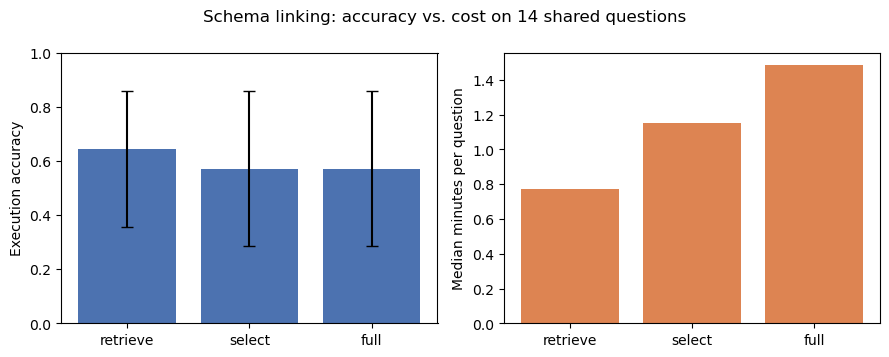

schema_mode  table_recall  mean_tables  acc_tables_found  acc_tables_missed
model            condition                                                                                 
qwen2.5-coder:7b C0_baseline       retrieve          1.00         4.08              0.71                NaN
                 C1_notes          retrieve          1.00         4.08              0.61                NaN
                 C2_hints          retrieve          1.00         4.08              0.66                NaN
                 C3_few_shot       retrieve          1.00         4.08              0.58                NaN
                 C4_full_agent     retrieve          1.00         4.08              0.63                NaN
                 S1_full_schema        full          1.00        35.00              0.57                NaN
                 S2_llm_select       select          0.93         3.14              0.62                0.0
                 C5_repair         retrieve          1.00         4.08              0.66                NaN
                 C6_lean_repair    retrieve          1.00         4.08              0.82                NaN

pairs  original_acc  paraphrase_acc  same_outcome
model            condition                                                        
qwen2.5-coder:7b C0_baseline         8          0.50            0.50          1.00
                 C4_full_agent       8          0.62            0.62          0.75
                 C5_repair           8          0.62            0.75          0.88
                 C6_lean_repair      8          0.88            0.75          0.88

median_sec  llm_calls  prompt_tokens_est  prompt_tokens_evaluated  prompt_tok_per_s  gen_tok_per_s  share_prompt_time
model            condition                                                                                                                            
qwen2.5-coder:7b C0_baseline           23.7        1.0              582.2                    505.2              65.6            2.9                0.3
                 C1_notes              23.2        1.0             1002.8                    873.2             117.0            3.3                0.3
                 C2_hints              35.4        1.0             1241.8                   1195.4              59.8            3.2                0.5
                 C3_few_shot           35.4        1.0             1528.5                   1460.4              75.0            3.1                0.5
                 C4_full_agent         50.6        1.4             1507.6                   1468.2              87.3            1.6                0.3
                 S1_full_schema        89.0        1.5             4473.2                   4252.7             160.3            2.1                0.4
                 S2_llm_select         65.0        2.4             1412.0                   1265.8             134.8            3.2                0.4
                 C5_repair             50.2        1.3             1507.6                   1467.9              87.8            2.1                0.4
                 C6_lean_repair        26.3        1.2              582.2                    530.5              82.9            3.4                0.3

In [31]:
def in_condition_order(frame):
    order = {c: i for i, c in enumerate(CONDITIONS)}
    if frame.empty:
        return frame
    keys = [(m, order.get(c, 99)) for m, c in frame.index]
    return frame.iloc[sorted(range(len(frame)), key=lambda i: keys[i])]


def linking_table(runs):
    rows = []
    sub = runs[runs["answerable"] & runs["qid"].isin(CORE_IDS)]
    for (model, cond), g in sub.groupby(["model", "condition"], sort=False):
        found = g["gold_tables_found"] == 1
        rows.append({"model": model, "condition": cond, "schema_mode": g["schema_mode"].iloc[0],
                     "table_recall": found.mean(),
                     "mean_tables": g["selected_tables"].apply(len).mean(),
                     "acc_tables_found": g.loc[found, "correct"].mean() if found.any() else np.nan,
                     "acc_tables_missed": g.loc[~found, "correct"].mean() if (~found).any() else np.nan})
    return in_condition_order(pd.DataFrame(rows).set_index(["model", "condition"]))


def paraphrase_table(runs):
    rows = []
    for (model, cond), g in runs.groupby(["model", "condition"], sort=False):
        ok = dict(zip(g["qid"], g["correct"]))
        pairs = [(QUESTION_BY_ID[p]["paraphrase_of"], p) for p in PARAPHRASE_IDS
                 if p in ok and QUESTION_BY_ID[p]["paraphrase_of"] in ok]
        if not pairs:
            continue
        rows.append({"model": model, "condition": cond, "pairs": len(pairs),
                     "original_acc": np.mean([ok[o] for o, _ in pairs]),
                     "paraphrase_acc": np.mean([ok[p] for _, p in pairs]),
                     "same_outcome": np.mean([ok[o] == ok[p] for o, p in pairs])})
    return in_condition_order(pd.DataFrame(rows).set_index(["model", "condition"])) if rows else pd.DataFrame()


def latency_table(runs):
    rows = []
    for (model, cond), g in runs.groupby(["model", "condition"], sort=False):
        rows.append({"model": model, "condition": cond, "median_sec": g["seconds_total"].median(),
                     "llm_calls": g["n_calls"].mean(), "prompt_tokens_est": g["est_prompt_tokens"].mean(),
                     "prompt_tokens_evaluated": (g["prompt_eval_tokens"] / g["n_calls"]).mean(),
                     "prompt_tok_per_s": g["prompt_eval_tokens"].sum() / max(g["prompt_eval_s"].sum(), 1e-9),
                     "gen_tok_per_s": g["gen_tokens"].sum() / max(g["gen_s"].sum(), 1e-9),
                     "share_prompt_time": g["prompt_eval_s"].sum() / max(g["llm_s"].sum(), 1e-9)})
    return in_condition_order(pd.DataFrame(rows).set_index(["model", "condition"]))


SCHEMA_GROUP = ["C4_full_agent", "S2_llm_select", "S1_full_schema"]


def shared_subset_table(runs, conditions, model):
    """Compare conditions on exactly the answerable questions they all ran."""
    sub = runs[(runs["model"] == model) & runs["condition"].isin(conditions) & runs["answerable"]]
    present = [c for c in conditions if c in set(sub["condition"])]
    if len(present) < 2:
        return pd.DataFrame()
    common = set.intersection(*(set(sub.loc[sub["condition"] == c, "qid"]) for c in present))
    rows = []
    for c in present:
        g = sub[(sub["condition"] == c) & sub["qid"].isin(common)]
        lo, hi = bootstrap_ci(g["correct"])
        rows.append({"condition": c, "schema_mode": g["schema_mode"].iloc[0], "n_questions": len(g),
                     "accuracy": g["correct"].mean(), "ci_low": lo, "ci_high": hi,
                     "table_recall": (g["gold_tables_found"] == 1).mean(),
                     "prompt_tokens": g["est_prompt_tokens"].mean(), "median_min": g["seconds_total"].median() / 60})
    return pd.DataFrame(rows).set_index("condition")


if PRESENT:
    SCHEMA_VARIANTS = shared_subset_table(runs, SCHEMA_GROUP, MAIN_MODEL)
    if not SCHEMA_VARIANTS.empty:
        save_table(SCHEMA_VARIANTS, "schema_variants",
                   "Schema-linking modes compared on the questions all of them ran: accuracy versus cost")
        display(SCHEMA_VARIANTS.round(2))
        fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
        labels = SCHEMA_VARIANTS["schema_mode"]
        err = np.vstack([SCHEMA_VARIANTS["accuracy"] - SCHEMA_VARIANTS["ci_low"],
                         SCHEMA_VARIANTS["ci_high"] - SCHEMA_VARIANTS["accuracy"]])
        axes[0].bar(labels, SCHEMA_VARIANTS["accuracy"], yerr=err, capsize=4, color="#4C72B0")
        axes[0].set_ylim(0, 1)
        axes[0].set_ylabel("Execution accuracy")
        axes[1].bar(labels, SCHEMA_VARIANTS["median_min"], color="#DD8452")
        axes[1].set_ylabel("Median minutes per question")
        fig.suptitle(f"Schema linking: accuracy vs. cost on {int(SCHEMA_VARIANTS['n_questions'].iloc[0])} shared questions")
        plt.tight_layout()
        save_figure(fig, "schema_variants")
        plt.show()

    LINKING = linking_table(runs)
    save_table(LINKING, "schema_linking", "Schema-linking recall and accuracy when gold tables were or were not linked")
    display(LINKING.round(2))

    PARAPHRASE = paraphrase_table(runs)
    if not PARAPHRASE.empty:
        save_table(PARAPHRASE, "paraphrase_robustness", "Robustness to question paraphrasing")
        display(PARAPHRASE.round(2))

    LATENCY = latency_table(runs)
    save_table(LATENCY, "latency", "Latency and token throughput per question on CPU", digits=1)
    display(LATENCY.round(1))

In [32]:
def strip_literals(sql):
    return re.sub(r"'(?:[^']|'')*'", "''", sql or "")


def uses_case_sensitive_like(sql):
    return bool(re.search(r"(?<![A-Za-z_])LIKE\b", strip_literals(sql), flags=re.IGNORECASE))


def schema_tables_in(sql):
    """MIMIC tables a query reads (common-table-expression names are ignored)."""
    names = re.findall(r"\b(?:FROM|JOIN)\s+([\w\.]+)", strip_literals(sql), flags=re.IGNORECASE)
    return {n.split(".")[-1].lower() for n in names if n.split(".")[-1].lower() in TABLE_KEY_BY_NAME}


def last_sql(r):
    if isinstance(r["final_sql"], str):
        return r["final_sql"]
    return next((a.get("sql") for a in reversed(r["attempts"]) if a.get("sql")), "") or ""


def failure_diagnostics(runs):
    rows = []
    for (model, cond), g in runs[runs["qid"].isin(CORE_IDS) & runs["answerable"]].groupby(["model", "condition"], sort=False):
        wrong = g[~g["correct"]]
        retries = [(prev.get("sql"), cur.get("sql"), cur.get("repeat", False))
                   for atts in g["attempts"] for prev, cur in zip(atts, atts[1:])]
        identical = sum(1 for p, c, rep in retries
                        if rep or (p and c and canonical_sql(p) == canonical_sql(c)))
        distractor = pd.Series([bool(schema_tables_in(last_sql(r)) - set(QUESTION_BY_ID[r["qid"]]["tables"])
                                     - {"patients", "admissions"}) for _, r in g.iterrows()], index=g.index, dtype=bool)
        rows.append({"model": model, "condition": cond, "answerable": len(g), "wrong": len(wrong),
                     "wrong_with_LIKE": sum(uses_case_sensitive_like(last_sql(r)) for _, r in wrong.iterrows()),
                     "retries": len(retries), "identical_retries": identical,
                     "rescued_by_retry": int((g["correct"] & (g["n_attempts"] > 1)).sum()),
                     "uses_distractor_table": int(distractor.sum()),
                     "acc_with_distractor": g.loc[distractor, "correct"].mean() if distractor.any() else np.nan,
                     "acc_without_distractor": g.loc[~distractor, "correct"].mean() if (~distractor).any() else np.nan})
    return in_condition_order(pd.DataFrame(rows).set_index(["model", "condition"]))


LIKE_CACHE = OUTPUT_DIR / "like_counterfactual.json"


def like_counterfactual(runs):
    """Re-run every logged wrong answer that used LIKE with ILIKE instead, and re-score it (no model calls)."""
    cache = json.loads(LIKE_CACHE.read_text(encoding="utf-8")) if LIKE_CACHE.exists() else {}
    rows = []
    for _, r in runs[runs["answerable"] & ~runs["correct"]].iterrows():
        sql = last_sql(r)
        if not sql or not uses_case_sensitive_like(sql) or check_sql(sql):
            continue
        fixed = normalize_sql(sql)
        key = sql_hash(fixed)
        if key not in cache:
            res = run_sql(fixed, timeout_s=GOLD_TIMEOUT_S)
            cache[key] = {"ok": res.ok, "rows": [[to_jsonable(v) for v in row] for row in res.rows[:50]]}
            LIKE_CACHE.write_text(json.dumps(cache), encoding="utf-8")
        entry, gold = cache[key], GOLD.get(r["qid"])
        now_correct = bool(entry["ok"] and gold and (exact_match(gold["rows"], entry["rows"])
                                                    or relaxed_match(gold["rows"], entry["rows"])))
        rows.append({"model": r["model"], "condition": r["condition"], "qid": r["qid"], "now_correct": now_correct})
    frame = pd.DataFrame(rows, columns=["model", "condition", "qid", "now_correct"])
    if frame.empty:
        return frame
    return in_condition_order(frame.groupby(["model", "condition"], sort=False)
                              .agg(wrong_with_LIKE=("qid", "size"), fixed_by_ILIKE=("now_correct", "sum"),
                                   questions=("qid", lambda s: ", ".join(sorted(set(s))))))


def heldout_table(runs):
    rows = []
    for (model, cond), g in runs[runs["qid"].isin(HELDOUT_IDS)].groupby(["model", "condition"], sort=False):
        ans, una = g[g["answerable"]], g[~g["answerable"]]
        lo, hi = bootstrap_ci(ans["correct"])
        rows.append({"model": model, "condition": cond, "n_answerable": len(ans), "accuracy": ans["correct"].mean(),
                     "ci_low": lo, "ci_high": hi, "n_unanswerable": len(una),
                     "abstain_acc": una["correct"].mean() if len(una) else np.nan})
    return in_condition_order(pd.DataFrame(rows).set_index(["model", "condition"])) if rows else pd.DataFrame()


if PRESENT:
    DIAGNOSTICS = failure_diagnostics(runs)
    save_table(DIAGNOSTICS, "failure_diagnostics",
               "Failure modes by condition: case-sensitive LIKE, repeated retries, and distractor tables", digits=2)
    display(DIAGNOSTICS.round(2))

    LIKE_FIX = like_counterfactual(runs[runs["model"] == MAIN_MODEL])
    if not LIKE_FIX.empty:
        save_table(LIKE_FIX, "like_counterfactual", "Wrong answers that used LIKE, re-run with ILIKE", digits=0)
        display(LIKE_FIX)

    HELDOUT = heldout_table(runs)
    if not HELDOUT.empty:
        save_table(HELDOUT, "heldout", "Accuracy on the 12 held-out questions (written after the main runs)")
        display(HELDOUT.round(3))


answerable  wrong  wrong_with_LIKE  retries  identical_retries  rescued_by_retry  uses_distractor_table  acc_with_distractor  acc_without_distractor
model            condition                                                                                                                                                           
qwen2.5-coder:7b C0_baseline             38     11                0        0                  0                 0                      0                  NaN                    0.71
                 C1_notes                38     15                0        0                  0                 0                      0                  NaN                    0.61
                 C2_hints                38     13                3        0                  0                 0                      2                  0.0                    0.69
                 C3_few_shot             38     16                3        0                  0                 0                      7                  0.0                    0.71
                 C4_full_agent           38     14                4       17                 10                 2                      7                  0.0                    0.77
                 S1_full_schema          14      6                1        6                  3                 2                      3                  0.0                    0.73
                 S2_llm_select           14      6                1        6                  4                 0                      1                  0.0                    0.62
                 C5_repair               38     13                0       14                  4                 2                      7                  0.0                    0.81
                 C6_lean_repair          38      7                0        8                  2                 4                      0                  NaN                    0.82

wrong_with_LIKE  fixed_by_ILIKE                 questions
model            condition                                                                
qwen2.5-coder:7b C2_hints                      3               0               M12, M3, M4
                 C3_few_shot                   3               1               M12, M3, M4
                 C4_full_agent                 6               2  M12, M3, M4, P3, P8, X10
                 S1_full_schema                1               0                        M3
                 S2_llm_select                 1               0                        M3

n_answerable  accuracy  ci_low  ci_high  n_unanswerable  abstain_acc
model            condition                                                                           
qwen2.5-coder:7b C0_baseline               10       0.7     0.4      1.0               2          0.5
                 C4_full_agent             10       0.8     0.5      1.0               2          0.5
                 C5_repair                 10       0.8     0.5      1.0               2          0.5
                 C6_lean_repair            10       0.7     0.4      1.0               2          0.5

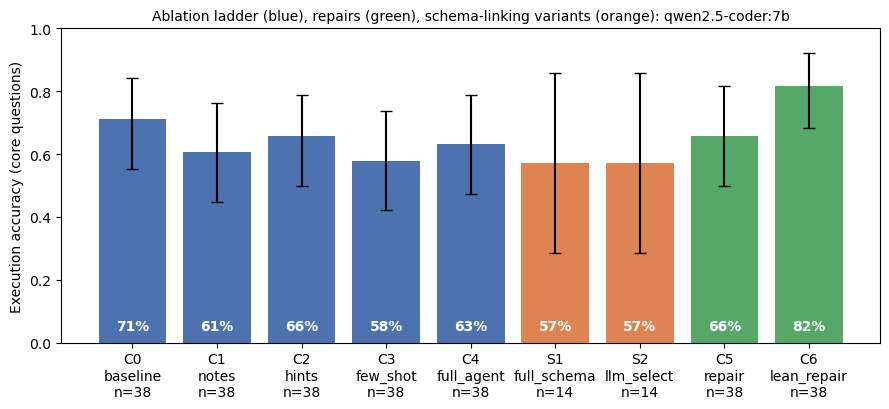

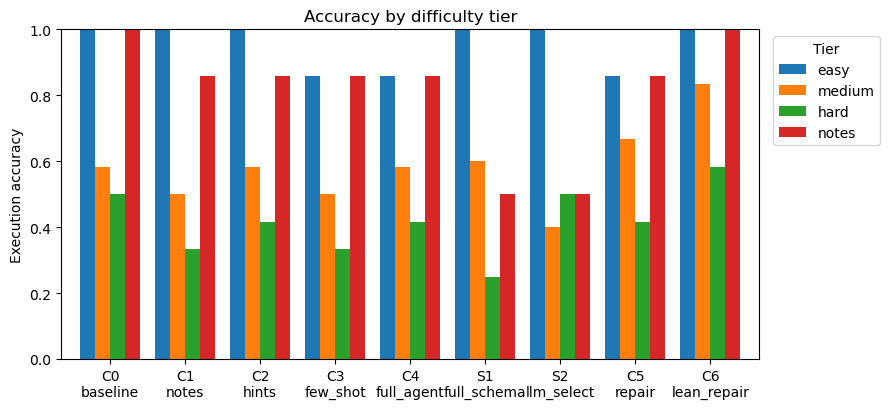

In [33]:
if PRESENT:
    main = SUMMARY.loc[MAIN_MODEL] if MAIN_MODEL in SUMMARY.index.get_level_values(0) else SUMMARY.droplevel(0)
    main = main.reindex([c for c in CONDITIONS if c in main.index])
    colors = ["#4C72B0" if c in LADDER else "#55A868" if c in REPAIRS else "#DD8452" for c in main.index]
    fig, ax = plt.subplots(figsize=(9, 4.2))
    err = np.vstack([main["accuracy"] - main["ci_low"], main["ci_high"] - main["accuracy"]])
    ax.bar(range(len(main)), main["accuracy"], yerr=err, capsize=4, color=colors)
    ax.set_xticks(range(len(main)), [c.replace("_", "\n", 1) + f"\nn={int(n)}"
                                     for c, n in zip(main.index, main["n_answerable"])])
    ax.set_ylim(0, 1)
    ax.set_ylabel("Execution accuracy (core questions)")
    ax.set_title(f"Ablation ladder (blue), repairs (green), schema-linking variants (orange): {MAIN_MODEL}",
                 fontsize=10)
    for i, v in enumerate(main["accuracy"]):
        ax.text(i, 0.03, f"{v:.0%}", ha="center", va="bottom", fontsize=10, color="white", fontweight="bold")
    plt.tight_layout()
    save_figure(fig, "accuracy_by_condition")
    plt.show()

    diff = BY_DIFFICULTY.loc[MAIN_MODEL] if MAIN_MODEL in BY_DIFFICULTY.index.get_level_values(0) else BY_DIFFICULTY.droplevel(0)
    diff = diff.reindex([c for c in CONDITIONS if c in diff.index])
    ax = diff.plot(kind="bar", figsize=(9, 4.2), rot=0, width=0.8)
    ax.set_xticks(range(len(diff)), [c.replace("_", "\n", 1) for c in diff.index])
    ax.set_xlabel("")
    ax.set_ylabel("Execution accuracy")
    ax.set_ylim(0, 1)
    ax.set_title("Accuracy by difficulty tier")
    ax.legend(title="Tier", bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout()
    save_figure(ax.figure, "accuracy_by_difficulty")
    plt.show()

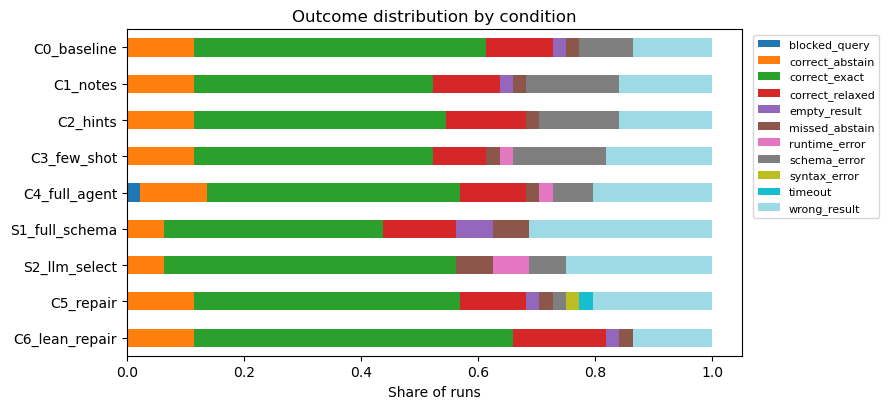

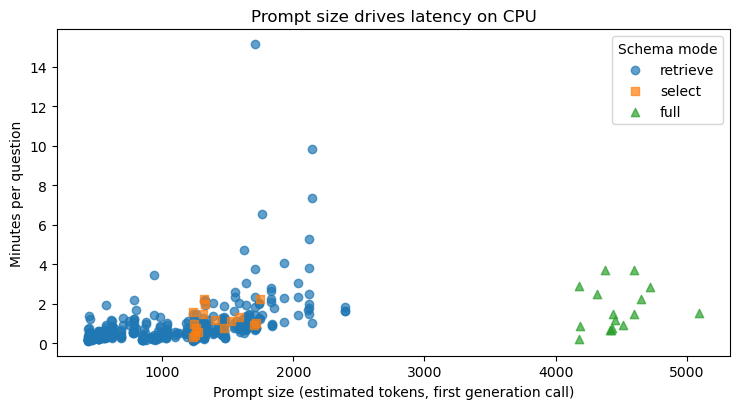

In [34]:
if PRESENT:
    sub = runs[(runs["model"] == MAIN_MODEL) & runs["qid"].isin(CORE_IDS)]
    mix = sub.groupby(["condition", "outcome"]).size().unstack(fill_value=0)
    mix = mix.reindex([c for c in CONDITIONS if c in mix.index])
    mix = mix.div(mix.sum(axis=1), axis=0)
    ax = mix.plot(kind="barh", stacked=True, figsize=(9, 4.2), colormap="tab20")
    ax.invert_yaxis()
    ax.set_xlabel("Share of runs")
    ax.set_ylabel("")
    ax.set_title("Outcome distribution by condition")
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
    plt.tight_layout()
    save_figure(ax.figure, "outcomes_by_condition")
    plt.show()

    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    for mode, marker in (("retrieve", "o"), ("select", "s"), ("full", "^")):
        pts = runs[(runs["model"] == MAIN_MODEL) & (runs["schema_mode"] == mode)]
        if len(pts):
            ax.scatter(pts["est_prompt_tokens"], pts["seconds_total"] / 60, label=mode, marker=marker, alpha=0.7)
    ax.set_xlabel("Prompt size (estimated tokens, first generation call)")
    ax.set_ylabel("Minutes per question")
    ax.set_title("Prompt size drives latency on CPU")
    ax.legend(title="Schema mode")
    plt.tight_layout()
    save_figure(fig, "latency_vs_prompt_size")
    plt.show()

In [35]:
# Per-question outcomes across conditions: where each component helps or hurts
if PRESENT:
    MATRIX = (runs[runs["model"] == MAIN_MODEL]
              .pivot_table(index="qid", columns="condition", values="outcome", aggfunc="first")
              .reindex(columns=PRESENT))
    MATRIX = MATRIX.reindex([q["id"] for q in QUESTIONS if q["id"] in MATRIX.index])
    MATRIX.to_csv(TABLE_DIR / "per_question_outcomes.csv")
    display(MATRIX)

condition,C0_baseline,C1_notes,C2_hints,C3_few_shot,C4_full_agent,S1_full_schema,S2_llm_select,C5_repair,C6_lean_repair
qid,,,,,,,,,
E1,correct_exact,correct_exact,correct_exact,correct_exact,correct_exact,correct_exact,correct_exact,correct_exact,correct_exact
E2,correct_exact,correct_exact,correct_exact,correct_exact,correct_exact,NaN,NaN,correct_exact,correct_exact
E3,correct_exact,correct_exact,correct_exact,correct_exact,correct_exact,correct_exact,correct_exact,correct_exact,correct_exact
E4,correct_relaxed,correct_relaxed,correct_relaxed,correct_relaxed,correct_relaxed,NaN,NaN,correct_relaxed,correct_relaxed
E5,correct_exact,correct_exact,correct_exact,correct_exact,correct_exact,correct_exact,correct_exact,correct_exact,correct_exact
...,...,...,...,...,...,...,...,...,...
P4,wrong_result,NaN,NaN,NaN,correct_exact,NaN,NaN,correct_exact,correct_exact
P5,wrong_result,NaN,NaN,NaN,wrong_result,NaN,NaN,wrong_result,wrong_result
P6,correct_exact,NaN,NaN,NaN,correct_exact,NaN,NaN,correct_exact,correct_exact


### Error analysis

The automatic outcome labels say *that* a query failed, not *why*. The next cell exports every failure to `results/error_annotations.csv` with a **suggested label**. The suggestion comes from comparing the predicted and gold SQL: the tables used, literal filter values, aggregates, and time logic. It is a first guess; for example, it cannot tell a misread question from a wrong join.

**Categories:**
- `wrong_table`, `wrong_join`, `wrong_filter_value`, `wrong_aggregation`, `wrong_time_logic`
- `misread_question`, `ambiguous_question`, `gold_issue`
- `hallucinated_schema`, `invalid_sql`, `no_sql`, `timeout`
- `missed_abstention`, `false_abstention`
- `other`

A label confirmed by hand in the `error_label` column takes precedence over the suggestion, and re-running the cell adds new failures without overwriting confirmed labels. The error-taxonomy table's caption states how many labels were confirmed by hand. The failure-mode diagnostics in Section 13 complement this table with checks that do not depend on labels.


In [36]:
ANNOTATION_FILE = OUTPUT_DIR / "error_annotations.csv"
ANNOTATION_KEY = ["qid", "condition", "model", "agent_revision"]
AGGREGATES = ("COUNT", "AVG", "SUM", "MIN", "MAX", "MEDIAN")
TIME_LOGIC = ("INTERVAL", "DATE_DIFF", "DATEDIFF", "LEAD", "LAG", "ROW_NUMBER", "EXTRACT", "DATE_TRUNC")


def sql_features(sql):
    """Coarse features of a query for comparing a prediction with its gold query."""
    text = sql or ""
    upper = text.upper()
    return {
        "tables": set(re.findall(r"\b(?:FROM|JOIN)\s+(mimiciv_\w+\.\w+)", text, flags=re.IGNORECASE)),
        "literals": {v.strip().lower() for v in re.findall(r"'((?:[^']|'')*)'", text)},
        "aggregates": {a for a in AGGREGATES if re.search(rf"\b{a}\s*\(", upper)},
        "distinct": "DISTINCT" in upper,
        "percent": bool(re.search(r"\b100(\.0*)?\s*\*|\*\s*100\b", text)),
        "time": {t for t in TIME_LOGIC if re.search(rf"\b{t}\b", upper)},
    }


def suggest_error_label(outcome, predicted_sql, gold_sql, error_type=""):
    """A first-guess error category; confirm or correct it in the error_label column."""
    fixed = {"missed_abstain": "missed_abstention", "false_abstain": "false_abstention", "no_sql": "no_sql",
             "syntax_error": "invalid_sql", "timeout": "timeout", "blocked_query": "invalid_sql"}
    if outcome in fixed:
        return fixed[outcome]
    if outcome == "schema_error":
        return "hallucinated_schema"
    if outcome == "runtime_error":
        return "invalid_sql"
    pred, gold = sql_features(predicted_sql), sql_features(gold_sql)
    if pred["tables"] != gold["tables"]:
        return "wrong_table"
    if pred["literals"] != gold["literals"]:
        return "wrong_filter_value"
    if pred["aggregates"] != gold["aggregates"] or pred["distinct"] != gold["distinct"] \
            or pred["percent"] != gold["percent"]:
        return "wrong_aggregation"
    if pred["time"] != gold["time"]:
        return "wrong_time_logic"
    return "other"


def export_failures(runs):
    rows = []
    for _, r in runs[~runs["correct"]].iterrows():
        q = QUESTION_BY_ID[r["qid"]]
        last = r["attempts"][-1] if r["attempts"] else {}
        candidates = (r["final_sql"], last.get("sql"), r["abstain_reason"], last.get("reply"))
        predicted = next((c for c in candidates if isinstance(c, str) and c), "")
        sql_for_label = r["final_sql"] if isinstance(r["final_sql"], str) else (last.get("sql") or "")
        rows.append({"qid": r["qid"], "condition": r["condition"], "model": r["model"],
                     "agent_revision": r.get("agent_revision", ""), "outcome": r["outcome"],
                     "question": q["question"], "predicted": " ".join(predicted.split()),
                     "last_error": " ".join((last.get("error") or "").split())[:300],
                     "gold_sql": " ".join((q["gold_sql"] or "").split()),
                     "suggested_label": suggest_error_label(r["outcome"], sql_for_label, q["gold_sql"],
                                                            last.get("error_type", "")),
                     "error_label": "", "note": ""})
    columns = ANNOTATION_KEY + ["outcome", "question", "predicted", "last_error", "gold_sql",
                                "suggested_label", "error_label", "note"]
    new = pd.DataFrame(rows, columns=columns)
    if ANNOTATION_FILE.exists():
        old = pd.read_csv(ANNOTATION_FILE, dtype=str).fillna("")
        for col in columns:
            if col not in old.columns:
                old[col] = ""
        old = old[old["agent_revision"] == AGENT_REVISION][columns]    # labels from older agents don't apply
        seen = set(map(tuple, old[ANNOTATION_KEY].values.tolist()))
        fresh = new[[tuple(k) not in seen for k in new[ANNOTATION_KEY].values.tolist()]]
        merged = pd.concat([old, fresh], ignore_index=True)
        print(f"{len(fresh)} new failures added; {len(old)} kept with their labels")
    else:
        merged = new
        print(f"{len(new)} failures exported")
    merged.to_csv(ANNOTATION_FILE, index=False)
    return merged


if PRESENT:
    ANNOTATIONS = export_failures(runs)
    if len(ANNOTATIONS):
        confirmed = ANNOTATIONS["error_label"].astype(str).str.strip() != ""
        ANNOTATIONS["final_label"] = ANNOTATIONS["error_label"].where(confirmed, ANNOTATIONS["suggested_label"])
        ERROR_TAXONOMY = pd.crosstab(ANNOTATIONS["final_label"], ANNOTATIONS["condition"])
        ERROR_TAXONOMY = ERROR_TAXONOMY.reindex(columns=[c for c in CONDITIONS if c in ERROR_TAXONOMY.columns])
        status = (f"{int(confirmed.sum())} of {len(ANNOTATIONS)} labels confirmed by hand"
                  if confirmed.any() else "suggested labels, not yet confirmed by hand")
        save_table(ERROR_TAXONOMY, "error_taxonomy", f"Error categories by condition ({status})", digits=0)
        print(status)
        display(ERROR_TAXONOMY)
    else:
        print("No failures to label.")


0 new failures added; 135 kept with their labels
suggested labels, not yet confirmed by hand


condition,C0_baseline,C1_notes,C2_hints,C3_few_shot,C4_full_agent,S1_full_schema,S2_llm_select,C5_repair,C6_lean_repair
final_label,,,,,,,,,
false_abstention,0,0,0,0,0,0,0,0,1
hallucinated_schema,5,7,6,7,3,0,1,1,0
invalid_sql,0,0,0,1,2,0,1,1,0
missed_abstention,2,1,1,1,2,1,1,2,2
other,2,0,1,0,1,0,0,0,2
timeout,0,0,0,0,0,0,0,1,0
wrong_aggregation,2,1,0,0,0,1,0,0,2
wrong_filter_value,8,6,5,4,6,2,3,6,5
wrong_table,1,1,1,4,7,3,1,8,2


In [37]:
def show_trace(qid, condition, model=None):
    """Print one logged run step by step, e.g. to show self-correction in action."""
    model = model or MAIN_MODEL
    match = runs[(runs["qid"] == qid) & (runs["condition"] == condition) & (runs["model"] == model)]
    if match.empty:
        print("No such run.")
        return
    r, q = match.iloc[-1], QUESTION_BY_ID[qid]
    print(f"{qid} [{r['outcome']}] {q['question']}")
    print(f"Tables linked: {', '.join(r['selected_tables'])}")
    for step in r["attempts"]:
        print(f"\n--- attempt {step['attempt']} ({step['kind']}) ---")
        print(step.get("sql") or step.get("reply", ""))
        if step.get("error"):
            print(f"ERROR [{step['error_type']}]: {step['error'][:300]}")
        if step.get("empty_retry"):
            print("(empty result: model asked to double-check filters)")
    print("\nResult preview:", r["result_preview"])
    if q["gold_sql"]:
        print("Gold SQL:", " ".join(q["gold_sql"].split()))
    print(f"Time: {r['seconds_total']:.0f} s over {r['n_calls']} LLM call(s)")


if PRESENT:
    # Find a run where self-correction rescued the query, as a showcase example.
    rescued = runs[(runs["n_attempts"] > 1) & runs["correct"] & (runs["model"] == MAIN_MODEL)]
    if len(rescued):
        show_trace(rescued.iloc[0]["qid"], rescued.iloc[0]["condition"])
    else:
        print("No self-corrected successes logged yet.")

M1 [correct_relaxed] What are the 5 most common primary diagnoses across all admissions, by ICD diagnosis description?
Tables linked: patients, admissions, diagnoses_icd, d_icd_diagnoses, drgcodes

--- attempt 1 (sql) ---
SELECT d.long_title, COUNT(*) AS count
FROM mimiciv_hosp.diagnoses_icd d
JOIN mimiciv_hosp.d_icd_diagnoses dd ON d.icd_code = dd.icd_code AND d.icd_version = dd.icd_version
WHERE d.seq_num = 1
GROUP BY d.long_title
ORDER BY count DESC
LIMIT 5
ERROR [BinderException]: Binder Error: Table "d" does not have a column named "long_title"

Candidate bindings: : "hadm_id"

LINE 5: GROUP BY d.long_title
                 ^

--- attempt 2 (sql) ---
SELECT dd.long_title, COUNT(*) AS count
FROM mimiciv_hosp.diagnoses_icd d
JOIN mimiciv_hosp.d_icd_diagnoses dd ON d.icd_code = dd.icd_code AND d.icd_version = dd.icd_version
WHERE d.seq_num = 1
GROUP BY dd.long_title
ORDER BY count DESC
LIMIT 5

Result preview: [['Chest pain, unspecified', 10203], ['Other chest pain', 7332], ['Encount

## 14. Method figures and tables

These cells produce:
- **the workflow figure;**
- **the benchmark description table;**
- **the condition definitions table;**
- **the experimental-setup table** (throughput comes from the logged runs once there are any);
- **single-column figures** with print-sized type (`figures/paper_*.png`): a larger-text workflow diagram for the full page width, accuracy by condition, and time per question against prompt size.


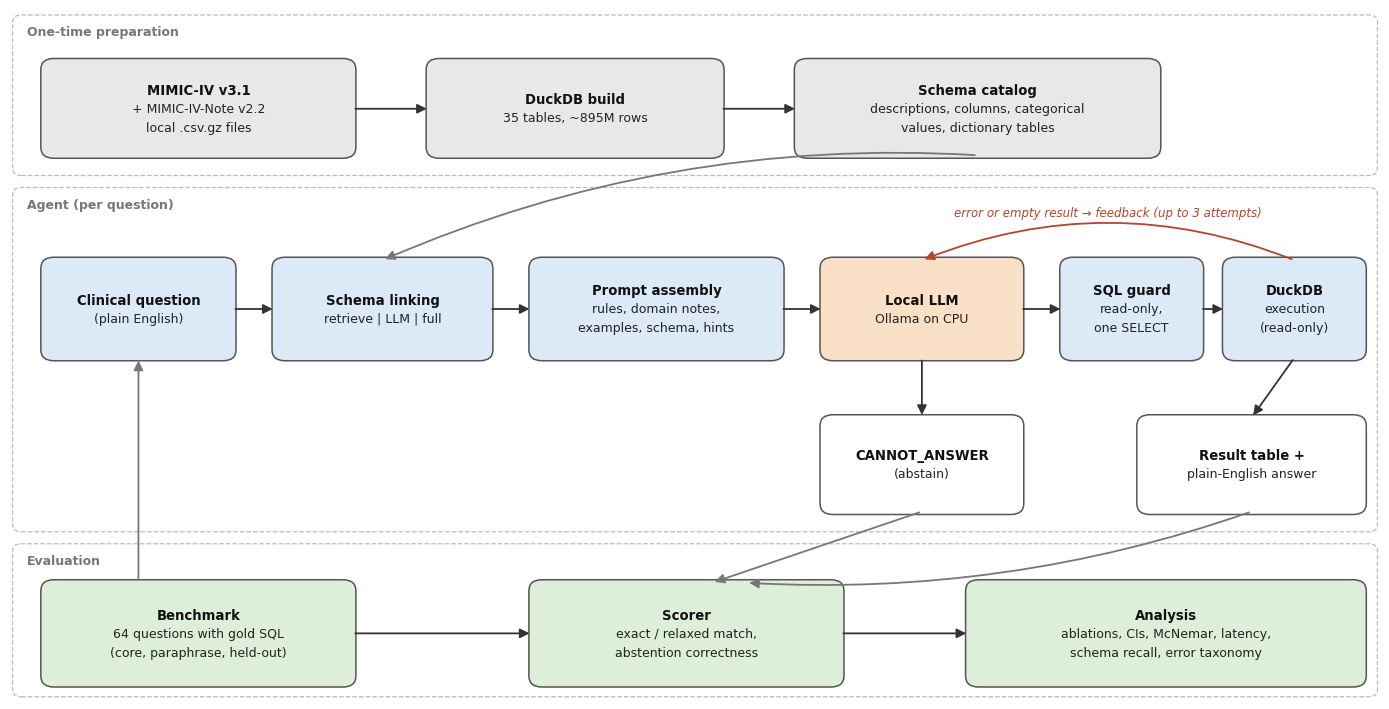

In [38]:
def draw_workflow(name="workflow", scale=1.0, show=True):
    """scale enlarges all text and line spacing (the report version uses ~1.3 so it stays legible at page width)."""
    n_tables = len(CATALOG)
    n_rows = int(inventory["approx_rows"].sum())
    n_q = len(QUESTIONS)
    fig, ax = plt.subplots(figsize=(14, 7.2))
    ax.set_xlim(0, 16)
    ax.set_ylim(0, 9.2)
    ax.axis("off")
    palette = {"offline": "#E8E8E8", "agent": "#DCE9F7", "llm": "#F9E0C7", "eval": "#DDEFD9", "out": "#FFFFFF"}

    def box(x, y, w, h, text, kind, bold_first=True):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.15",
                                    facecolor=palette[kind], edgecolor="#555555", linewidth=1.1))
        title, *body = text.split("\n")
        line_h = 0.25 * scale
        top = y + h / 2 + (len(body) * line_h) / 2
        ax.text(x + w / 2, top, title, ha="center", va="center", fontsize=9.5 * scale,
                fontweight="bold" if bold_first else "normal", color="#111111")
        for i, line in enumerate(body, 1):
            ax.text(x + w / 2, top - i * line_h, line, ha="center", va="center", fontsize=9 * scale, color="#222222")
        return (x, y, w, h)

    def arrow(p, q, text="", rad=0.0, color="#333333", offset=(0, 0.18)):
        ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=14, linewidth=1.3,
                                     color=color, connectionstyle=f"arc3,rad={rad}"))
        if text:
            ax.text((p[0] + q[0]) / 2 + offset[0], (p[1] + q[1]) / 2 + offset[1], text,
                    ha="center", va="bottom", fontsize=8.5 * scale, color=color, style="italic")

    def band(y, h, label):
        ax.add_patch(FancyBboxPatch((0.05, y), 15.9, h, boxstyle="round,pad=0.02,rounding_size=0.1",
                                    facecolor="none", edgecolor="#BBBBBB", linestyle="--", linewidth=0.9))
        ax.text(0.2, y + h - 0.12, label, fontsize=9 * scale, color="#777777", va="top", fontweight="bold")

    band(7.0, 2.1, "One-time preparation")
    band(2.25, 4.55, "Agent (per question)")
    band(0.05, 2.0, "Evaluation")

    a = box(0.4, 7.25, 3.6, 1.25, "MIMIC-IV v3.1\n+ MIMIC-IV-Note v2.2\nlocal .csv.gz files", "offline")
    b = box(4.9, 7.25, 3.4, 1.25, f"DuckDB build\n{n_tables} tables, " + (f"~{n_rows / 1e6:,.0f}M rows" if n_rows >= 1e6 else f"{n_rows:,} rows"), "offline")
    c = box(9.2, 7.25, 4.2, 1.25, "Schema catalog\ndescriptions, columns, categorical\nvalues, dictionary tables", "offline")
    arrow((4.0, 7.87), (4.9, 7.87))
    arrow((8.3, 7.87), (9.2, 7.87))

    q = box(0.4, 4.55, 2.2, 1.3, "Clinical question\n(plain English)", "agent")
    sl = box(3.1, 4.55, 2.5, 1.3, "Schema linking\nretrieve | LLM | full", "agent")
    pa = box(6.1, 4.55, 2.9, 1.3, "Prompt assembly\nrules, domain notes,\nexamples, schema, hints", "agent")
    llm = box(9.5, 4.55, 2.3, 1.3, "Local LLM\nOllama on CPU", "llm")
    g = box(12.3, 4.55, 1.6, 1.3, "SQL guard\nread-only,\none SELECT", "agent")
    x = box(14.2, 4.55, 1.6, 1.3, "DuckDB\nexecution\n(read-only)", "agent")
    arrow((2.6, 5.2), (3.1, 5.2))
    arrow((5.6, 5.2), (6.1, 5.2))
    arrow((9.0, 5.2), (9.5, 5.2))
    arrow((11.8, 5.2), (12.3, 5.2))
    arrow((13.9, 5.2), (14.2, 5.2))
    arrow((11.3, 7.25), (4.35, 5.85), rad=0.12, color="#777777")
    arrow((15.0, 5.85), (10.65, 5.85), "error or empty result \u2192 feedback (up to 3 attempts)",
          rad=0.2, color="#B5452B", offset=(0.0, 0.55))

    res = box(13.2, 2.5, 2.6, 1.25, "Result table +\nplain-English answer", "out")
    abst = box(9.5, 2.5, 2.3, 1.25, "CANNOT_ANSWER\n(abstain)", "out")
    arrow((15.0, 4.55), (14.5, 3.75))
    arrow((10.65, 4.55), (10.65, 3.75))

    bench = box(0.4, 0.2, 3.6, 1.35, f"Benchmark\n{n_q} questions with gold SQL\n(core, paraphrase, held-out)", "eval")
    sc = box(6.1, 0.2, 3.6, 1.35, "Scorer\nexact / relaxed match,\nabstention correctness", "eval")
    an = box(11.2, 0.2, 4.6, 1.35, "Analysis\nablations, CIs, McNemar, latency,\nschema recall, error taxonomy", "eval")
    arrow((4.0, 0.875), (6.1, 0.875))
    arrow((9.7, 0.875), (11.2, 0.875))
    arrow((14.5, 2.5), (8.6, 1.55), rad=-0.1, color="#777777")
    arrow((10.65, 2.5), (8.2, 1.55), color="#777777")
    arrow((1.5, 1.55), (1.5, 4.55), color="#777777")
    plt.tight_layout()
    save_figure(fig, name)
    plt.show() if show else plt.close(fig)


draw_workflow()

In [39]:
def benchmark_table():
    rows = []
    for tier in ["easy", "medium", "hard", "notes", "unanswerable", "paraphrase"]:
        qs = [q for q in QUESTIONS if q["difficulty"] == tier]
        if not qs:
            continue
        tables = sorted({t for q in qs for t in q["tables"]})
        rows.append({"tier": tier, "questions": len(qs), "distinct_tables": len(tables),
                     "example": qs[0]["question"]})
    return pd.DataFrame(rows)


BENCHMARK = benchmark_table()
save_table(BENCHMARK, "benchmark", "Benchmark composition")
display(BENCHMARK)

CONDITION_TABLE = pd.DataFrame([{
    "condition": c.name, "schema": c.schema_mode, "domain_notes": c.domain_notes, "value_hints": c.value_hints,
    "few_shot": c.few_shot, "max_attempts": c.max_attempts} for c in CONDITIONS.values()])
save_table(CONDITION_TABLE, "conditions", "Agent configurations evaluated")
display(CONDITION_TABLE)

setup_keys = ["python", "duckdb", "ollama_version", "model", "model_parameter_size", "model_quantization_level",
              "num_ctx", "max_output_tokens", "cpu_count", "processor", "ram_gb"]
SETUP_ENV = experiment_environment() or ENVIRONMENT   # the machine the logged runs were made on, when recorded
SETUP = pd.DataFrame([{"item": k, "value": str(SETUP_ENV.get(k, ""))} for k in setup_keys])
MEASURED_SPEED = observed_speed()
if MEASURED_SPEED:   # throughput over all logged runs is more representative than the one-off probe
    SETUP = pd.concat([SETUP, pd.DataFrame([
        {"item": "prompt_tokens_per_s (logged runs)", "value": f"{MEASURED_SPEED['prompt_tok_s']:.1f}"},
        {"item": "generated_tokens_per_s (logged runs)", "value": f"{MEASURED_SPEED['gen_tok_s']:.1f}"},
        {"item": "model_calls_measured", "value": str(MEASURED_SPEED["n_calls"])}])], ignore_index=True)
save_table(SETUP, "setup", "Experimental setup")
display(SETUP)
print("Tables written to", TABLE_DIR)

,tier,questions,distinct_tables,example
0,easy,7,3,How many unique patients are in the database?
1,medium,12,11,"What are the 5 most common primary diagnoses across all admissions, by ICD diagnosis description?"
2,hard,12,13,What is the median age at admission for hospital admissions that ended with the patient dying in the hospital?
3,notes,7,4,How many discharge summaries are in the database?
4,unanswerable,6,0,What is the home address of the patient with the most hospital admissions?
5,paraphrase,8,9,How many women are in the dataset?


,condition,schema,domain_notes,value_hints,few_shot,max_attempts
0,C0_baseline,retrieve,False,False,False,1
1,C1_notes,retrieve,True,False,False,1
2,C2_hints,retrieve,True,True,False,1
3,C3_few_shot,retrieve,True,True,True,1
4,C4_full_agent,retrieve,True,True,True,3
5,S1_full_schema,full,True,True,True,3
6,S2_llm_select,select,True,True,True,3
7,C5_repair,retrieve,True,True,True,3
8,C6_lean_repair,retrieve,False,False,False,3


,item,value
0,python,3.11.16
1,duckdb,1.5.5
2,ollama_version,0.40.13
3,model,qwen2.5-coder:7b
4,model_parameter_size,7.6B
5,model_quantization_level,Q4_K_M
6,num_ctx,8192
7,max_output_tokens,512
8,cpu_count,4
9,processor,"Intel64 Family 6 Model 60 Stepping 3, GenuineIntel"


Tables written to C:\Users\micha\Documents\MyDrive‑G\Python\MSDS\AI 380H AI in Healthcare\HW\High Risk Project\results\tables


In [40]:
# Single-column figures (3.4 in wide) with print-sized type, plus a larger-text workflow diagram.
PAPER_INK, PAPER_MUTED, PAPER_GRID = "#0b0b0b", "#52514e", "#e4e3df"
GROUP_COLORS = {"ablation ladder": "#2a78d6", "schema variants": "#eb6834", "repairs": "#1baf7a"}  # validated set
PAPER_LABELS = {
    "C0_baseline": "C0  baseline", "C1_notes": "C1  + domain notes", "C2_hints": "C2  + value hints",
    "C3_few_shot": "C3  + worked examples", "C4_full_agent": "C4  + self-correction",
    "C5_repair": "C5  C4 + repairs", "C6_lean_repair": "C6  C0 + retries, repairs",
}


def condition_group(c):
    return "ablation ladder" if c in LADDER else "repairs" if c in REPAIRS else "schema variants"


def paper_axes(ax, grid_axis="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(PAPER_MUTED)
        ax.spines[side].set_linewidth(0.6)
    ax.tick_params(colors=PAPER_MUTED, labelcolor=PAPER_INK, labelsize=7, width=0.6, length=2.5)
    (ax.xaxis if grid_axis == "x" else ax.yaxis).grid(True, color=PAPER_GRID, linewidth=0.6)
    ax.set_axisbelow(True)


def paper_figures():
    draw_workflow("paper_workflow", scale=1.3, show=False)
    if not PRESENT:
        print("No runs yet: only the workflow figure was written.")
        return
    with plt.rc_context({"font.size": 7.5, "axes.labelsize": 7.5, "axes.labelcolor": PAPER_INK}):
        # Accuracy on the core set. The schema variants ran on a 16-question subset, so they are left out here
        # and reported in their own table.
        main = SUMMARY.loc[MAIN_MODEL] if MAIN_MODEL in SUMMARY.index.get_level_values(0) else SUMMARY.droplevel(0)
        main = main.reindex([c for c in LADDER + REPAIRS if c in main.index])
        groups = [condition_group(c) for c in main.index]
        fig, ax = plt.subplots(figsize=(3.4, 0.3 * len(main) + 0.55))
        y = np.arange(len(main))[::-1]
        ax.barh(y, main["accuracy"], height=0.62, color=[GROUP_COLORS[g] for g in groups], zorder=2)
        err = np.vstack([main["accuracy"] - main["ci_low"], main["ci_high"] - main["accuracy"]])
        ax.errorbar(main["accuracy"], y, xerr=err, fmt="none", ecolor=PAPER_MUTED, elinewidth=0.8,
                    capsize=2, capthick=0.8, zorder=3)
        for yi, v, hi in zip(y, main["accuracy"], main["ci_high"]):
            ax.text(hi + 0.02, yi, f"{v:.0%}", ha="left", va="center", fontsize=7, color=PAPER_INK)
        ax.set_yticks(y, [PAPER_LABELS.get(c, c) for c in main.index])
        ax.set_ylim(-0.6, len(main) - 0.4)
        ax.set_xlim(0, 1.08)
        ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0], ["0%", "25%", "50%", "75%", "100%"])
        n_core = int(main["n_answerable"].max()) if "n_answerable" in main else None
        ax.set_xlabel("Execution accuracy" + (f" ({n_core} answerable core questions)" if n_core else ""))
        paper_axes(ax, grid_axis="x")
        ax.tick_params(axis="y", length=0)
        if len(set(groups)) > 1:
            from matplotlib.patches import Patch
            ax.legend(handles=[Patch(color=GROUP_COLORS[g], label=g) for g in dict.fromkeys(groups)],
                      fontsize=6.5, frameon=False, loc="lower center", ncol=2, bbox_to_anchor=(0.4, 1.0))
        fig.tight_layout()
        save_figure(fig, "paper_accuracy", dpi=300)
        plt.close(fig)

        sub = runs[(runs["model"] == MAIN_MODEL) & runs["est_prompt_tokens"].notna() & (runs["seconds_total"] > 0)]
        if sub.empty:
            print("No timed runs yet; skipping the latency figure.")
            return
        fig, ax = plt.subplots(figsize=(3.4, 2.2))
        ax.scatter(sub["est_prompt_tokens"], sub["seconds_total"], s=9, color=GROUP_COLORS["ablation ladder"],
                   alpha=0.5, linewidths=0, zorder=2)
        edges = np.arange(0, sub["est_prompt_tokens"].max() + 250, 250)
        mids, meds = [], []
        for lo, hi in zip(edges, edges[1:]):
            vals = sub.loc[(sub["est_prompt_tokens"] >= lo) & (sub["est_prompt_tokens"] < hi), "seconds_total"]
            if len(vals) >= 5:
                mids.append((lo + hi) / 2)
                meds.append(vals.median())
            elif mids and not np.isnan(mids[-1]):
                mids.append(np.nan)            # break the line across bins with too few runs
                meds.append(np.nan)
        if mids:
            ax.plot(mids, meds, color=PAPER_INK, linewidth=1.2, zorder=3, label="median per 250-token bin")
            ax.legend(fontsize=6.5, frameon=False, loc="upper left")
        ax.set_yscale("log")
        ticks = [t for t in (10, 30, 60, 120, 300, 600) if sub["seconds_total"].min() / 1.5 <= t <= sub["seconds_total"].max() * 1.5]
        if ticks:
            ax.set_yticks(ticks, [f"{t} s" if t < 60 else f"{t // 60} min" for t in ticks])
            ax.minorticks_off()
        ax.set_xlabel("Prompt size (estimated tokens)")
        ax.set_ylabel("Time per question")
        paper_axes(ax)
        fig.tight_layout()
        save_figure(fig, "paper_latency", dpi=300)
        plt.close(fig)
    print("Single-column figures written: paper_workflow, paper_accuracy, paper_latency")


paper_figures()


Single-column figures written: paper_workflow, paper_accuracy, paper_latency


## 15. Results summary

This cell writes **`results/report_summary.md`**, one file holding every reported number and table. It contains:
- dataset scale and experimental setup;
- the benchmark composition;
- the linking check;
- accuracy with confidence intervals, and significance tests;
- results by difficulty tier, schema-linking and paraphrase results, and latency;
- the error taxonomy;
- per-question outcomes;
- held-out results and failure-mode diagnostics;
- up to six worked examples traced step by step.

Everything in it is aggregate. Benchmark answers are counts, averages and category names, never patient-level rows, so the file contains no patient-level data.


In [41]:
def md_table(frame, digits=3):
    """Markdown table without extra dependencies."""
    if frame is None or len(frame) == 0:
        return "_(no data yet)_"
    df = frame.reset_index() if not isinstance(frame.index, pd.RangeIndex) else frame

    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "" if pd.isna(v) else f"{v:.{digits}f}"
        return str(v).replace("|", "\\|").replace("\n", " ")

    lines = ["| " + " | ".join(str(c) for c in df.columns) + " |", "|" + "---|" * len(df.columns)]
    lines += ["| " + " | ".join(fmt(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines)


def trace_markdown(r, title):
    q = QUESTION_BY_ID[r["qid"]]
    out = [f"#### {title}: {r['qid']} under {r['condition']} ({r['outcome']})", f"**Question:** {q['question']}", ""]
    for step in r["attempts"]:
        out.append(f"Attempt {step['attempt']} ({step['kind']}):")
        out.append("```sql\n" + (step.get("sql") or step.get("reply") or "").strip() + "\n```")
        if step.get("error"):
            out.append(f"Error [{step['error_type']}]: {step['error'][:300]}")
        if step.get("empty_retry"):
            out.append("Result was empty, so the model was asked to check its filter values.")
    out.append(f"Result preview: {r['result_preview']}")
    if q["gold_sql"]:
        out.append(f"Gold SQL: `{' '.join(q['gold_sql'].split())}`")
    out.append(f"Tables linked: {', '.join(r['selected_tables'])}; time {r['seconds_total']:.0f} s "
               f"over {r['n_calls']} model call(s).")
    return "\n".join(out)


def pick_case_studies(runs, model):
    """Up to six illustrative runs: repairs, a self-correction, a component fix, an abstention, and failures."""
    sub = runs[runs["model"] == model]
    cases, used = [], set()

    def add(frame, title):
        for _, r in frame.iterrows():
            if (r["qid"], r["condition"]) not in used:
                used.add((r["qid"], r["condition"]))
                cases.append((r, title))
                return

    add(sub[(sub["n_attempts"] > 1) & sub["correct"] & sub["condition"].isin(REPAIRS)], "Repair hints rescued the query")
    add(sub[(sub["n_attempts"] > 1) & sub["correct"]], "Self-correction rescued the query")
    wide = sub.pivot_table(index="qid", columns="condition", values="correct", aggfunc="first")
    if {"C0_baseline", "C4_full_agent"} <= set(wide.columns):
        fixed = wide[(wide["C0_baseline"] == False) & (wide["C4_full_agent"] == True)].index  # noqa: E712
        add(sub[sub["qid"].isin(fixed) & (sub["condition"] == "C0_baseline")], "Baseline failure")
        add(sub[sub["qid"].isin(fixed) & (sub["condition"] == "C4_full_agent")], "Same question fixed by the full agent")
    add(sub[(sub["outcome"] == "correct_abstain") & (sub["condition"] == "C4_full_agent")], "Correct abstention")
    add(sub[~sub["correct"] & (sub["condition"] == "C4_full_agent")], "Full-agent failure")
    return cases


def export_report_summary():
    g = globals()
    runs_now = load_runs_frame()
    lines = [f"# Report summary ({datetime.now():%Y-%m-%d %H:%M})", "",
             f"Agent revision {AGENT_REVISION}; main model {MODEL}.", "", "## Data"]
    stat = lambda qid: GOLD[qid]["rows"][0][0] if qid in GOLD and GOLD[qid]["rows"] else "n/a"
    lines += [f"- {len(CATALOG)} tables, ~{int(inventory['approx_rows'].sum()):,} rows (MIMIC-IV v3.1 + MIMIC-IV-Note v2.2)",
              f"- patients {stat('E1')}, hospital admissions {stat('E2')}, ICU stays {stat('E6')}, "
              f"discharge summaries {stat('N1')}", "",
              "## Setup", md_table(SETUP), "", "## Benchmark", md_table(BENCHMARK), "",
              "## Conditions", md_table(CONDITION_TABLE), "", "## Table-linking check (no LLM)",
              f"Recall {linking['recall'].mean():.0%}; mean linked tables {linking['n_tables'].mean():.1f} of {len(CATALOG)}; "
              f"mean extra tables {linking['n_extra'].mean():.2f}; mean schema {linking['schema_chars'].mean():,.0f} chars "
              f"vs {len(render_schema(list(CATALOG))):,} for the full schema.", ""]
    if runs_now.empty:
        lines += ["## Results", "_No runs logged yet._"]
    else:
        counts = runs_now.groupby(["model", "condition"]).size().rename("runs").reset_index()
        lines += ["## Runs logged", md_table(counts), ""]
        for title, name, digits in [("Accuracy (core questions)", "COMPACT", 3), ("All metrics", "SUMMARY", 3),
                                    ("Accuracy by difficulty", "BY_DIFFICULTY", 2),
                                    ("Paired comparisons (exact McNemar)", "SIGNIFICANCE", 3),
                                    ("Held-out questions", "HELDOUT", 3),
                                    ("Failure-mode diagnostics", "DIAGNOSTICS", 2),
                                    ("Wrong answers with LIKE, re-run with ILIKE", "LIKE_FIX", 0),
                                    ("Schema-linking variants on shared questions", "SCHEMA_VARIANTS", 2),
                                    ("Linking recall by condition", "LINKING", 2),
                                    ("Paraphrase robustness", "PARAPHRASE", 2), ("Latency", "LATENCY", 1),
                                    ("Error taxonomy", "ERROR_TAXONOMY", 0)]:
            frame = g.get(name)
            if frame is not None and len(frame):
                lines += [f"## {title}", md_table(frame, digits), ""]
        if g.get("MATRIX") is not None:
            lines += ["## Per-question outcomes", md_table(g["MATRIX"]), ""]
        lines += ["## Worked examples", ""]
        for r, title in pick_case_studies(runs_now, MAIN_MODEL):
            lines += [trace_markdown(r, title), ""]
    path = OUTPUT_DIR / "report_summary.md"
    path.write_text("\n".join(lines), encoding="utf-8")
    print(f"Wrote {path} ({len(lines)} lines)")


export_report_summary()


Wrote C:\Users\micha\Documents\MyDrive‑G\Python\MSDS\AI 380H AI in Healthcare\HW\High Risk Project\results\report_summary.md (76 lines)


## 16. Output files

| File or folder | Contents |
|---|---|
| `results/report_summary.md` | Every reported number, the per-question outcomes, and worked examples traced step by step |
| `results/tables/` | Each results table as `.csv` and as a booktabs `.tex` file |
| `results/figures/` | Each figure as `.png` and `.pdf`; the `paper_*` files are the single-column versions |
| `results/agent_runs.jsonl` | One record per run: linked tables, generated SQL, errors, timings and outcome |
| `results/gold_results.json` | Cached results of the gold queries |
| `results/error_annotations.csv` | Every failure with its suggested error label |

The tables, figures and summary contain only aggregate results. The DuckDB database stays on the local machine.
